In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
h1 = ['gdp',
 'tax_revenue_df',
 'inflation_df',
 'agr_land',
 'livestock_prod',
 'unemployment',
 'edu_spending_df']

In [2]:
h2 = ['gdp', 'inflation_df', 'agr_land', 'livestock_prod']

### Import the data
* Import data that describe countries in one point

In [5]:
countries_win = pd.read_parquet('../data/one_point_countries_winsorized.parquet')

In [7]:
countries_win.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.907532,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.172808,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.172808,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401


### Search outliers
* Look for outliers
* Plot boxplot for every feature

In [8]:
def detect_outliers_in_dataframe(df, iqr_multiplier=1.5):
    outlier_report = {}

    # Excluye columnas no numéricas
    numeric_cols = df.select_dtypes(include=[np.number]).columns

    for idx, row in df.iterrows():
        country_name = row["Country"]
        outlier_cols = []

        for col in numeric_cols:
            value = row[col]
            col_series = df[col].dropna()

            # Calcula los límites usando IQR
            q1 = np.percentile(col_series, 25)
            q3 = np.percentile(col_series, 75)
            iqr = q3 - q1
            lower_bound = q1 - iqr_multiplier * iqr
            upper_bound = q3 + iqr_multiplier * iqr

            if value < lower_bound or value > upper_bound:
                outlier_cols.append(col)

        outlier_report[country_name] = outlier_cols

    return outlier_report


In [9]:
detect_outliers_in_dataframe(countries_win)

{'Australia': [],
 'Austria': [],
 'Belgium': [],
 'Brazil': [],
 'Bulgaria': [],
 'Canada': [],
 'Chile': [],
 'Colombia': [],
 'Croatia': [],
 'Cyprus': [],
 'Czech': [],
 'Denmark': [],
 'Estonia': [],
 'Finland': [],
 'France': [],
 'Germany': [],
 'Greece': [],
 'Hungary': [],
 'Iceland': [],
 'India': [],
 'Ireland': [],
 'Israel': [],
 'Italy': [],
 'Japan': [],
 'Latvia': [],
 'Lithuania': [],
 'Luxembourg': [],
 'Malaysia': [],
 'Malta': [],
 'Mexico': [],
 'Netherlands': [],
 'New Zealand': [],
 'Norway': [],
 'Paraguay': [],
 'Peru': [],
 'Philippines': [],
 'Poland': [],
 'Portugal': [],
 'Romania': [],
 'Russia': [],
 'Serbia': [],
 'Singapore': [],
 'Slovakia': [],
 'Slovenia': [],
 'South Africa': [],
 'South Korea': [],
 'Spain': [],
 'Sweden': [],
 'Switzerland': [],
 'Thailand': [],
 'Turkey': [],
 'United Kingdom': [],
 'USA': []}

### Delete statistic from list of macros

In [11]:
list(countries_win.columns)

['Country',
 'labor_force_mean',
 'labor_force_median',
 'labor_force_std',
 'labor_force_min',
 'labor_force_max',
 'labor_force_last',
 'livestock_prod_mean',
 'livestock_prod_median',
 'livestock_prod_std',
 'livestock_prod_cv',
 'livestock_prod_min',
 'livestock_prod_max',
 'livestock_prod_last',
 'urban_pop_mean',
 'urban_pop_median',
 'urban_pop_min',
 'urban_pop_max',
 'urban_pop_last',
 'gov_exp_mean',
 'gov_exp_median',
 'gov_exp_std',
 'gov_exp_cv',
 'gov_exp_min',
 'gov_exp_max',
 'gov_exp_last',
 'gov_exp_growth',
 'gov_exp_trend',
 'reserves_mean',
 'reserves_median',
 'reserves_std',
 'reserves_cv',
 'reserves_min',
 'reserves_max',
 'reserves_last',
 'investment_mean',
 'investment_median',
 'investment_std',
 'investment_cv',
 'investment_min',
 'investment_max',
 'investment_last',
 'investment_growth',
 'investment_trend',
 'cpi_mean',
 'cpi_median',
 'cpi_std',
 'cpi_cv',
 'cpi_min',
 'cpi_max',
 'cpi_last',
 'gdp_mean',
 'gdp_median',
 'gdp_std',
 'gdp_cv',
 'gdp_mi

In [36]:
def filter_macro_columns_with_country(df, macro_keywords, keep_column="Country"):
    """
    Conserva solo las columnas del DataFrame que contienen alguna palabra clave en 'macro_keywords',
    además de la columna 'Country'.

    Parámetros:
    - df: pandas.DataFrame
        El DataFrame original con muchas columnas macroeconómicas.
    - macro_keywords: list of str
        Lista de palabras clave que deben estar presentes en el nombre de las columnas a conservar.
    - keep_column: str
        Columna adicional que se desea conservar (por defecto 'Country').

    Retorna:
    - df_filtrado: pandas.DataFrame
        DataFrame con solo las columnas relevantes.
    """

    columnas_filtradas = [
        col for col in df.columns
        if any(keyword in col for keyword in macro_keywords)
    ]

    # Asegurar que 'Country' esté incluido si existe en el DataFrame
    if keep_column in df.columns and keep_column not in columnas_filtradas:
        columnas_filtradas.insert(0, keep_column)

    df_filtrado = df[columnas_filtradas].copy()

    print(f"Columnas conservadas ({len(columnas_filtradas)}): {columnas_filtradas}")
    return df_filtrado

In [38]:
countries_win_h1 = filter_macro_columns_with_country(countries_win, h1)

Columnas conservadas (45): ['Country', 'livestock_prod_mean', 'livestock_prod_median', 'livestock_prod_std', 'livestock_prod_cv', 'livestock_prod_min', 'livestock_prod_max', 'livestock_prod_last', 'gdp_mean', 'gdp_median', 'gdp_std', 'gdp_cv', 'gdp_min', 'gdp_max', 'gdp_last', 'gdp_growth', 'gdp_trend', 'unemployment_mean', 'unemployment_median', 'unemployment_std', 'unemployment_min', 'unemployment_max', 'unemployment_last', 'livestock_prod_growth', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_last', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'gdp_skew', 'gdp_kurtosis', 'unemployment_cv', 'unemployment_growth', 'unemployment_skew', 'unemployment_kurtosis', 'unemployment_trend']


In [40]:
countries_win_h1.head()

,Country,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,livestock_prod_min,livestock_prod_max,livestock_prod_last,gdp_mean,gdp_median,...,agr_land_skew,agr_land_kurtosis,agr_land_trend,gdp_skew,gdp_kurtosis,unemployment_cv,unemployment_growth,unemployment_skew,unemployment_kurtosis,unemployment_trend
0,Australia,4.582413,4.585987,1.820075,0.054347,4.541165,4.628887,4.578826,6.265112,6.207307,...,-0.755144,0.299427,0.588591,-0.393881,-0.533219,0.160082,-0.625552,-0.801612,-0.565525,-0.116020
1,Austria,4.614130,4.615121,1.027869,0.017337,4.606170,4.621044,4.609162,4.614130,4.578480,...,0.833938,0.008353,-0.419006,-0.097436,-0.278300,-0.819195,0.106095,-0.692671,-0.738355,0.196037
2,Belgium,4.636378,4.628887,1.027869,0.017337,4.606170,4.661551,4.627910,4.822310,4.769837,...,-0.755144,0.405169,0.417570,0.111506,-0.422868,-0.330153,-0.333585,0.498431,-0.395456,-0.162014
3,Brazil,4.672829,4.675629,1.646041,0.038379,4.603168,4.720283,4.720283,7.633289,7.536279,...,0.061606,-0.670852,-0.592022,-0.013102,-0.531518,-0.002502,-0.315351,-0.801612,-0.453348,-0.536320
4,Bulgaria,4.582413,4.585987,1.688591,0.046573,4.541165,4.621044,4.578826,3.868975,3.821004,...,0.674399,-0.264767,0.329780,0.304080,-0.121597,1.049767,-0.822929,0.072871,-0.465255,-0.597567


In [41]:
countries_win_h2 = filter_macro_columns_with_country(countries_win, h2)

Columnas conservadas (34): ['Country', 'livestock_prod_mean', 'livestock_prod_median', 'livestock_prod_std', 'livestock_prod_cv', 'livestock_prod_min', 'livestock_prod_max', 'livestock_prod_last', 'gdp_mean', 'gdp_median', 'gdp_std', 'gdp_cv', 'gdp_min', 'gdp_max', 'gdp_last', 'gdp_growth', 'gdp_trend', 'livestock_prod_growth', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_last', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'gdp_skew', 'gdp_kurtosis']


### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [15]:
from sklearn.cluster import KMeans

#### countries_win_h1

In [16]:
cluster_input_h1 = countries_win_h1.select_dtypes(include='number')
cluster_input_h1.head()

,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,livestock_prod_min,livestock_prod_max,livestock_prod_last,gdp_mean,gdp_median,gdp_std,...,agr_land_skew,agr_land_kurtosis,agr_land_trend,gdp_skew,gdp_kurtosis,unemployment_cv,unemployment_growth,unemployment_skew,unemployment_kurtosis,unemployment_trend
0,4.582413,4.585987,1.820075,0.054347,4.541165,4.628887,4.578826,6.265112,6.207307,4.529963,...,-0.755144,0.299427,0.588591,-0.393881,-0.533219,0.160082,-0.625552,-0.801612,-0.565525,-0.116020
1,4.614130,4.615121,1.027869,0.017337,4.606170,4.621044,4.609162,4.614130,4.578480,2.538337,...,0.833938,0.008353,-0.419006,-0.097436,-0.278300,-0.819195,0.106095,-0.692671,-0.738355,0.196037
2,4.636378,4.628887,1.027869,0.017337,4.606170,4.661551,4.627910,4.822310,4.769837,2.878367,...,-0.755144,0.405169,0.417570,0.111506,-0.422868,-0.330153,-0.333585,0.498431,-0.395456,-0.162014
3,4.672829,4.675629,1.646041,0.038379,4.603168,4.720283,4.720283,7.633289,7.536279,6.189334,...,0.061606,-0.670852,-0.592022,-0.013102,-0.531518,-0.002502,-0.315351,-0.801612,-0.453348,-0.536320
4,4.582413,4.585987,1.688591,0.046573,4.541165,4.621044,4.578826,3.868975,3.821004,2.336594,...,0.674399,-0.264767,0.329780,0.304080,-0.121597,1.049767,-0.822929,0.072871,-0.465255,-0.597567


#### Using the elbow method to find the optimal number of clusters

In [17]:
distortions = []

In [18]:
import time

In [19]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


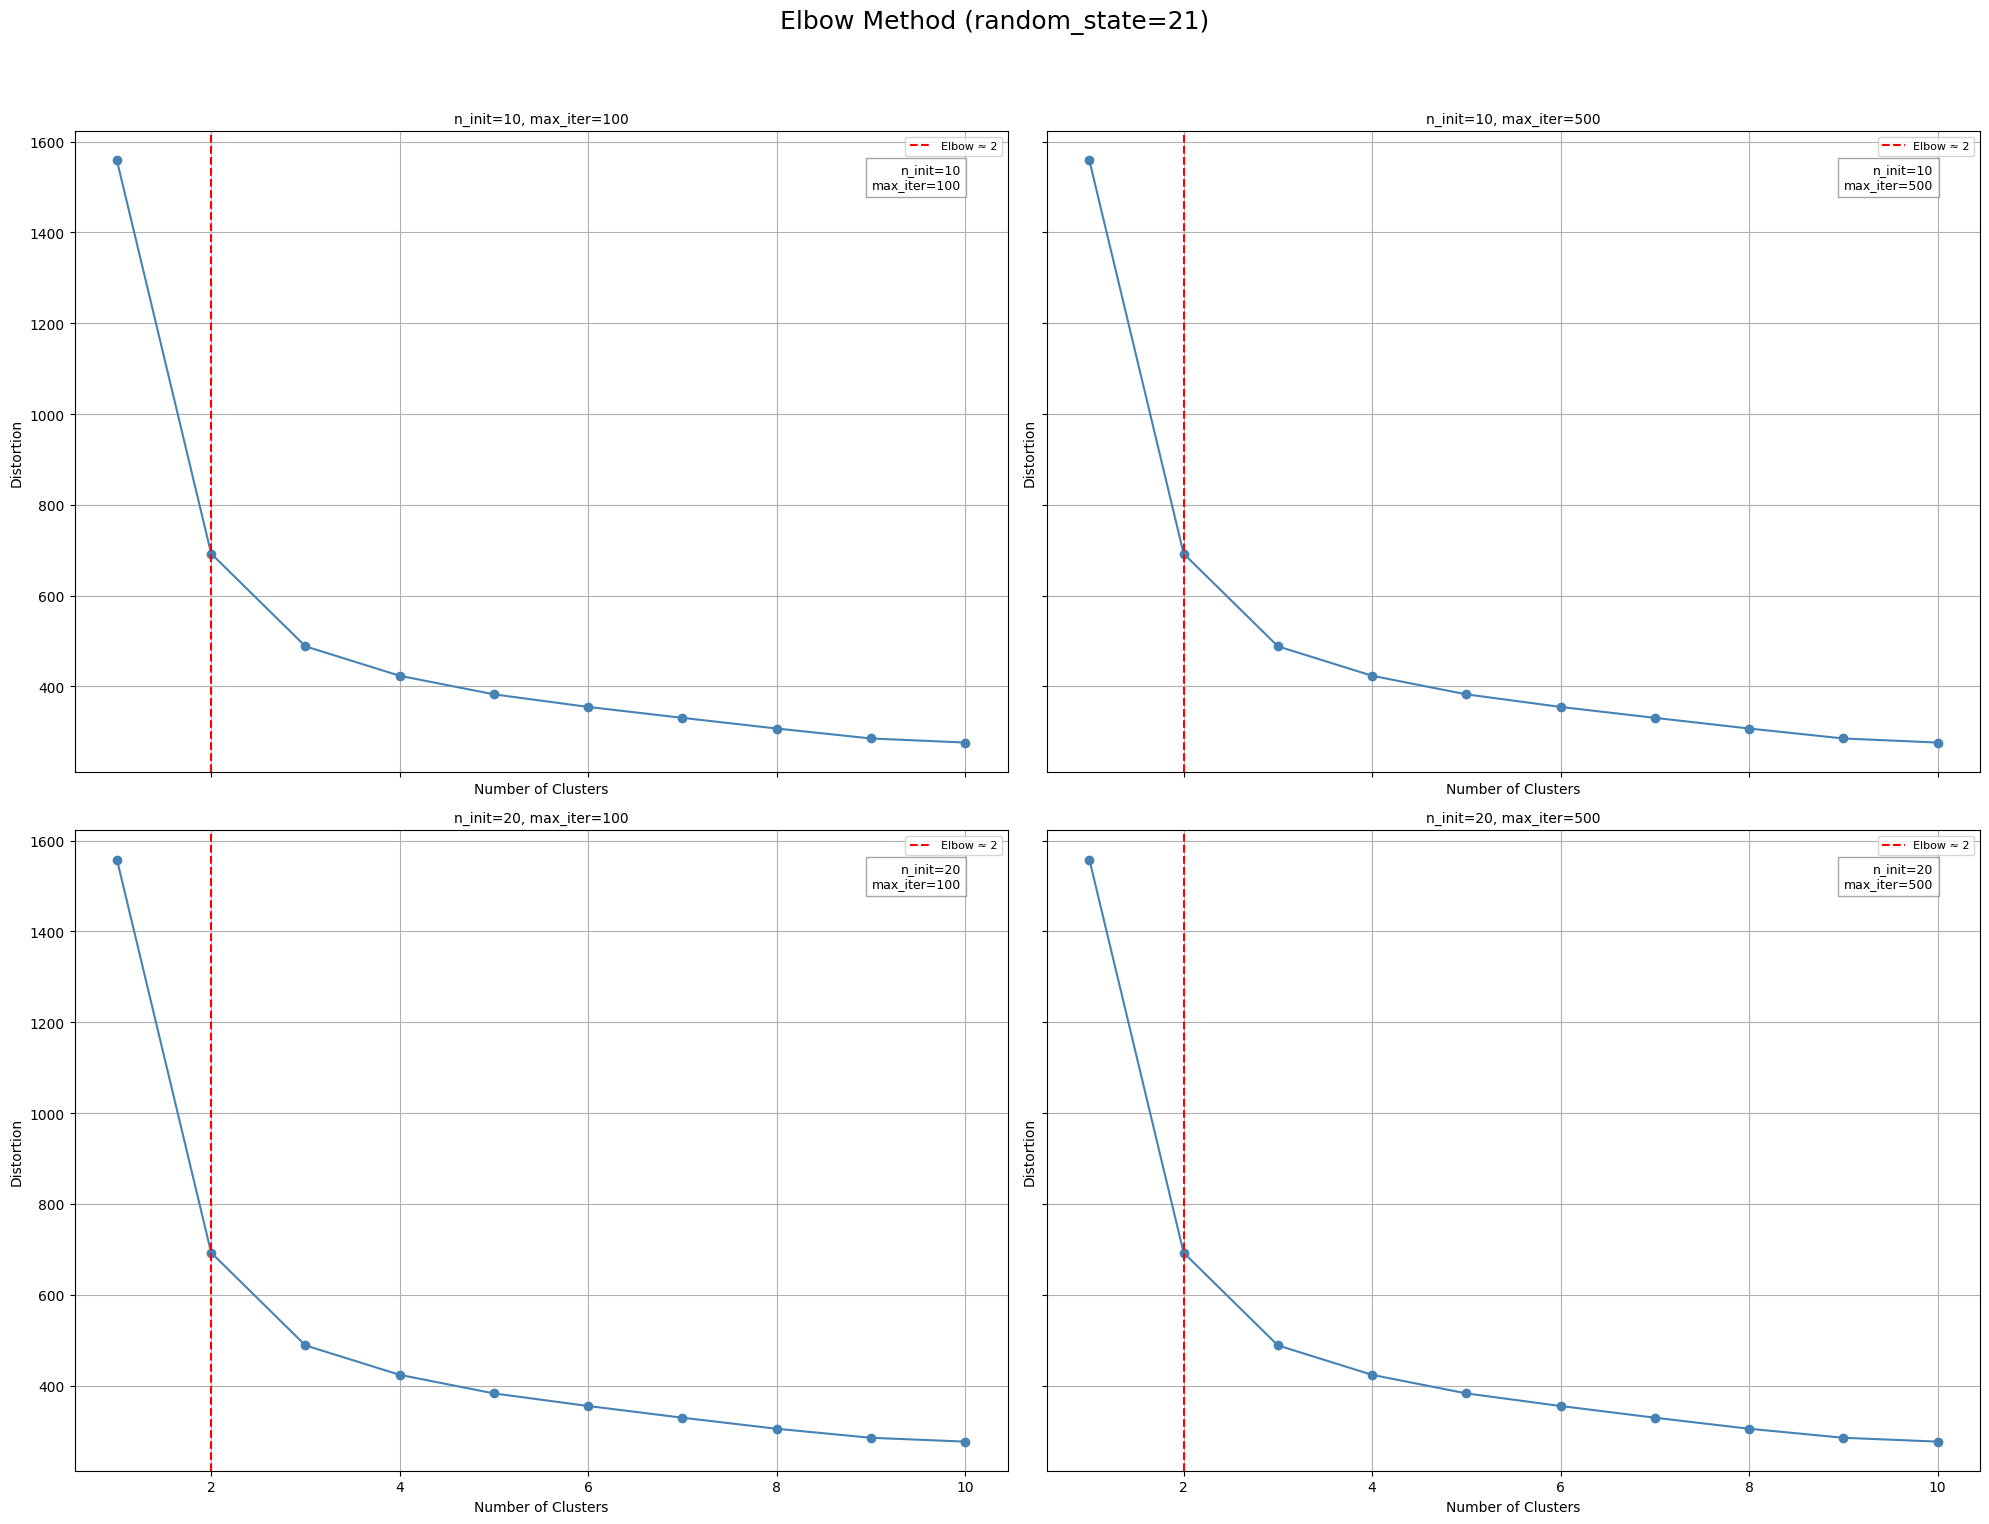


Running elbow plots for random_state=42


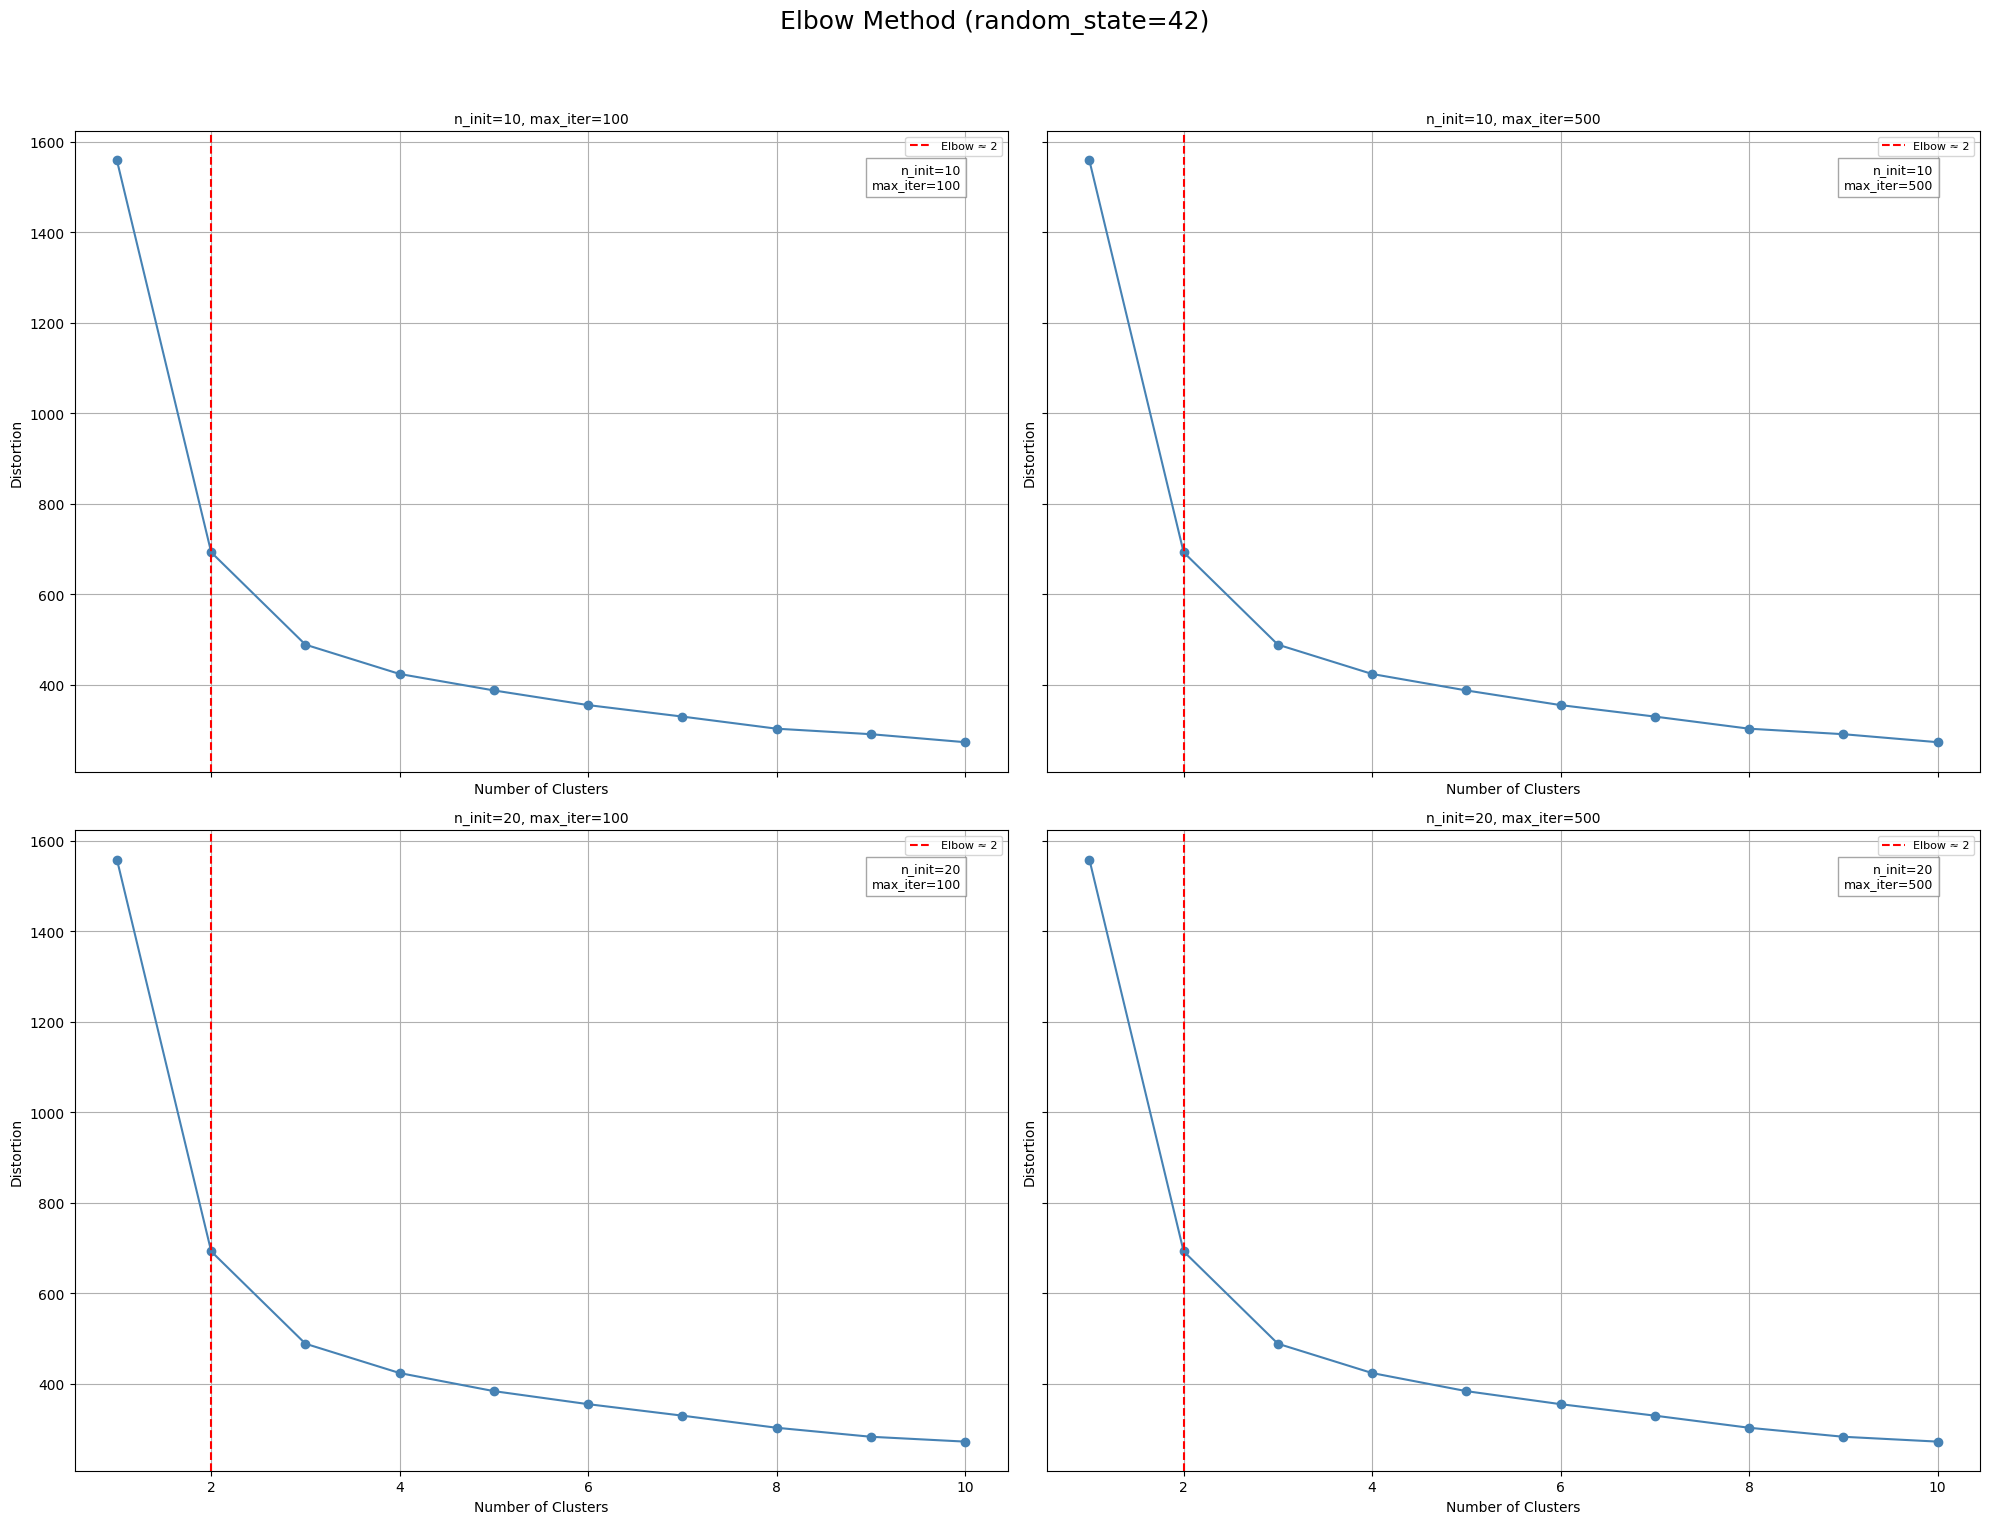


Total execution time: 5.99 seconds


In [20]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input_h1)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [21]:
from sklearn.metrics import silhouette_samples

In [22]:
from matplotlib import cm

In [23]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [25]:
km_c2_ni20_maxi500_h1 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [26]:
ym_c2_ni20_maxi500_h1 = km_c2_ni20_maxi500_h1.fit(cluster_input_h1)

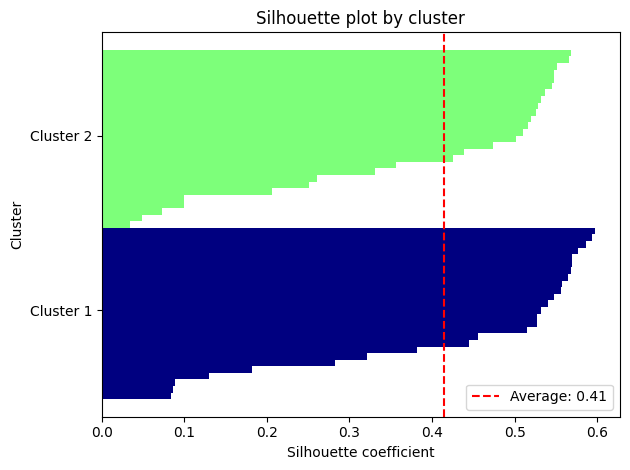

In [27]:
silhoutte_c2_ni20_maxi500_h1 = plot_silhouette(ym_c2_ni20_maxi500_h1, cluster_input_h1)

In [28]:
np.bincount(ym_c2_ni20_maxi500_h1.labels_)

array([26, 27])

In [42]:
c2_ni20_maxi500_h1 = countries_win_h1.copy()

In [43]:
c2_ni20_maxi500_h1['cluster'] = ym_c2_ni20_maxi500_h1.labels_

In [44]:
import country_converter as coco

In [45]:
c2_ni20_maxi500_h1.head()

,Country,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,livestock_prod_min,livestock_prod_max,livestock_prod_last,gdp_mean,gdp_median,...,agr_land_kurtosis,agr_land_trend,gdp_skew,gdp_kurtosis,unemployment_cv,unemployment_growth,unemployment_skew,unemployment_kurtosis,unemployment_trend,cluster
0,Australia,4.582413,4.585987,1.820075,0.054347,4.541165,4.628887,4.578826,6.265112,6.207307,...,0.299427,0.588591,-0.393881,-0.533219,0.160082,-0.625552,-0.801612,-0.565525,-0.116020,1
1,Austria,4.614130,4.615121,1.027869,0.017337,4.606170,4.621044,4.609162,4.614130,4.578480,...,0.008353,-0.419006,-0.097436,-0.278300,-0.819195,0.106095,-0.692671,-0.738355,0.196037,0
2,Belgium,4.636378,4.628887,1.027869,0.017337,4.606170,4.661551,4.627910,4.822310,4.769837,...,0.405169,0.417570,0.111506,-0.422868,-0.330153,-0.333585,0.498431,-0.395456,-0.162014,0
3,Brazil,4.672829,4.675629,1.646041,0.038379,4.603168,4.720283,4.720283,7.633289,7.536279,...,-0.670852,-0.592022,-0.013102,-0.531518,-0.002502,-0.315351,-0.801612,-0.453348,-0.536320,1
4,Bulgaria,4.582413,4.585987,1.688591,0.046573,4.541165,4.621044,4.578826,3.868975,3.821004,...,-0.264767,0.329780,0.304080,-0.121597,1.049767,-0.822929,0.072871,-0.465255,-0.597567,0


In [46]:
c2_ni20_maxi500_h1['ISO_A3'] = coco.convert(names=c2_ni20_maxi500_h1['Country'], to='ISO3')

In [47]:
clusters_c2_ni20_maxi500_h1 = c2_ni20_maxi500_h1[['Country', 'ISO_A3', 'cluster']].copy()

In [48]:
clusters_c2_ni20_maxi500_h1.loc[:, 'Continent'] = coco.convert(
    names=clusters_c2_ni20_maxi500_h1['Country'], to='continent'
)

In [49]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [50]:
print_cluster_groups(clusters_c2_ni20_maxi500_h1)


🌍 Cluster 0 (26 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malaysia (Asia)
 - Malta (Europe)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Peru (America)
 - Portugal (Europe)
 - Romania (Europe)
 - Singapore (Asia)
 - Slovakia (Europe)
 - Slovenia (Europe)
 - Spain (Europe)
 - Switzerland (Europe)

🌍 Cluster 1 (27 countries):
 - Australia (Oceania)
 - Brazil (America)
 - Canada (America)
 - Chile (America)
 - Colombia (America)
 - Czech (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Hungary (Europe)
 - Iceland (Europe)
 - India (Asia)
 - Japan (Asia)
 - Mexico (America)
 - Norway (Europe)
 - Paraguay (America)
 - Philippines (Asia)
 - Poland (Europe)
 - Russia (Europe)
 - Serbia (Europe)
 - South Africa (Africa)

In [51]:
clusters_c2_ni20_maxi500_h1['Country'] = clusters_c2_ni20_maxi500_h1['Country'].replace('Czech','Czech Republic')

In [75]:
clusters_c2_ni20_maxi500_h1.to_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_h1.parquet')

#### cluster_input_h2

In [54]:
cluster_input_h2 = countries_win_h2.select_dtypes(include='number')
cluster_input_h2.head()

,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,livestock_prod_min,livestock_prod_max,livestock_prod_last,gdp_mean,gdp_median,gdp_std,...,agr_land_cv,agr_land_min,agr_land_max,agr_land_last,agr_land_growth,agr_land_skew,agr_land_kurtosis,agr_land_trend,gdp_skew,gdp_kurtosis
0,4.582413,4.585987,1.820075,0.054347,4.541165,4.628887,4.578826,6.265112,6.207307,4.529963,...,0.364734,0.447020,0.562871,0.566279,0.433187,-0.755144,0.299427,0.588591,-0.393881,-0.533219
1,4.614130,4.615121,1.027869,0.017337,4.606170,4.621044,4.609162,4.614130,4.578480,2.538337,...,-0.055775,-0.282775,-0.282528,-0.312030,-0.547518,0.833938,0.008353,-0.419006,-0.097436,-0.278300
2,4.636378,4.628887,1.027869,0.017337,4.606170,4.661551,4.627910,4.822310,4.769837,2.878367,...,-0.539514,0.402875,0.367441,0.416555,0.181257,-0.755144,0.405169,0.417570,0.111506,-0.422868
3,4.672829,4.675629,1.646041,0.038379,4.603168,4.720283,4.720283,7.633289,7.536279,6.189334,...,0.456347,-0.551558,-0.535051,-0.579753,-0.547518,0.061606,-0.670852,-0.592022,-0.013102,-0.531518
4,4.582413,4.585987,1.688591,0.046573,4.541165,4.621044,4.578826,3.868975,3.821004,2.336594,...,-0.706821,0.538105,0.461314,0.510619,0.293228,0.674399,-0.264767,0.329780,0.304080,-0.121597


In [55]:
countries_win_h2.head()

,Country,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,livestock_prod_min,livestock_prod_max,livestock_prod_last,gdp_mean,gdp_median,...,agr_land_cv,agr_land_min,agr_land_max,agr_land_last,agr_land_growth,agr_land_skew,agr_land_kurtosis,agr_land_trend,gdp_skew,gdp_kurtosis
0,Australia,4.582413,4.585987,1.820075,0.054347,4.541165,4.628887,4.578826,6.265112,6.207307,...,0.364734,0.447020,0.562871,0.566279,0.433187,-0.755144,0.299427,0.588591,-0.393881,-0.533219
1,Austria,4.614130,4.615121,1.027869,0.017337,4.606170,4.621044,4.609162,4.614130,4.578480,...,-0.055775,-0.282775,-0.282528,-0.312030,-0.547518,0.833938,0.008353,-0.419006,-0.097436,-0.278300
2,Belgium,4.636378,4.628887,1.027869,0.017337,4.606170,4.661551,4.627910,4.822310,4.769837,...,-0.539514,0.402875,0.367441,0.416555,0.181257,-0.755144,0.405169,0.417570,0.111506,-0.422868
3,Brazil,4.672829,4.675629,1.646041,0.038379,4.603168,4.720283,4.720283,7.633289,7.536279,...,0.456347,-0.551558,-0.535051,-0.579753,-0.547518,0.061606,-0.670852,-0.592022,-0.013102,-0.531518
4,Bulgaria,4.582413,4.585987,1.688591,0.046573,4.541165,4.621044,4.578826,3.868975,3.821004,...,-0.706821,0.538105,0.461314,0.510619,0.293228,0.674399,-0.264767,0.329780,0.304080,-0.121597


#### Using the elbow method to find the optimal number of clusters

In [56]:
distortions = []

In [57]:
import time

In [58]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


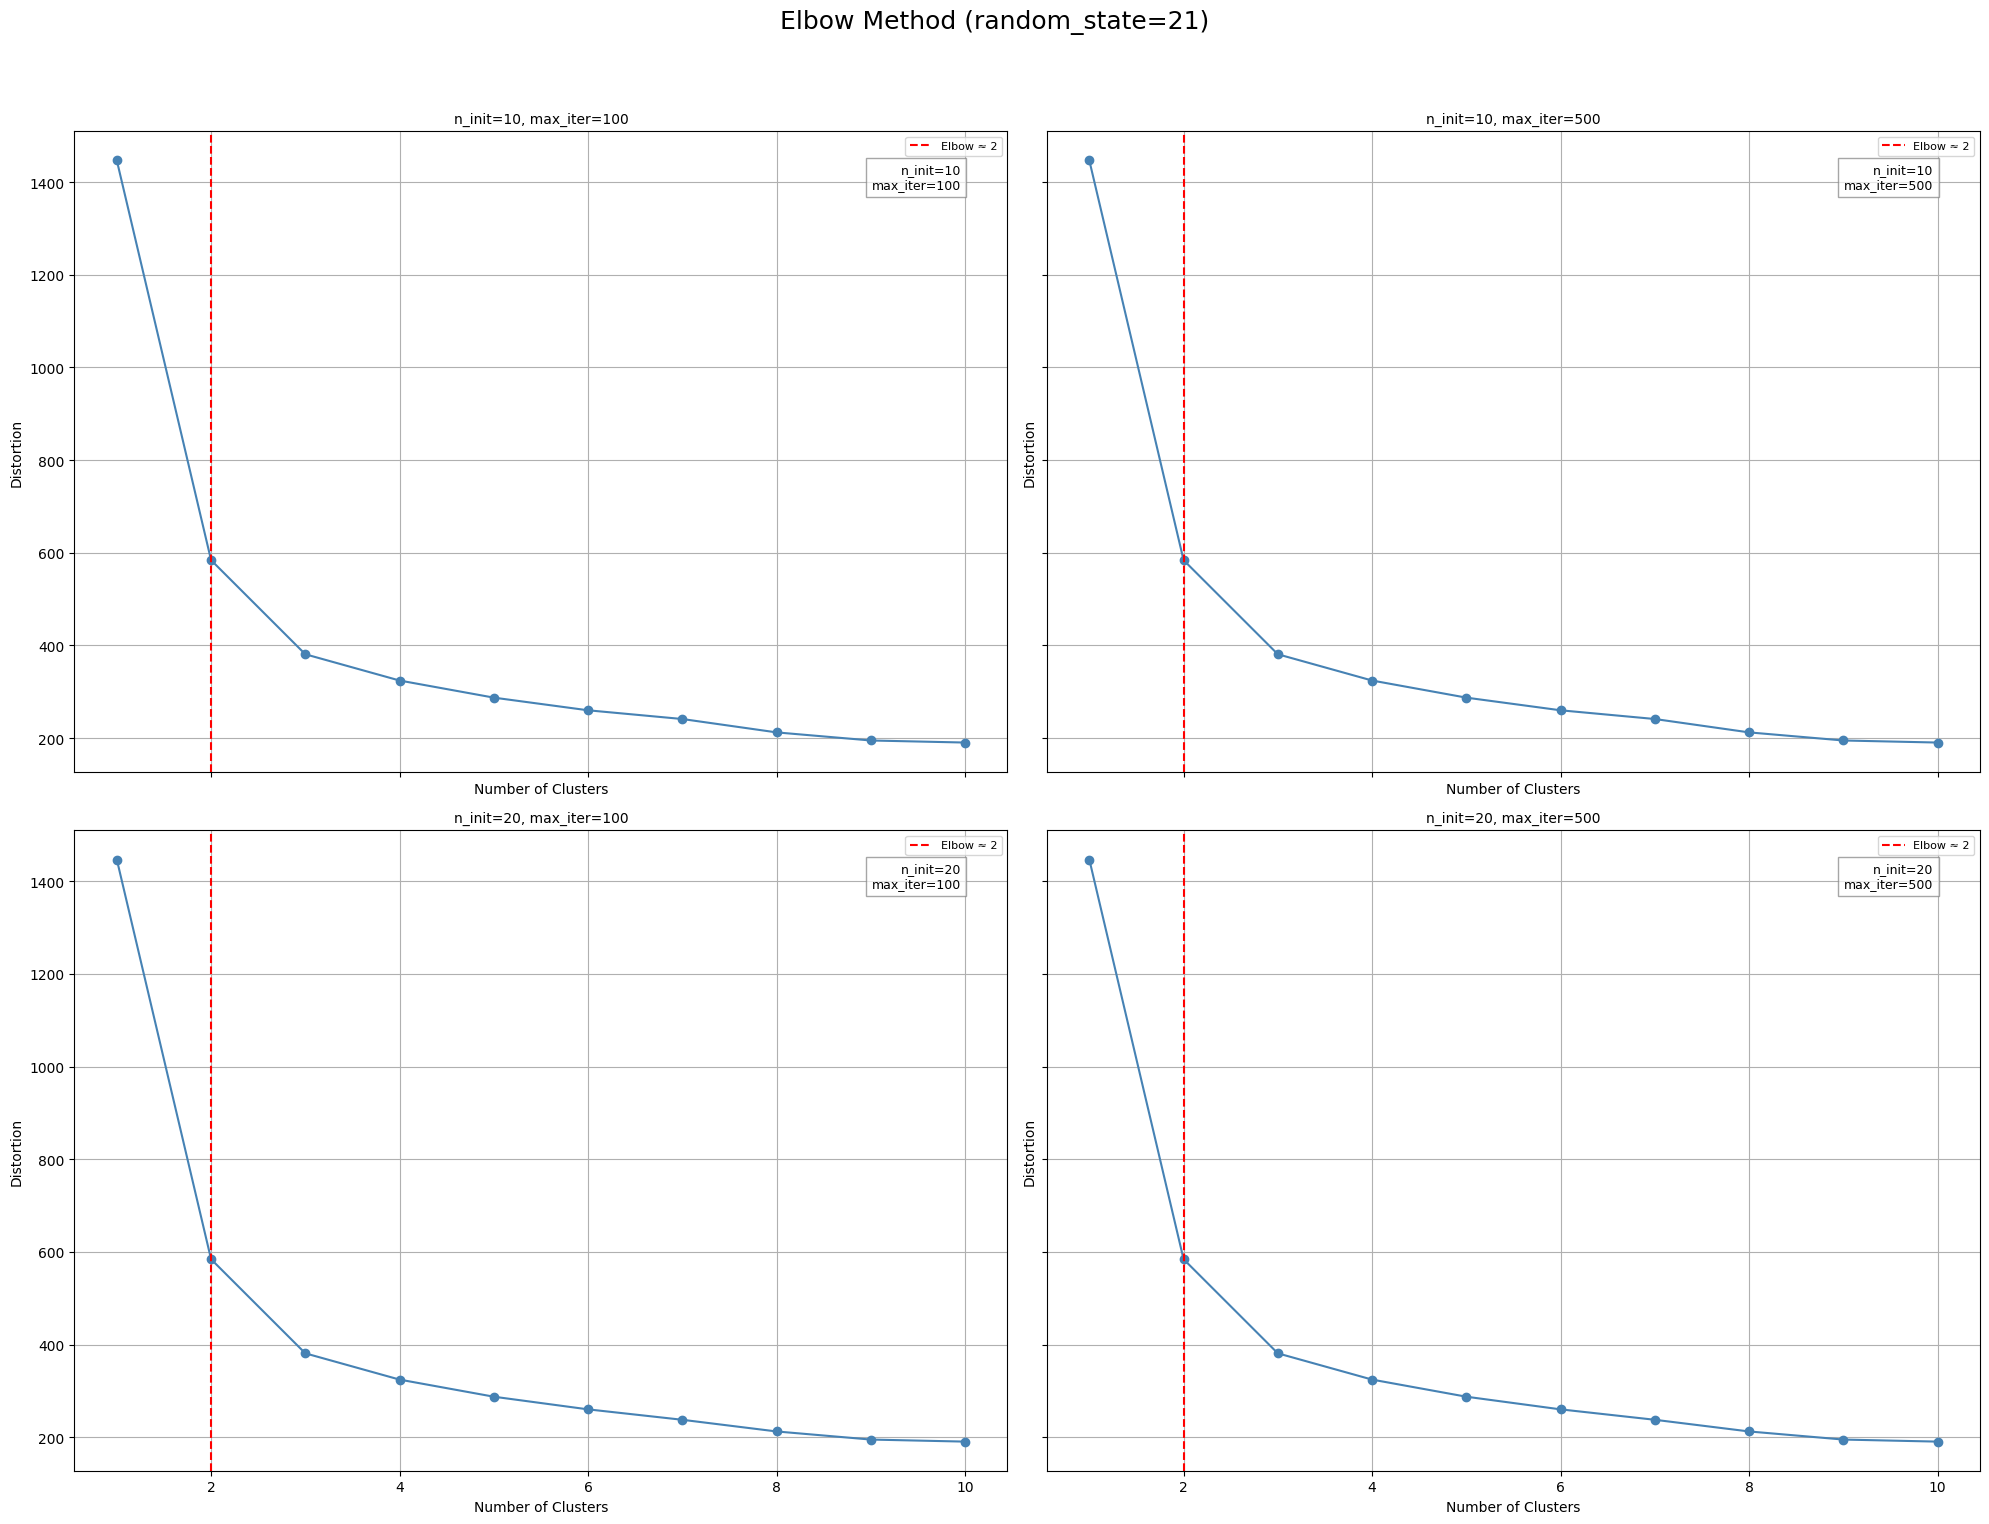


Running elbow plots for random_state=42


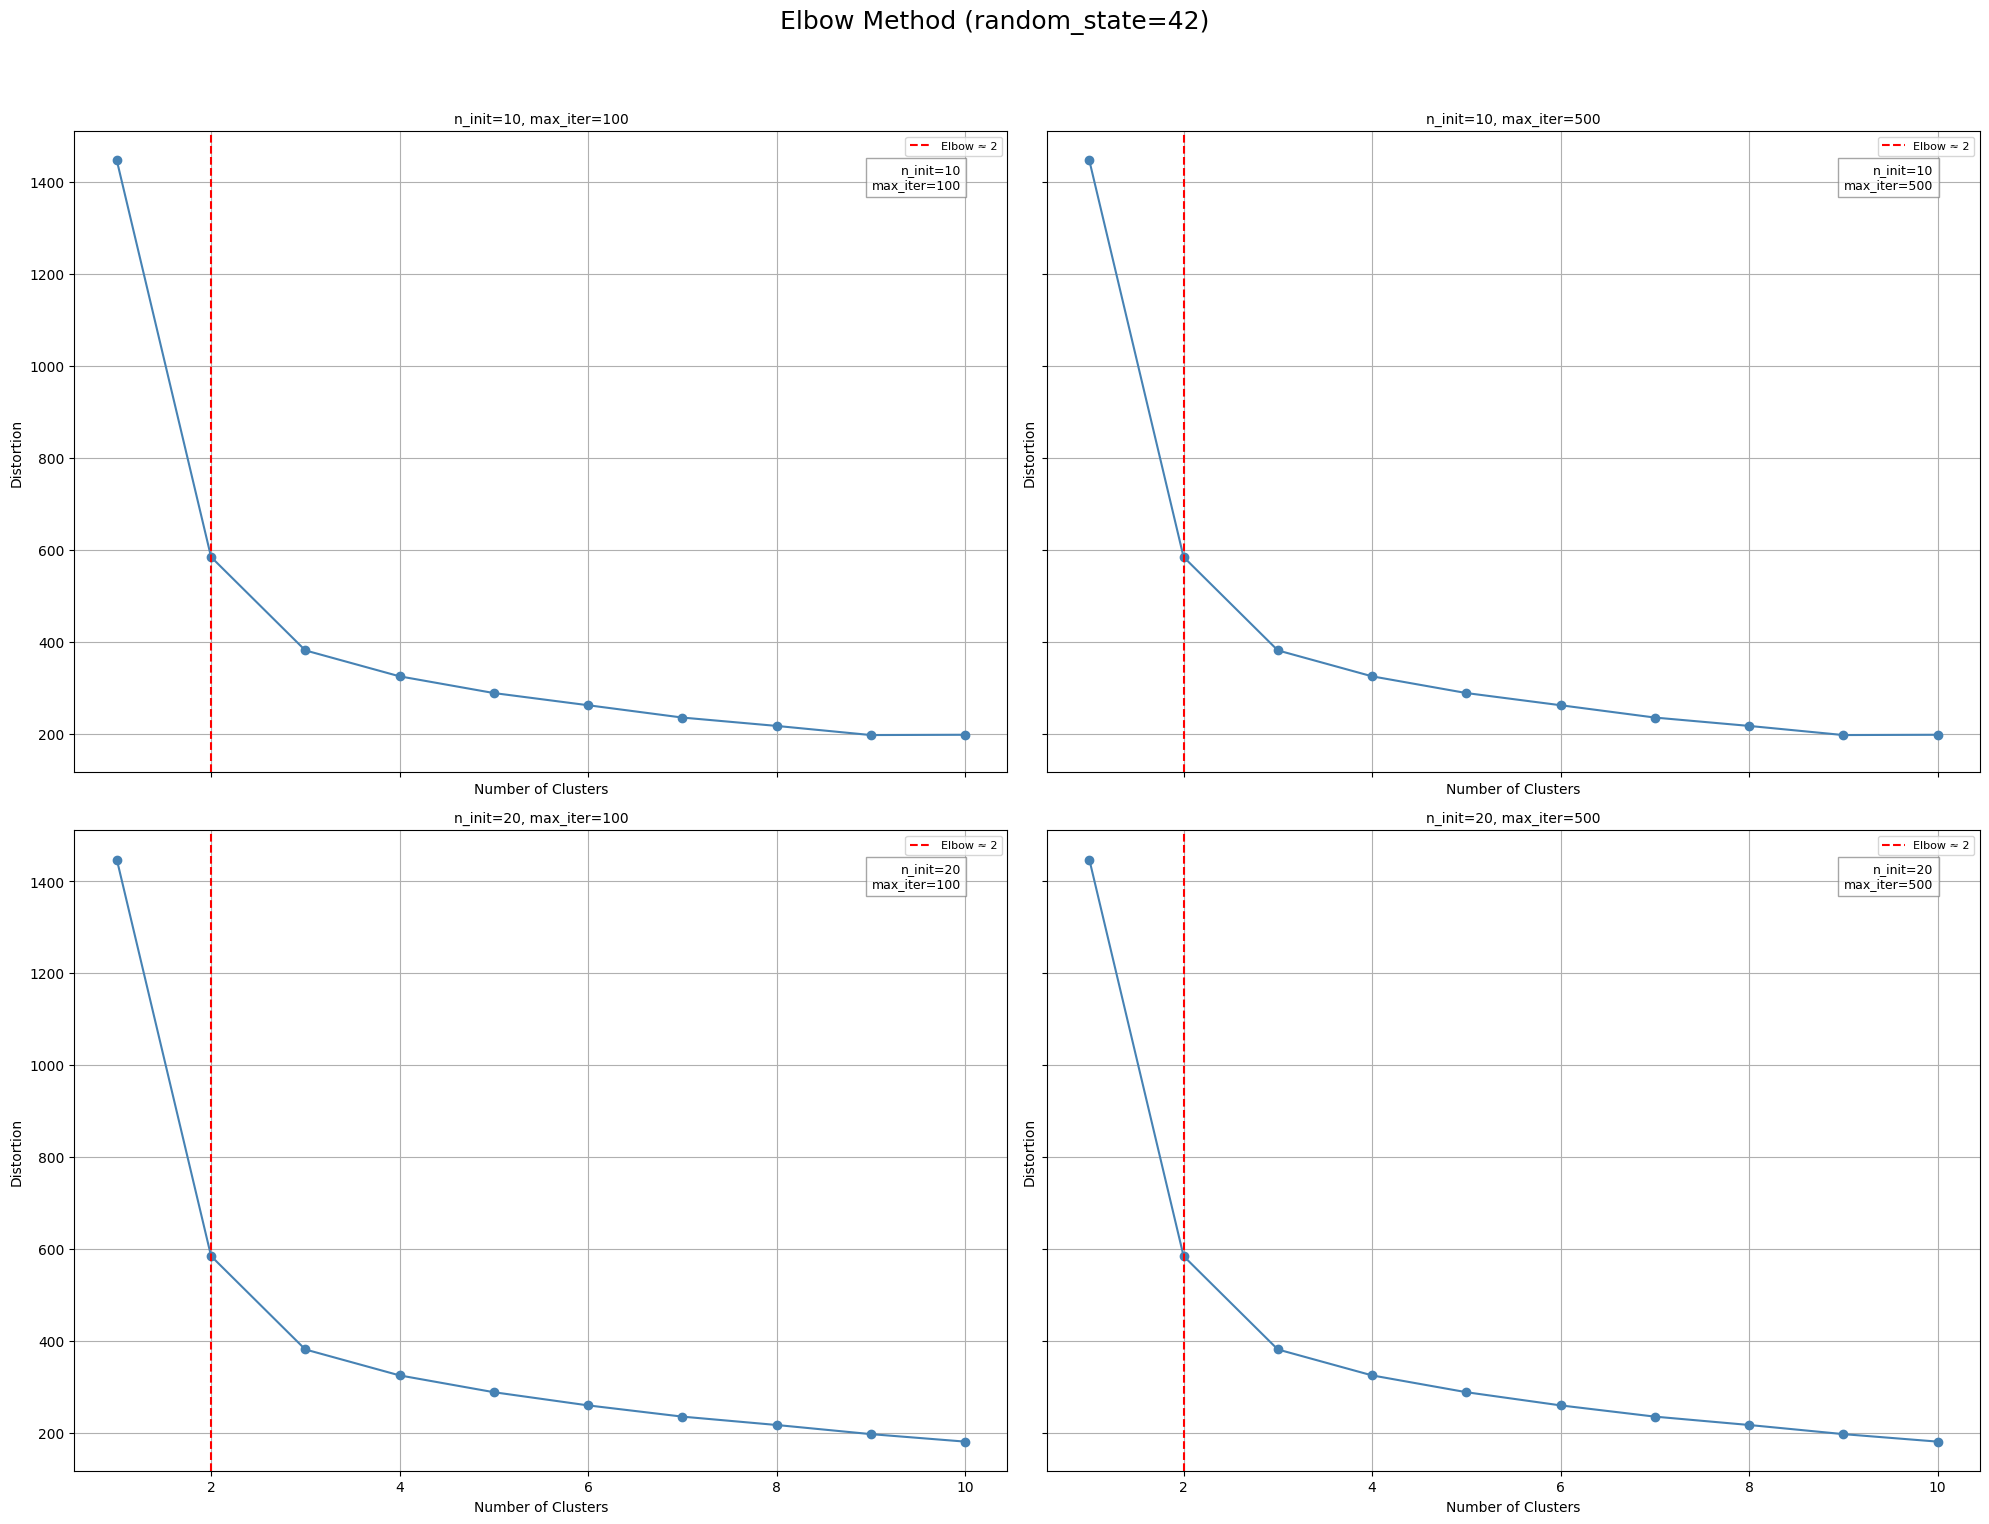


Total execution time: 4.65 seconds


In [59]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input_h2)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

* So the distorsion is less that the previous cluster model
* See what about the silhouette

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [60]:
km_c2_ni20_maxi500_h2 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [62]:
ym_c2_ni20_maxi500_h2 = km_c2_ni20_maxi500_h2.fit(cluster_input_h2)

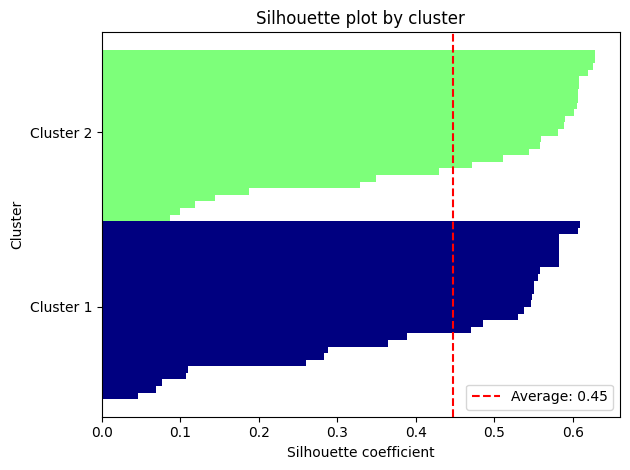

In [63]:
silhoutte_c2_ni20_maxi500_h2 = plot_silhouette(ym_c2_ni20_maxi500_h2, cluster_input_h2)

In [64]:
np.bincount(ym_c2_ni20_maxi500_h2.labels_)

array([27, 26])

In [65]:
c2_ni20_maxi500_h2 = countries_win_h2.copy()

In [66]:
c2_ni20_maxi500_h2['cluster'] = ym_c2_ni20_maxi500_h2.labels_

In [67]:
c2_ni20_maxi500_h2['ISO_A3'] = coco.convert(names=c2_ni20_maxi500_h2['Country'], to='ISO3')

In [68]:
clusters_c2_ni20_maxi500_h2 = c2_ni20_maxi500_h2[['Country', 'ISO_A3', 'cluster']].copy()

In [69]:
clusters_c2_ni20_maxi500_h2.loc[:, 'Continent'] = coco.convert(
    names=clusters_c2_ni20_maxi500_h2['Country'], to='continent'
)

In [70]:
print_cluster_groups(clusters_c2_ni20_maxi500_h2)


🌍 Cluster 0 (27 countries):
 - Australia (Oceania)
 - Brazil (America)
 - Canada (America)
 - Chile (America)
 - Colombia (America)
 - Czech (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Hungary (Europe)
 - Iceland (Europe)
 - India (Asia)
 - Japan (Asia)
 - Mexico (America)
 - Norway (Europe)
 - Paraguay (America)
 - Philippines (Asia)
 - Poland (Europe)
 - Russia (Europe)
 - Serbia (Europe)
 - South Africa (Africa)
 - South Korea (Asia)
 - Sweden (Europe)
 - Thailand (Asia)
 - Turkey (Asia)
 - United Kingdom (Europe)
 - USA (America)

🌍 Cluster 1 (26 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malaysia (Asia)
 - Malta (Europe)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Peru (America)
 - Portugal (Europe)
 -

In [71]:
clusters_c2_ni20_maxi500_h2['Country'] = clusters_c2_ni20_maxi500_h2['Country'].replace('Czech','Czech Republic')

In [76]:
clusters_c2_ni20_maxi500_h2.to_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_h2.parquet')

In [3]:
clusters_c2_ni20_maxi500_h2 = pd.read_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_h2.parquet')

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [4]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_index_winsorized.parquet')

In [5]:
df_hpi_winsorized.shape

(15, 53)

In [6]:
clusters_c2_ni20_maxi500_h2.shape

(53, 4)

In [78]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [79]:
missing_countries_5 = find_countries_missing_from_clusters(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2)

Countries in HPI that are missing from the cluster DataFrame:
 - Year


### Apply transformation over hpi index
* Apply winsorization
* Apply round to two decimal
* Plot boxplot for every year

In [80]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

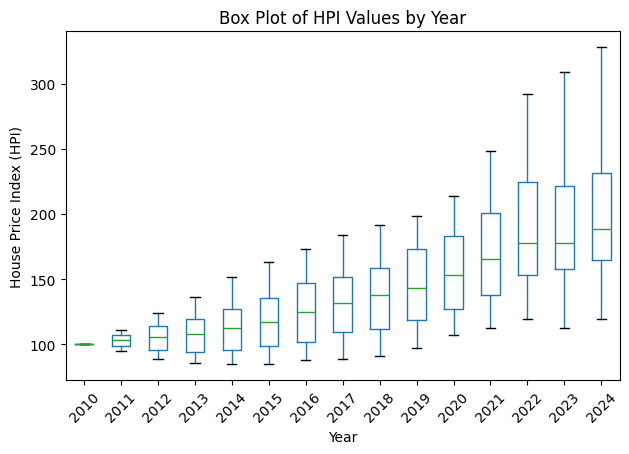

In [81]:
plot_hpi_boxplots_by_year(df_hpi_winsorized)

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [7]:
import random

In [8]:
def estimate_hpi_by_cluster_sampling(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Estimates synthetic HPI values for a randomly excluded country from a selected cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to use for sampling
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    - sample_size: Size of each sample (default: 30)
    - n_samples: Number of samples to generate (default: 1000)
    - plot: Whether to show histograms for each year (default: True)
    - seed: Optional random seed for reproducibility

    Returns:
    - synthetic_hpi: dict with estimated HPI values per year
    - excluded_country: name of the country left out
    - actual_values: dict with real HPI values of the excluded country
    """

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Step 1: Get countries in the selected cluster that are present in the HPI DataFrame
    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]
    
    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data to perform exclusion and sampling.")
    
    # Step 2: Randomly exclude one country from those present in HPI
    excluded_country = random.choice(cluster_countries)
    sampling_countries = [c for c in cluster_countries if c != excluded_country]

    print(f"🔍 Cluster {cluster_id} selected. Excluding country: {excluded_country}")
    print(f"📊 Sampling from countries: {sampling_countries}")

    # Step 3: Prepare output containers
    synthetic_hpi = {}
    actual_values = {}

    # Step 4: Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]

        # Get HPI values for sampling countries
        values = row[sampling_countries].dropna().values

        # Get actual value of excluded country
        actual_value = row.get(excluded_country, np.nan)
        actual_values[year] = actual_value

        if len(values) == 0:
            print(f"⚠️ No HPI data available for cluster peers in year {year}")
            synthetic_hpi[year] = np.nan
            continue

        # Print available HPI values for sampling
        print(f"\n📅 Year {year} - Available HPI values for sampling:")
        print(values)

        # Generate sampling distribution
        sample_means = []
        cumulative_means = []
        for i in range(n_samples):
            sample = np.random.choice(values, size=sample_size, replace=True)
            mean = np.mean(sample)
            sample_means.append(mean)
            cumulative_means.append(np.mean(sample_means))  # track convergence

        # Compute 95% confidence interval
        lower_bound = np.percentile(sample_means, 2.5)
        upper_bound = np.percentile(sample_means, 97.5)

        # Plot side-by-side: histogram + convergence
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Histogram with confidence interval
        axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
        axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {excluded_country}")
        axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
        axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
        axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
        axes[0].set_xlabel("Sample Mean HPI")
        axes[0].set_ylabel("Frequency")
        axes[0].legend()
        axes[0].grid(True)

        # Convergence plot
        axes[1].plot(cumulative_means, color='purple')
        axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
        axes[1].set_title("Mean Convergence Over Iterations")
        axes[1].set_xlabel("Iteration")
        axes[1].set_ylabel("Cumulative Mean")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()
        # Store synthetic HPI value
        synthetic_hpi[year] = np.mean(sample_means)

    return synthetic_hpi, excluded_country, actual_values

### Sampling experiment with seed 23

🔍 Cluster 0 selected. Excluding country: United Kingdom
📊 Sampling from countries: ['Australia', 'Brazil', 'Canada', 'Chile', 'Colombia', 'Czech Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Iceland', 'India', 'Japan', 'Mexico', 'Norway', 'Philippines', 'Poland', 'Russia', 'Serbia', 'South Africa', 'South Korea', 'Sweden', 'Thailand', 'Turkey', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


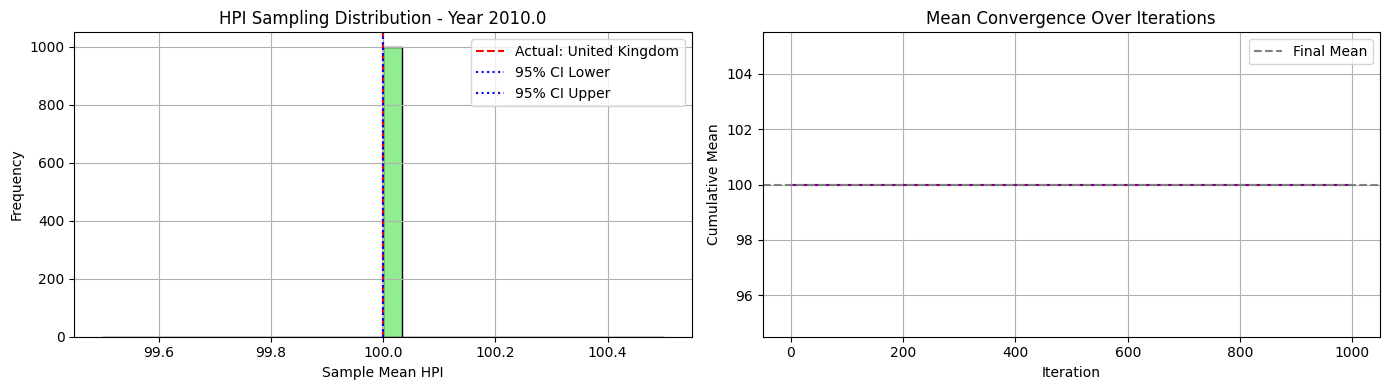


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 105.75 110.52 107.89 100.02  98.29 105.69 102.42  96.56
 105.5  110.52 100.07 105.8  108.01 105.57 100.08  94.49  97.62 103.59
 105.23 102.58 104.26 108.8   97.24]


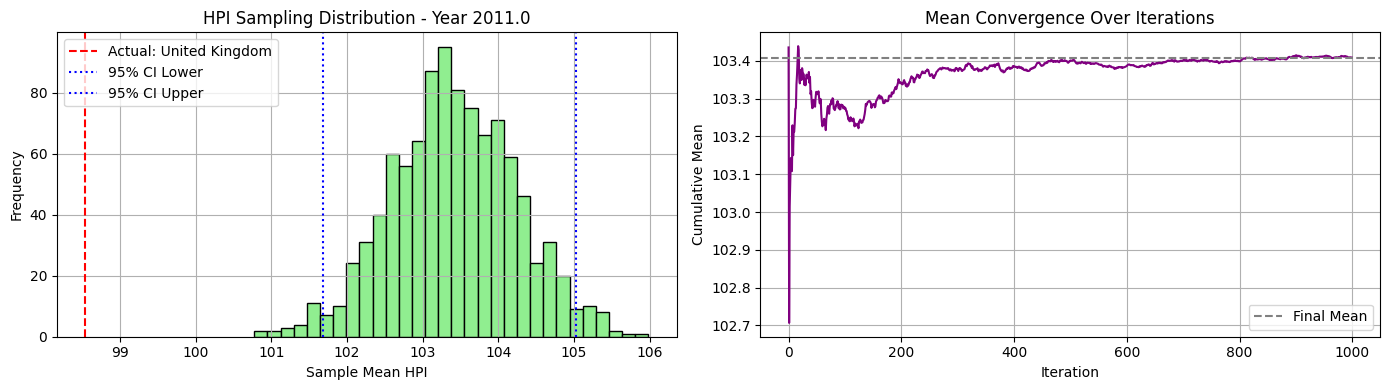


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 110.62 124.02 118.79  98.56  95.67 105.11 105.48  92.98
 112.38 124.02  99.19 109.17 115.34 114.94  96.58  91.1   95.68 108.41
 108.25 103.86 107.63 120.68 101.82]


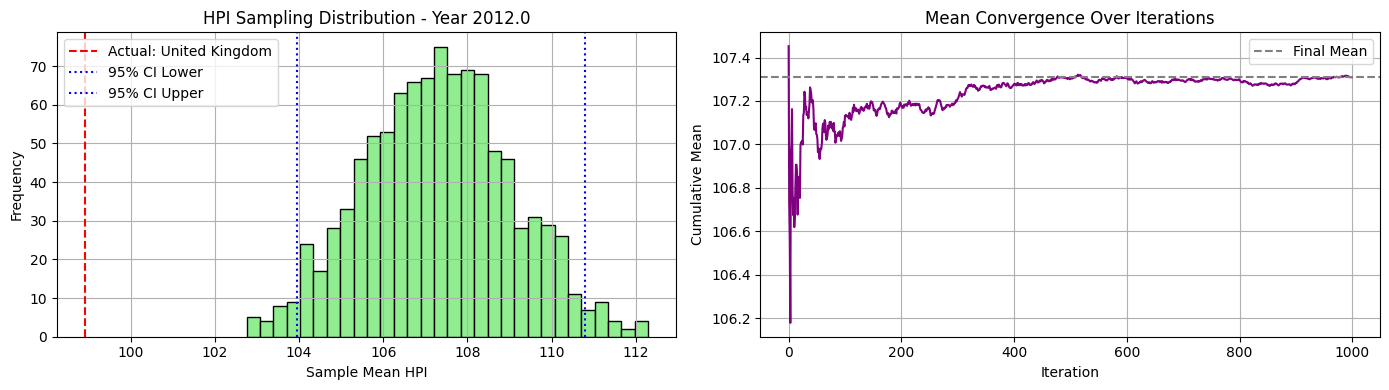


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 112.76 136.52 130.06  98.58  99.37 103.13 108.68  90.58
 119.18 136.52 100.81 114.75 119.98 127.86  92.35  94.32  90.62 115.41
 107.8  109.22 115.99 134.46 111.83]


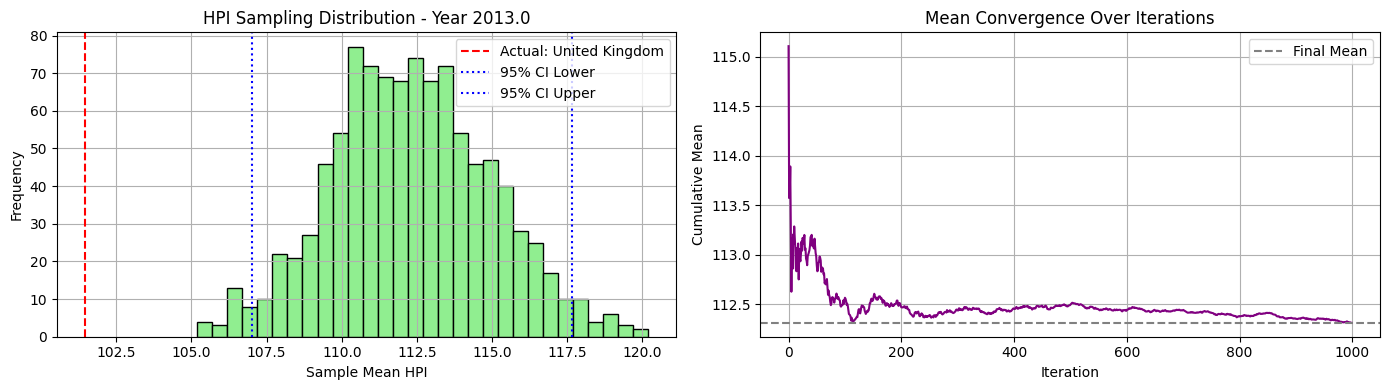


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 118.86 151.67 140.75 101.   103.12 101.58 111.85  94.37
 128.94 151.67 102.38 119.64 123.24 142.76  93.27  95.84  95.77 123.99
 109.43 119.52 127.07 151.25 118.88]


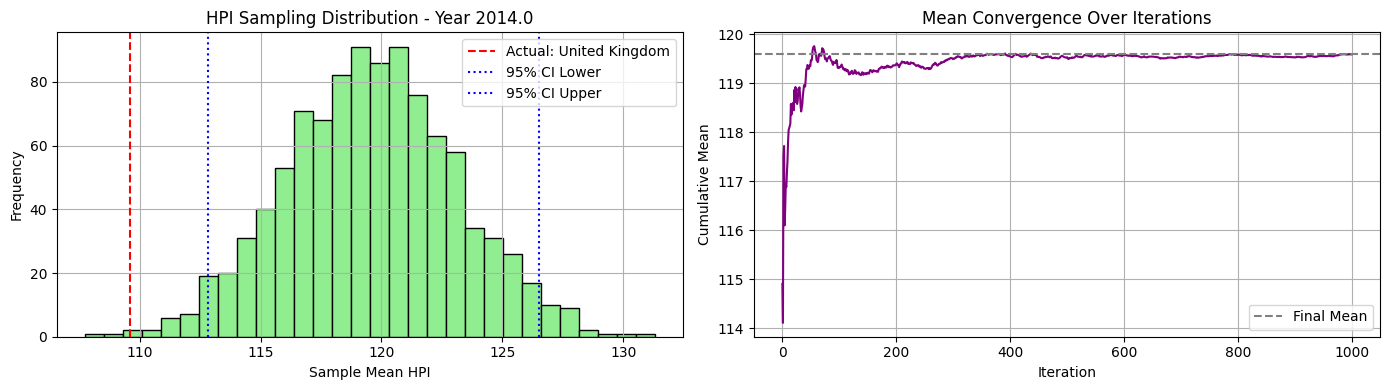


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 128.43 162.89 152.93 105.01 110.29 100.22 117.12 106.75
 139.74 162.89 104.86 129.39 130.76 157.04  94.69  97.    99.5  131.8
 113.08 135.2  136.   162.89 125.18]


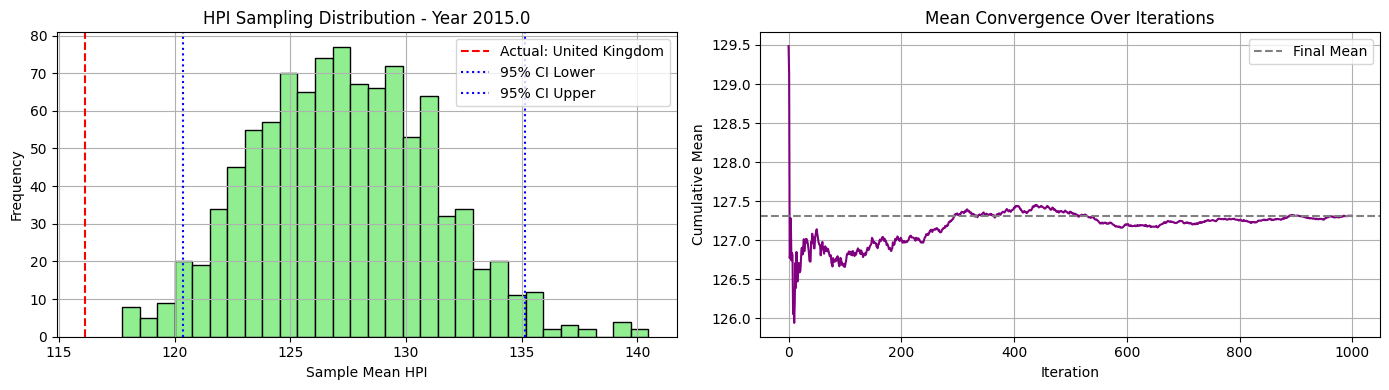


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 148.66 172.75 167.48 112.52 115.5  101.25 125.93 121.03
 154.59 172.75 107.18 138.82 139.95 172.75  96.44  91.86 110.62 138.22
 116.09 146.34 142.4  172.75 131.88]


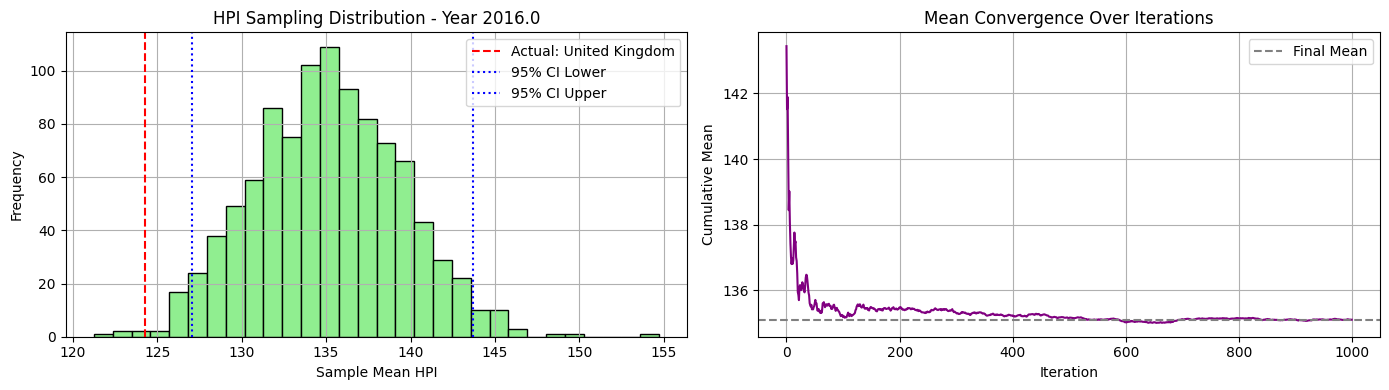


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 172.3  183.99 178.56 125.7  120.63 104.46 133.62 135.84
 183.99 183.99 109.91 149.69 146.91 178.82 100.16  88.54 115.3  143.94
 117.6  156.06 146.48 183.99 139.61]


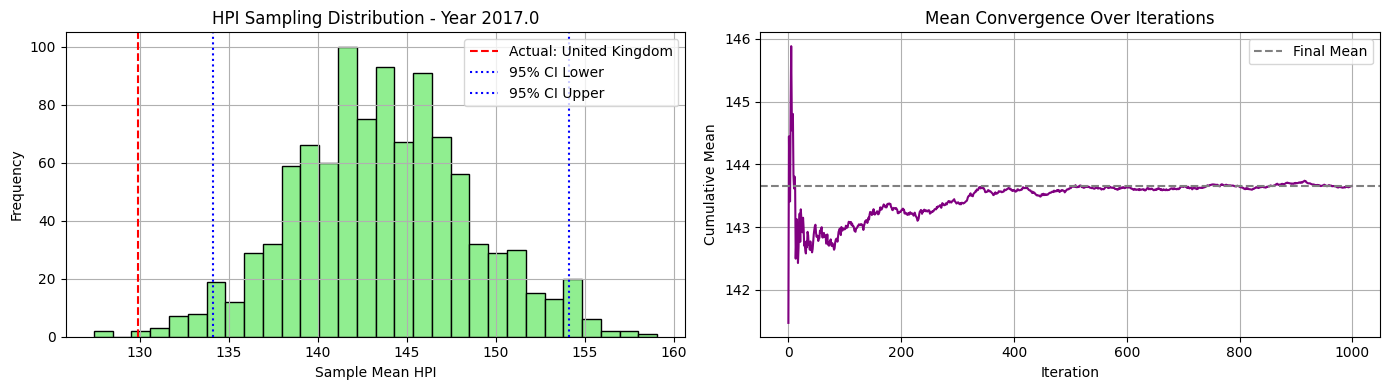


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 178.24 191.85 188.24 136.52 126.31 107.52 142.52 155.3
 191.85 191.85 112.04 162.97 149.04 183.82 106.75  90.72 123.06 148.96
 120.22 154.6  153.9  191.85 147.35]


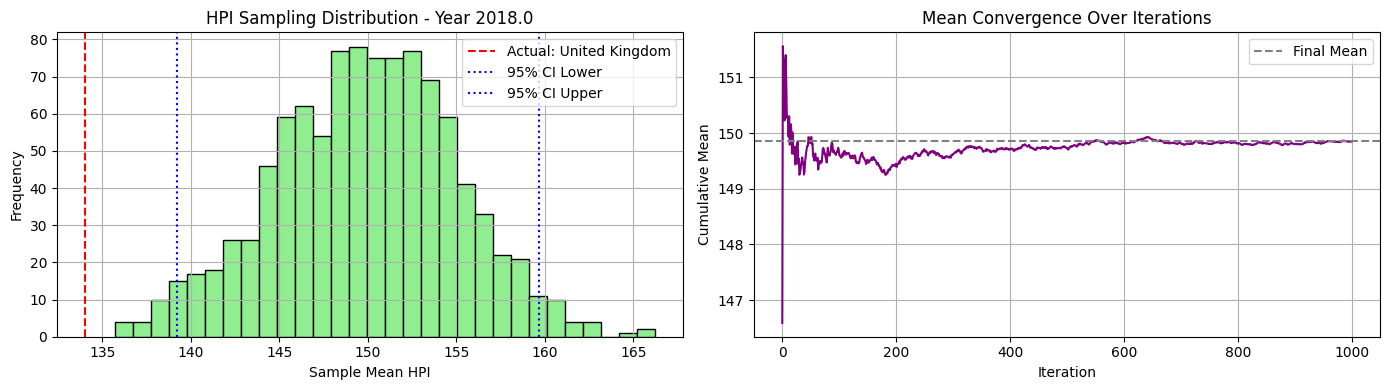


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 179.4  198.37 198.37 149.02 129.62 111.1  150.75 181.64
 198.37 198.37 113.84 176.92 152.73 195.26 116.01  97.25 135.77 152.69
 121.93 158.44 155.1  198.37 153.14]


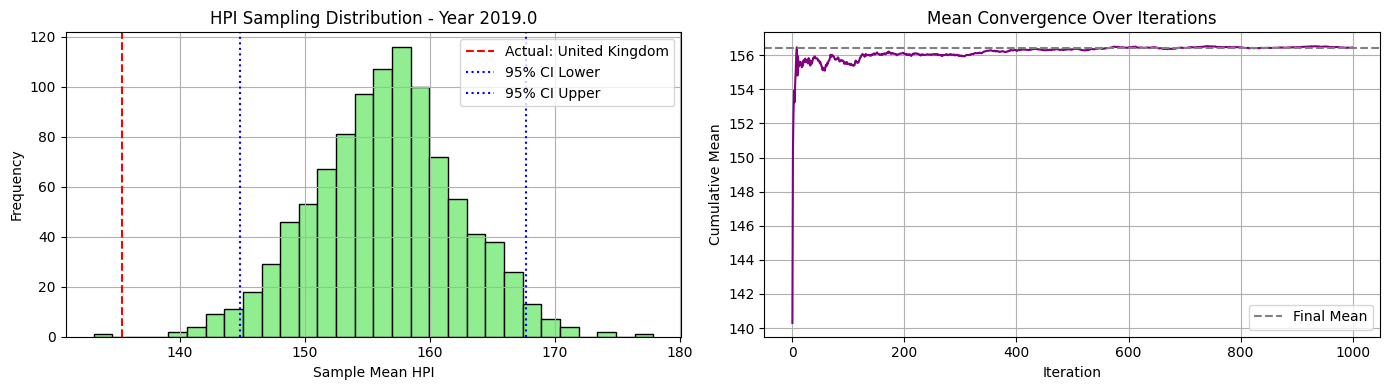


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 190.73 213.74 203.12 161.56 136.24 116.89 162.48 190.63
 213.74 213.74 113.93 187.18 159.24 213.74 128.18 106.71 149.28 156.31
 126.56 165.09 160.6  213.74 163.52]


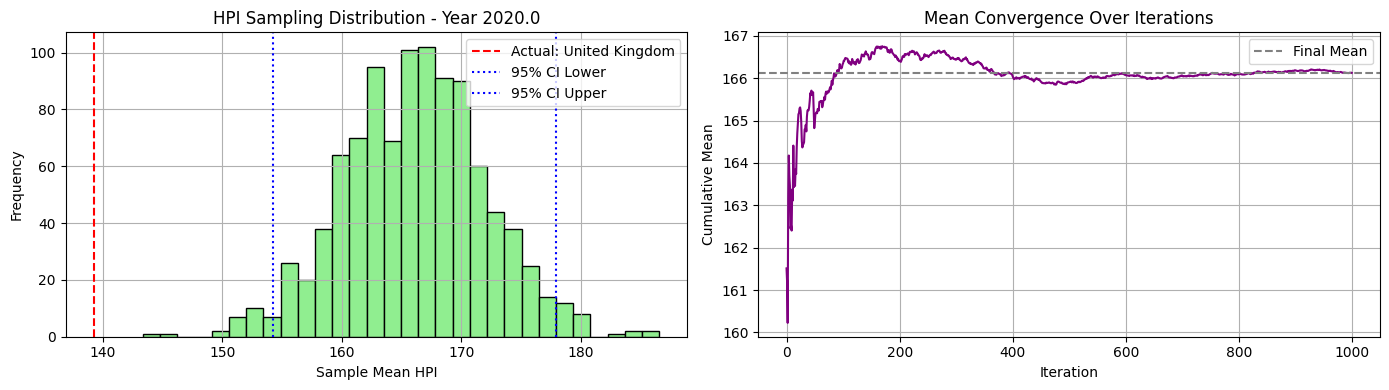


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 214.88 248.26 214.9  193.46 152.2  124.38 181.28 222.1
 248.26 248.26 120.7  201.94 175.91 211.74 139.92 121.41 166.04 166.82
 143.73 181.79 164.23 248.26 188.56]


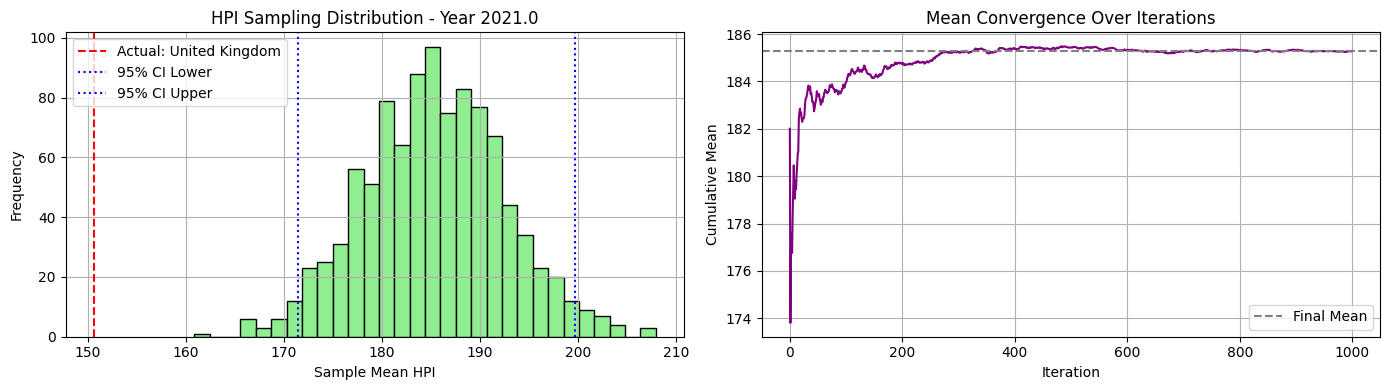


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 235.32 292.18 230.   226.15 151.49 132.1  190.42 271.5
 292.18 292.18 130.84 219.93 185.13 223.73 156.43 155.16 191.49 174.03
 153.22 188.27 169.16 292.18 213.  ]


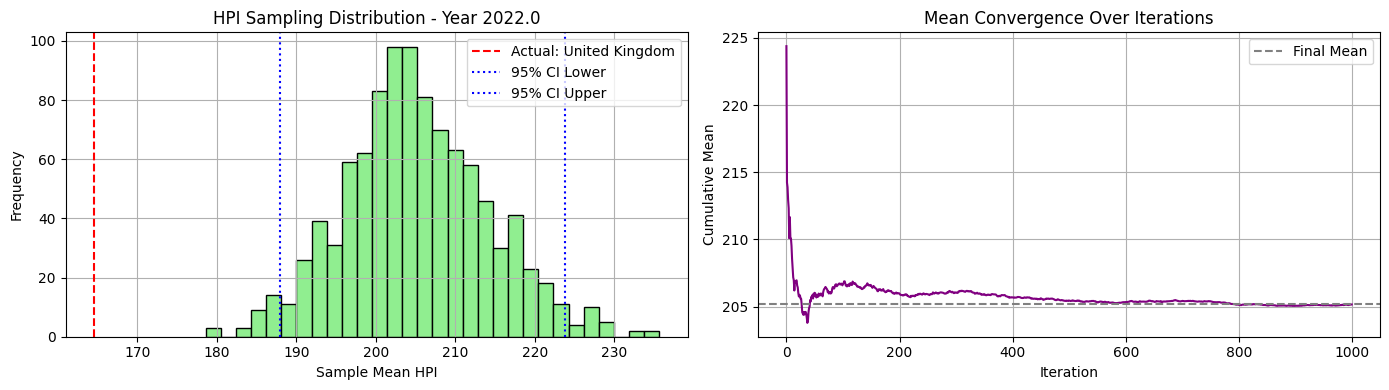


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 221.05 309.37 245.75 222.4  151.24 131.52 174.25 290.98
 309.37 309.37 134.8  243.89 184.12 248.04 170.23 157.88 209.99 176.62
 143.99 178.36 174.79 309.37 221.72]


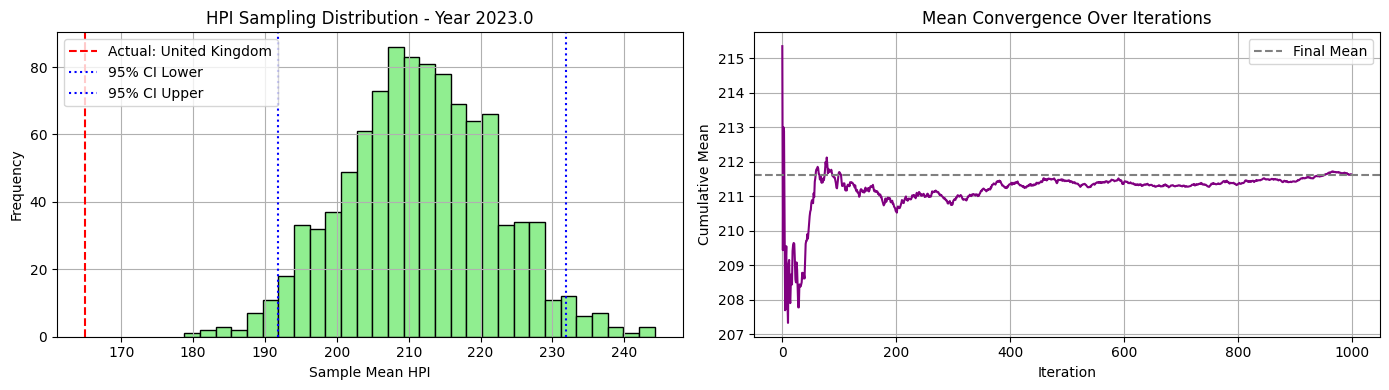


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 217.35 328.24 269.02 233.42 156.73 126.68 171.5  328.1
 328.24 328.24 138.61 266.38 189.05 256.03 195.72 186.66 220.7  178.1
 142.46 178.49 178.06 328.24 231.23]


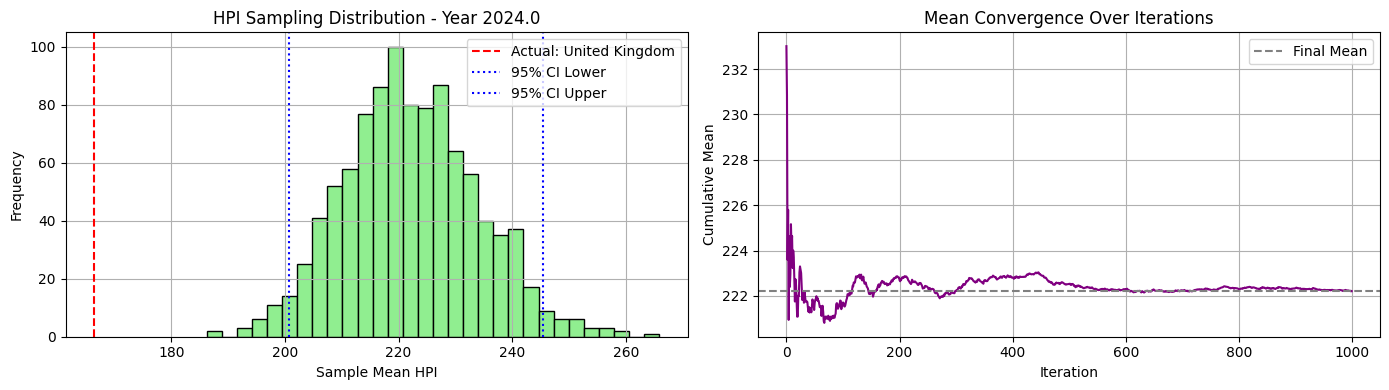

In [9]:
synthetic_c2_ni20_maxi500_h2_23_00, excluded_c2_ni20_maxi500_h2_23_00, actual_c2_ni20_maxi500_h2_23_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=0, seed=23)

🔍 Cluster 1 selected. Excluding country: Spain
📊 Sampling from countries: ['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Israel', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New Zealand', 'Peru', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'Switzerland']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


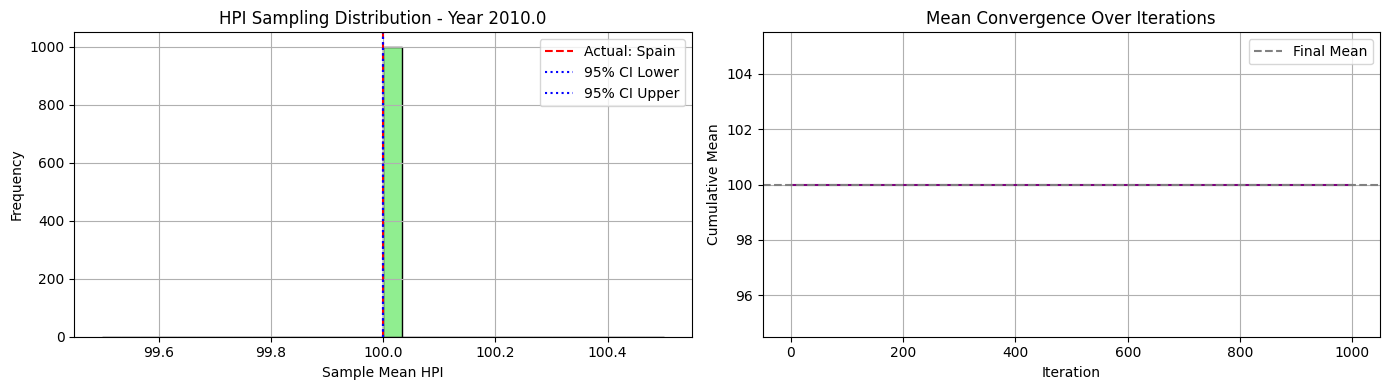


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58  94.49 100.16  96.68 108.47 103.17  94.53  94.49 110.52
 101.36 110.42 106.6  103.68 109.83  98.63  98.02 100.75 110.52  95.1
  94.49 109.46  98.46 102.72 107.51]


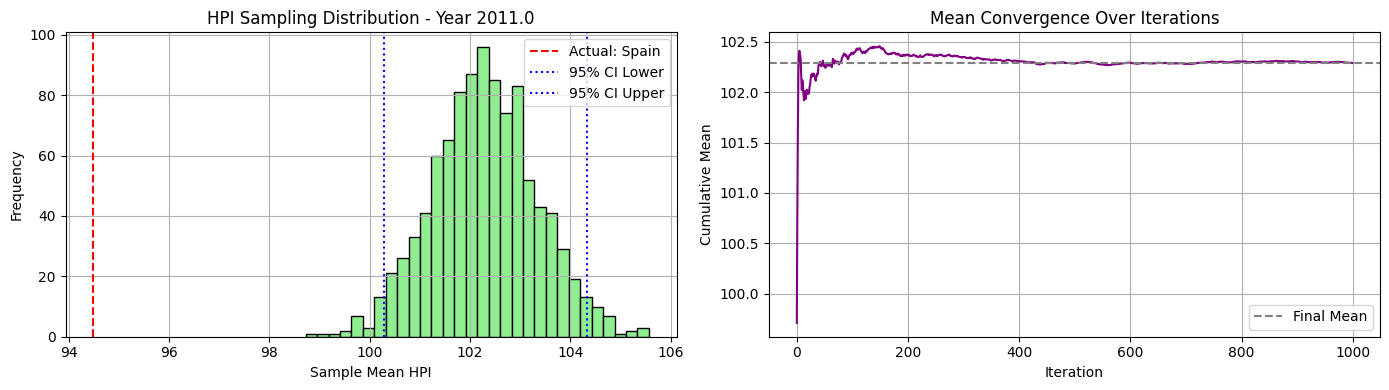


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  92.69  98.62  91.54 116.34 105.64  88.37  88.37 114.1
  98.77 113.71 106.36 108.03 124.02 101.62  91.44 105.25 124.02  88.37
  88.37 112.02  95.73  95.63 113.72]


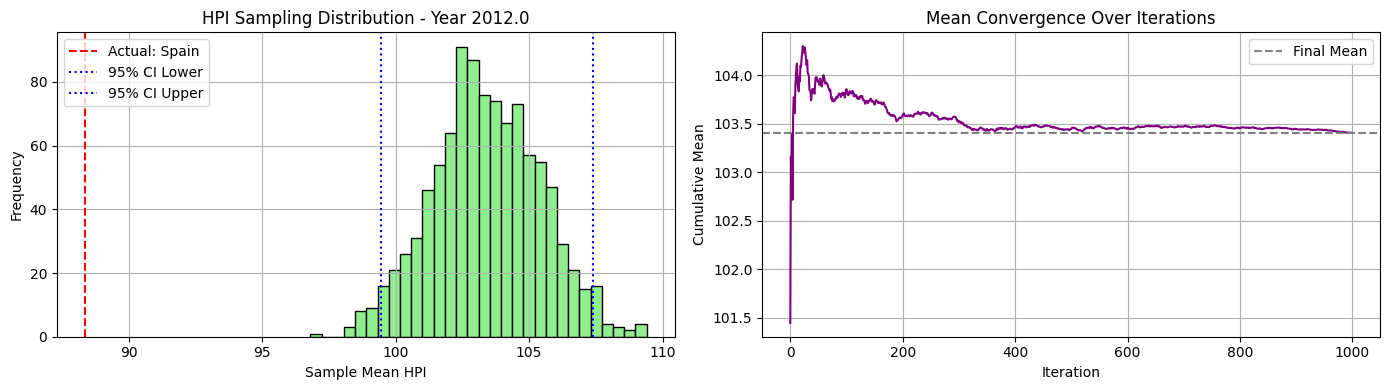


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  90.65  94.7   85.58 128.77 106.87  85.58  85.58 124.45
  92.38 121.5  107.65 113.42 136.52 101.21  85.95 114.59 136.52  86.7
  85.58 115.56  96.53  90.62 118.3 ]


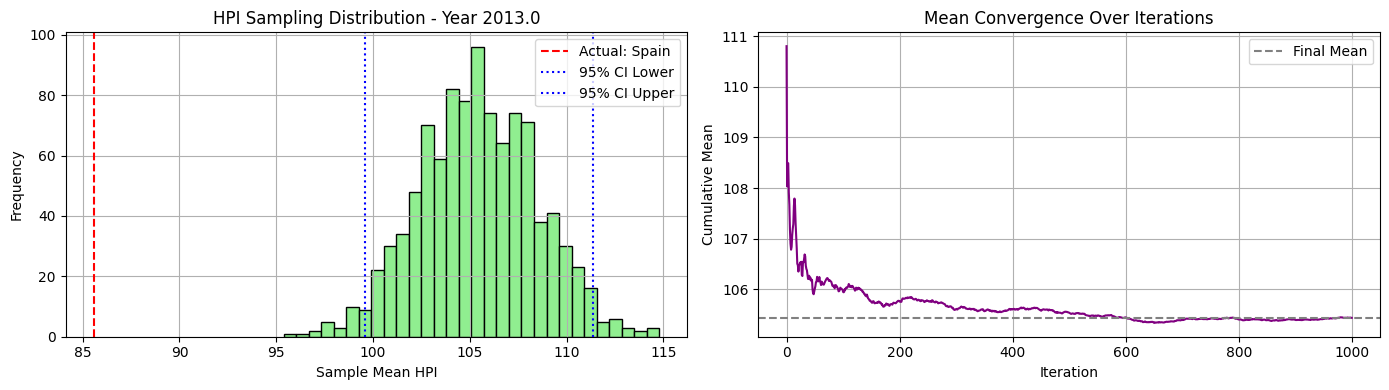


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  91.95  93.19  84.64 146.41 106.5   84.64  84.66 132.36
  88.02 128.78 114.57 118.39 151.67 103.79  86.66 122.03 151.67  90.38
  84.64 112.25  97.8   84.64 121.46]


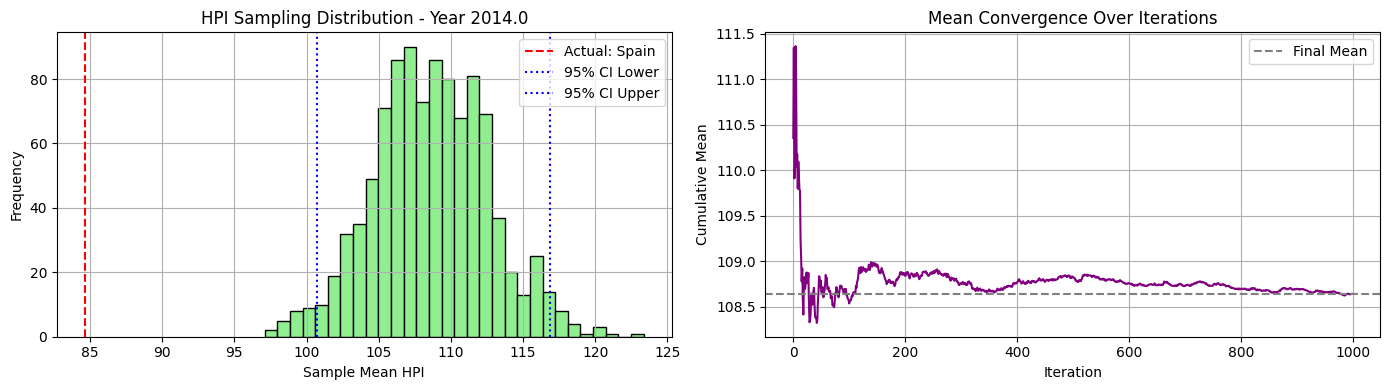


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  94.51  90.54  84.67 156.46 106.5   84.67  94.36 140.12
  84.67 124.46 118.76 124.78 162.89 109.83  89.69 137.18 162.89  93.15
  84.67 107.92 103.    85.32 124.08]


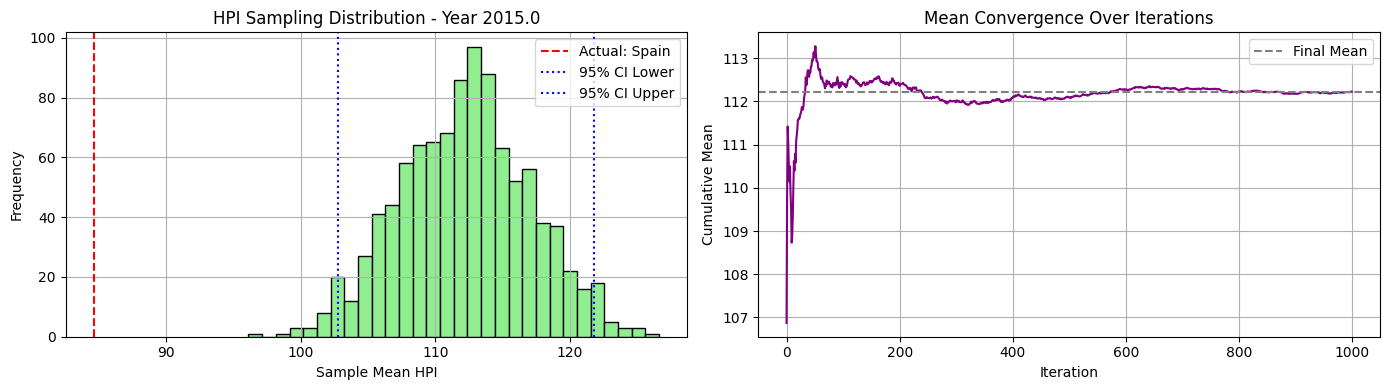


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72 101.15  91.33  88.1  163.86 107.86  88.1  101.42 150.56
  88.1  135.02 125.16 132.28 172.75 115.82  94.43 156.62 164.18  99.78
  88.91 104.55 109.87  88.1  124.32]


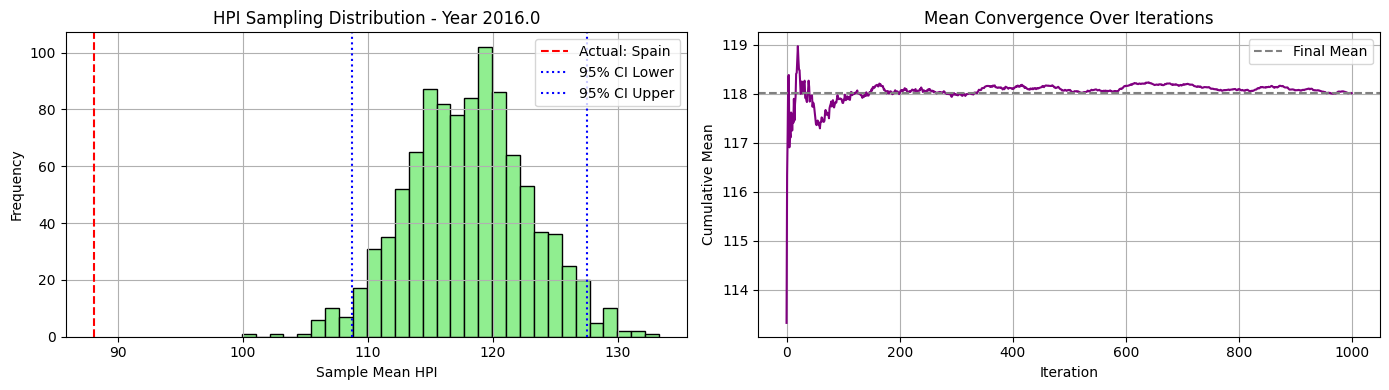


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66 109.91  94.84  88.54 172.91 109.02  88.54 112.44 156.44
  88.54 146.87 136.34 139.69 183.99 121.94 102.06 166.8  168.   108.99
  93.93 103.4  116.3   95.38 125.42]


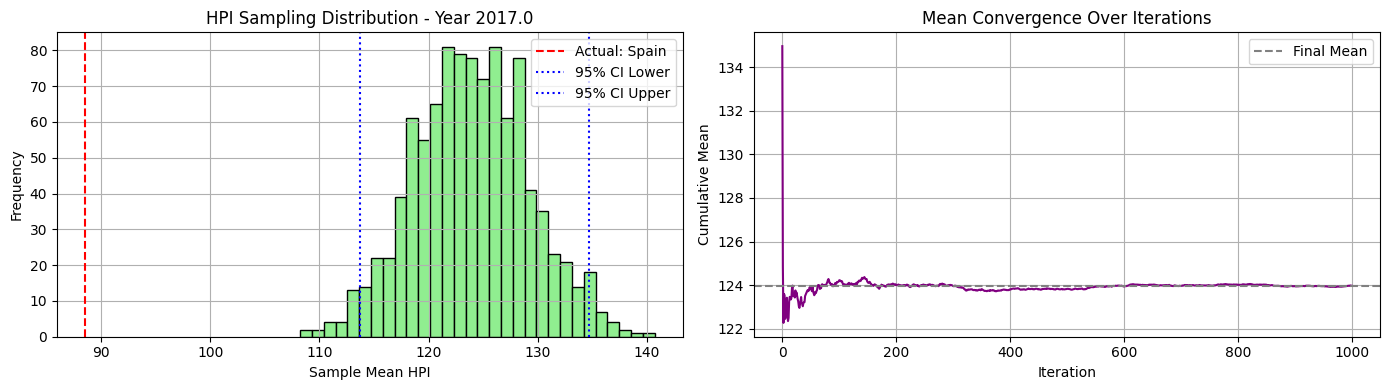


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 117.15 100.59  90.72 183.13 110.06  90.72 123.96 155.14
  90.72 160.92 146.29 149.55 191.85 129.02 111.57 172.8  168.42 120.19
  99.37 111.46 124.97 103.7  129.16]


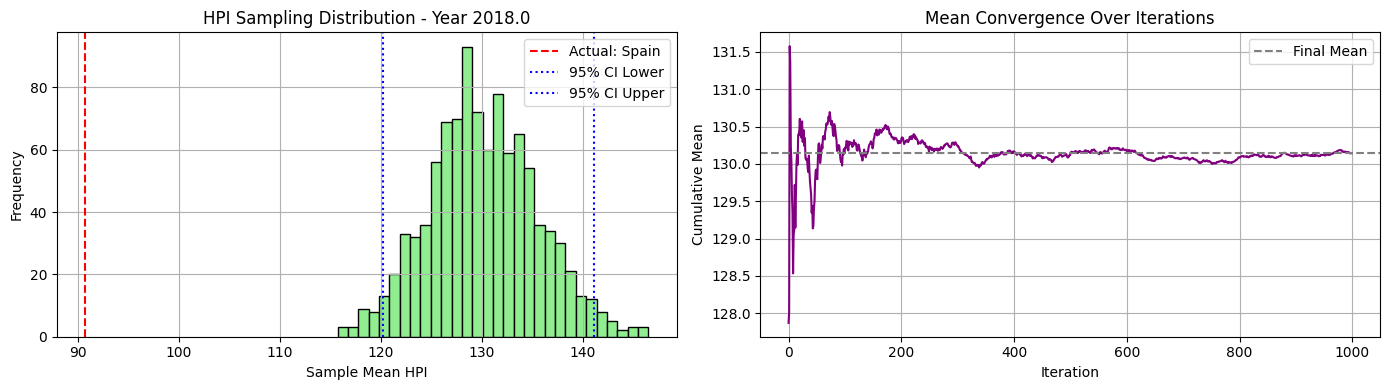


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 124.2  109.64  97.25 195.98 110.52  97.25 126.85 158.06
  97.25 175.33 156.3  164.68 196.06 136.9  119.62 178.19 172.03 132.16
 102.72 113.98 136.39 110.65 133.99]


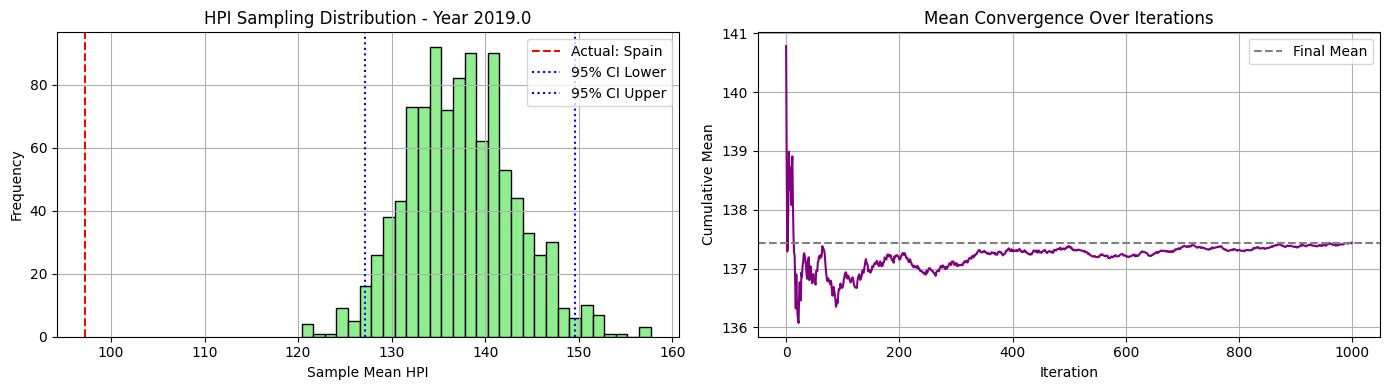


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 129.87 118.06 106.71 207.78 112.49 106.71 127.24 162.9
 106.71 181.42 167.66 188.57 198.37 141.54 129.21 196.31 173.67 143.75
 107.53 115.8  149.36 115.74 137.31]


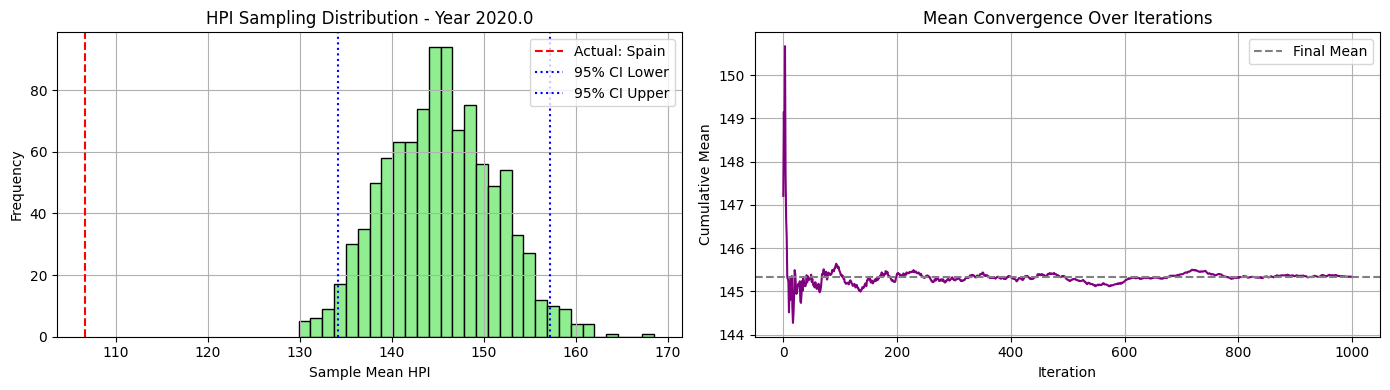


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 141.14 126.64 112.34 239.04 117.62 112.34 137.77 176.65
 112.34 201.18 194.58 214.81 200.69 148.74 147.93 248.26 173.6  157.27
 112.34 125.04 158.94 129.1  145.16]


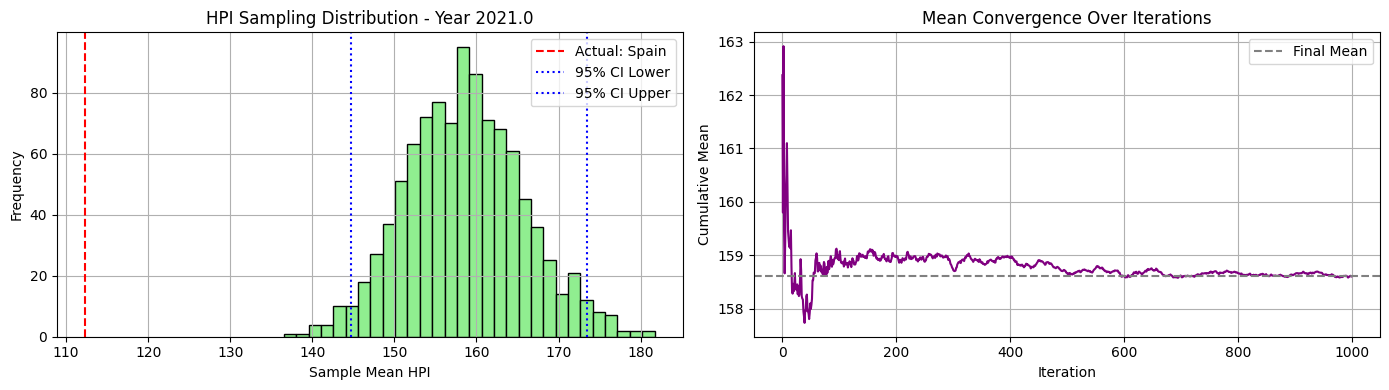


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 160.59 145.44 118.98 292.18 118.98 118.98 154.73 207.16
 118.98 229.01 231.64 235.34 207.75 158.62 167.57 249.69 172.65 177.14
 120.29 137.74 180.7  148.16 154.42]


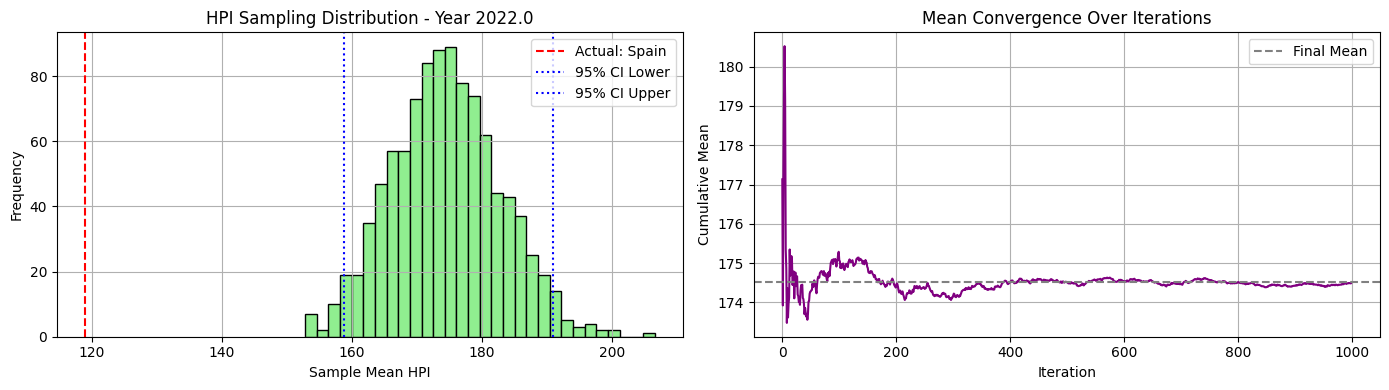


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 176.43 162.82 112.27 309.37 112.27 112.27 159.48 214.23
 112.27 237.56 254.38 214.   216.19 168.5  164.36 233.54 175.16 191.66
 124.06 148.01 180.36 158.88 157.81]


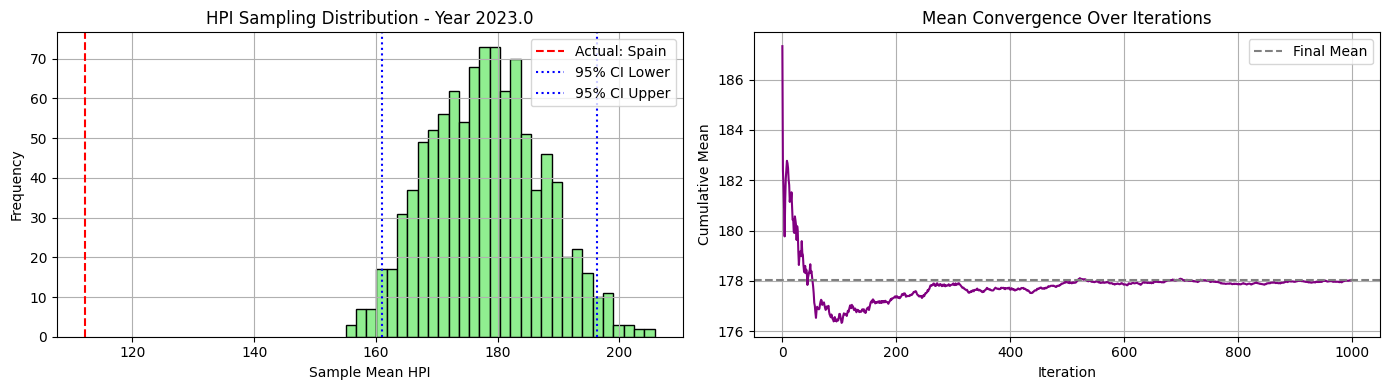


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 205.53 179.7  119.1  328.24 119.1  119.1  173.07 224.54
 119.1  247.54 279.12 202.74 225.06 179.35 177.7  233.68 175.38 209.06
 130.34 155.12 187.15 170.56 160.56]


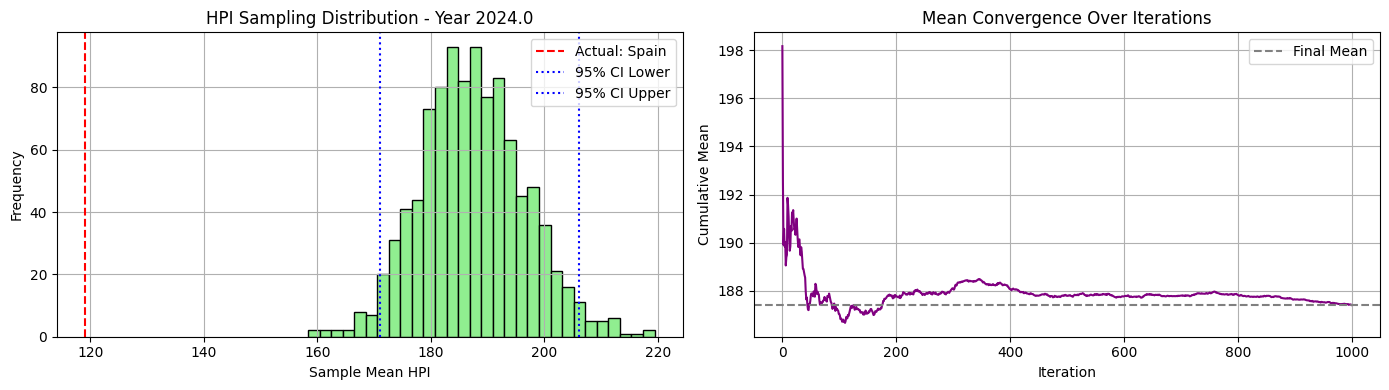

In [10]:
synthetic_c2_ni20_maxi500_h2_23_01, excluded_c2_ni20_maxi500_h2_23_01, actual_c2_ni20_maxi500_h2_23_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=1, seed=23)

### Sampling experiment with seed 32

🔍 Cluster 0 selected. Excluding country: Canada
📊 Sampling from countries: ['Australia', 'Brazil', 'Chile', 'Colombia', 'Czech Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Iceland', 'India', 'Japan', 'Mexico', 'Norway', 'Philippines', 'Poland', 'Russia', 'Serbia', 'South Africa', 'South Korea', 'Sweden', 'Thailand', 'Turkey', 'United Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


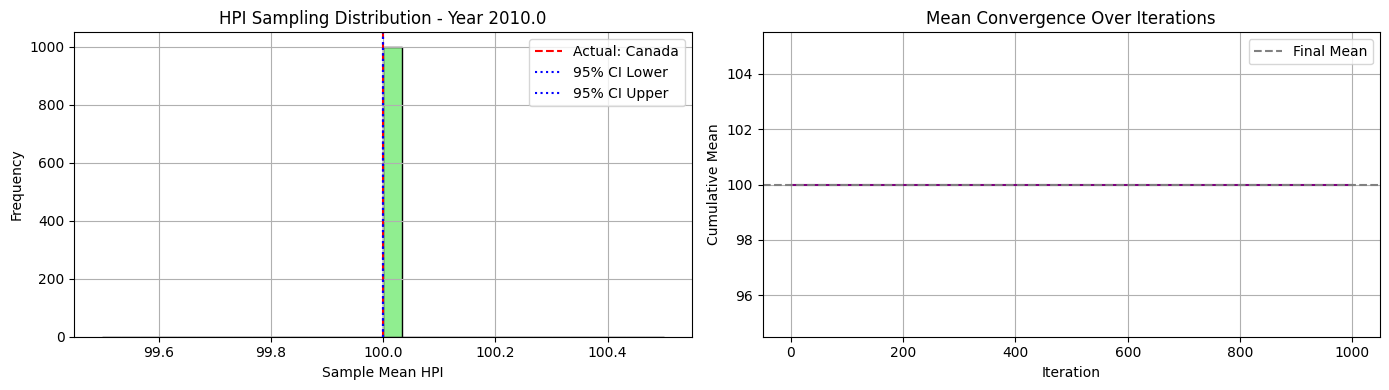


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 110.52 107.89 100.02  98.29 105.69 102.42  96.56 105.5
 110.52 100.07 105.8  108.01 105.57 100.08  94.49  97.62 103.59 105.23
 102.58 104.26 108.8   98.54  97.24]


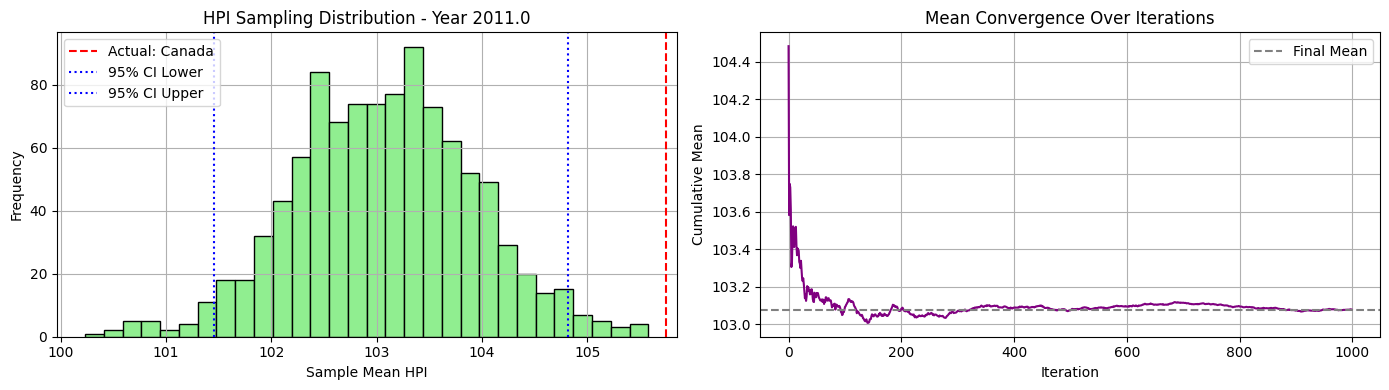


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 124.02 118.79  98.56  95.67 105.11 105.48  92.98 112.38
 124.02  99.19 109.17 115.34 114.94  96.58  91.1   95.68 108.41 108.25
 103.86 107.63 120.68  98.92 101.82]


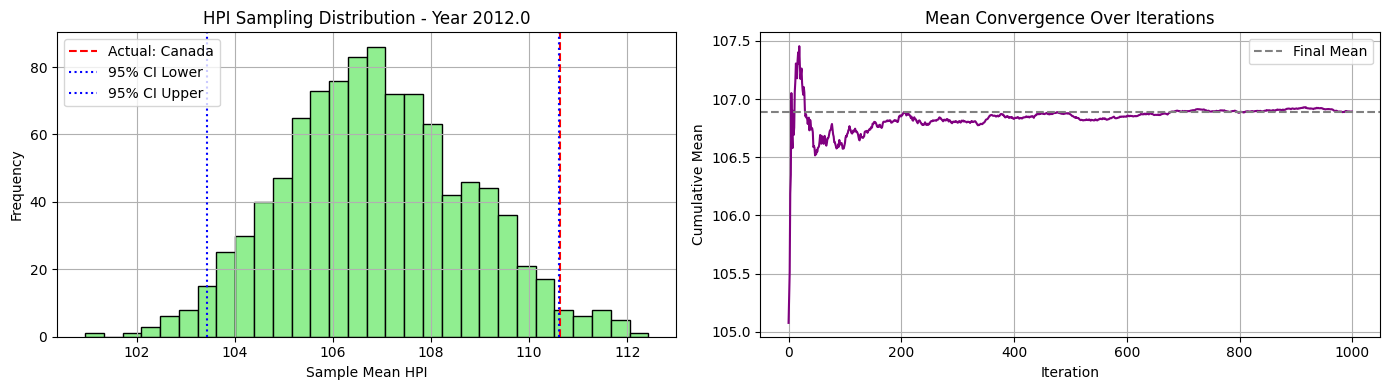


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 136.52 130.06  98.58  99.37 103.13 108.68  90.58 119.18
 136.52 100.81 114.75 119.98 127.86  92.35  94.32  90.62 115.41 107.8
 109.22 115.99 134.46 101.46 111.83]


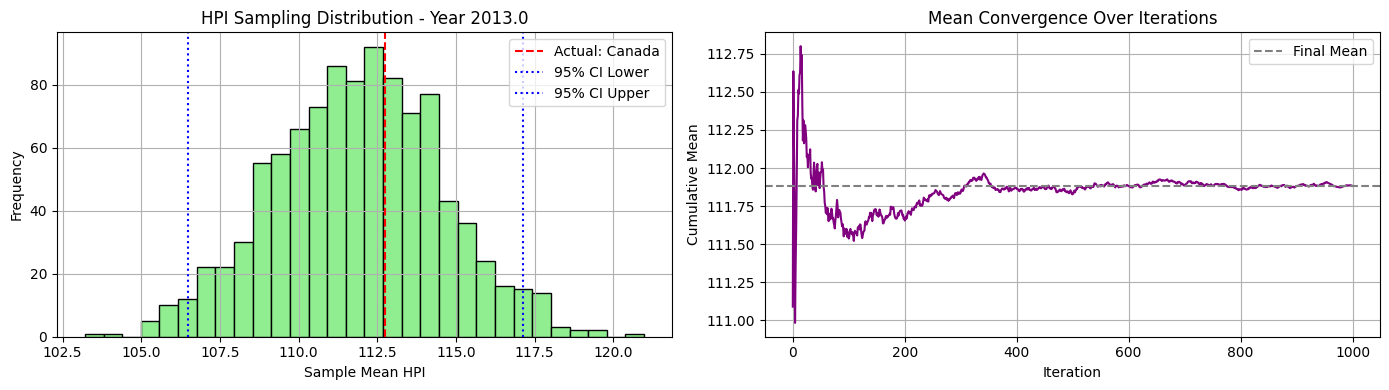


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 151.67 140.75 101.   103.12 101.58 111.85  94.37 128.94
 151.67 102.38 119.64 123.24 142.76  93.27  95.84  95.77 123.99 109.43
 119.52 127.07 151.25 109.6  118.88]


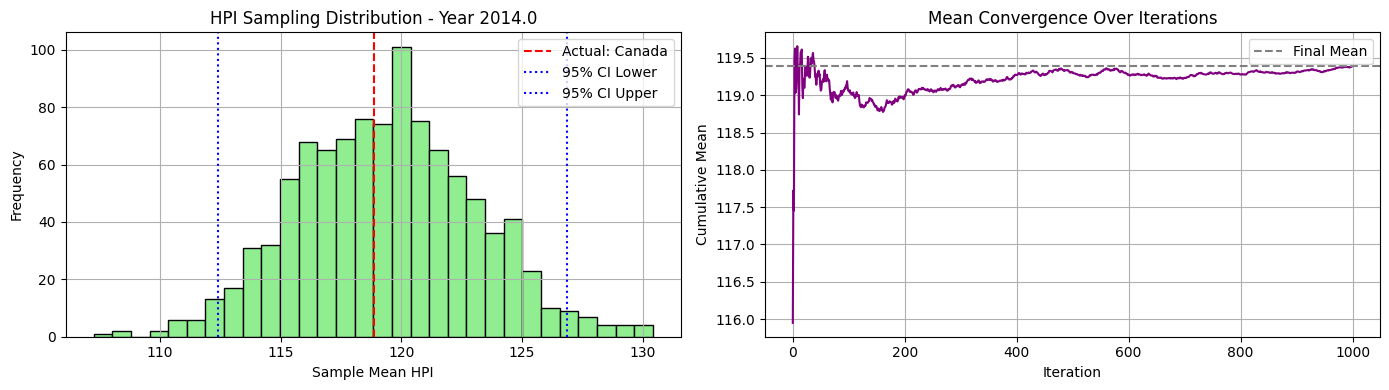


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 162.89 152.93 105.01 110.29 100.22 117.12 106.75 139.74
 162.89 104.86 129.39 130.76 157.04  94.69  97.    99.5  131.8  113.08
 135.2  136.   162.89 116.12 125.18]


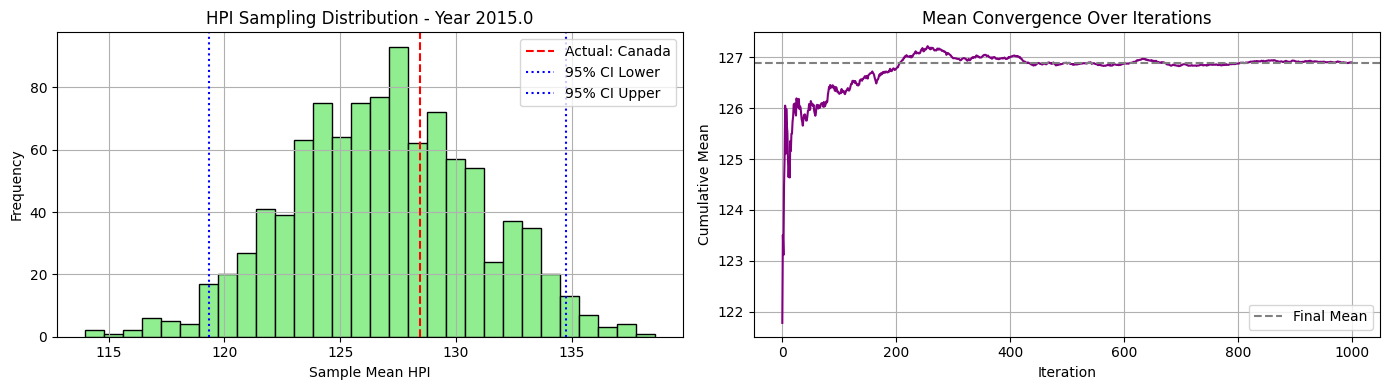


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 172.75 167.48 112.52 115.5  101.25 125.93 121.03 154.59
 172.75 107.18 138.82 139.95 172.75  96.44  91.86 110.62 138.22 116.09
 146.34 142.4  172.75 124.27 131.88]


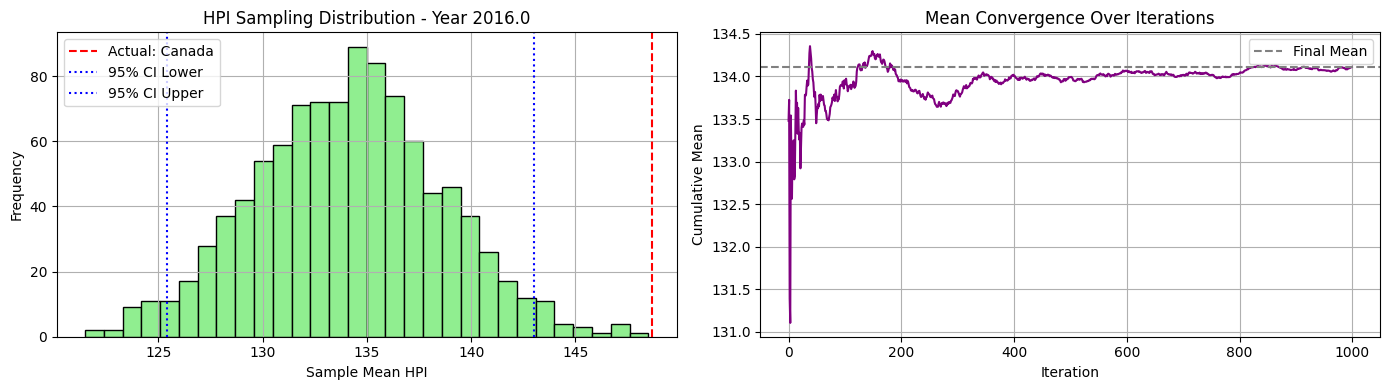


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 183.99 178.56 125.7  120.63 104.46 133.62 135.84 183.99
 183.99 109.91 149.69 146.91 178.82 100.16  88.54 115.3  143.94 117.6
 156.06 146.48 183.99 129.93 139.61]


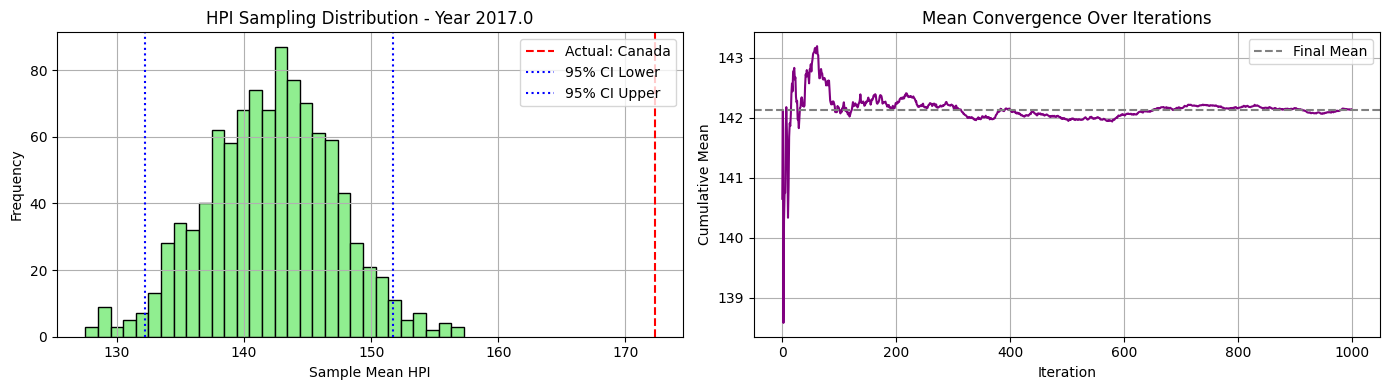


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 191.85 188.24 136.52 126.31 107.52 142.52 155.3  191.85
 191.85 112.04 162.97 149.04 183.82 106.75  90.72 123.06 148.96 120.22
 154.6  153.9  191.85 134.04 147.35]


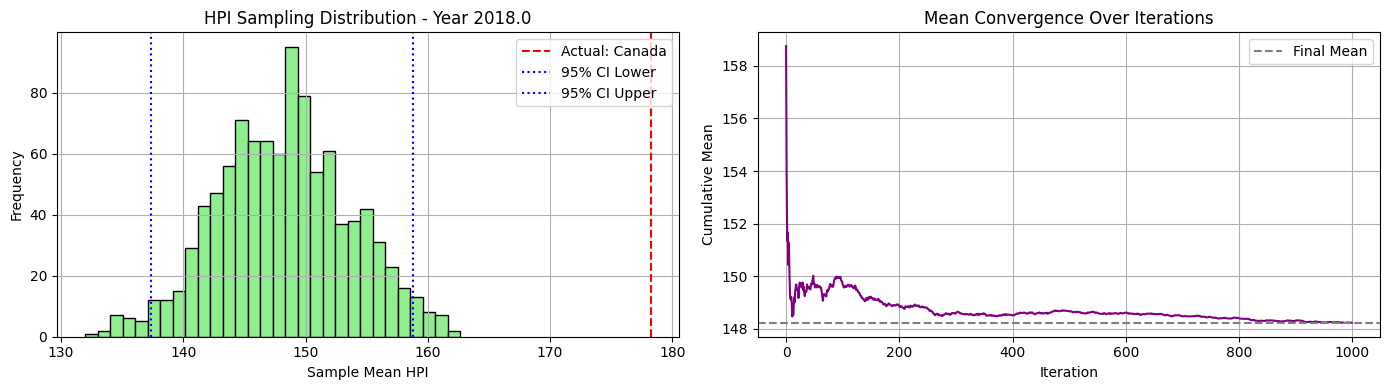


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 198.37 198.37 149.02 129.62 111.1  150.75 181.64 198.37
 198.37 113.84 176.92 152.73 195.26 116.01  97.25 135.77 152.69 121.93
 158.44 155.1  198.37 135.37 153.14]


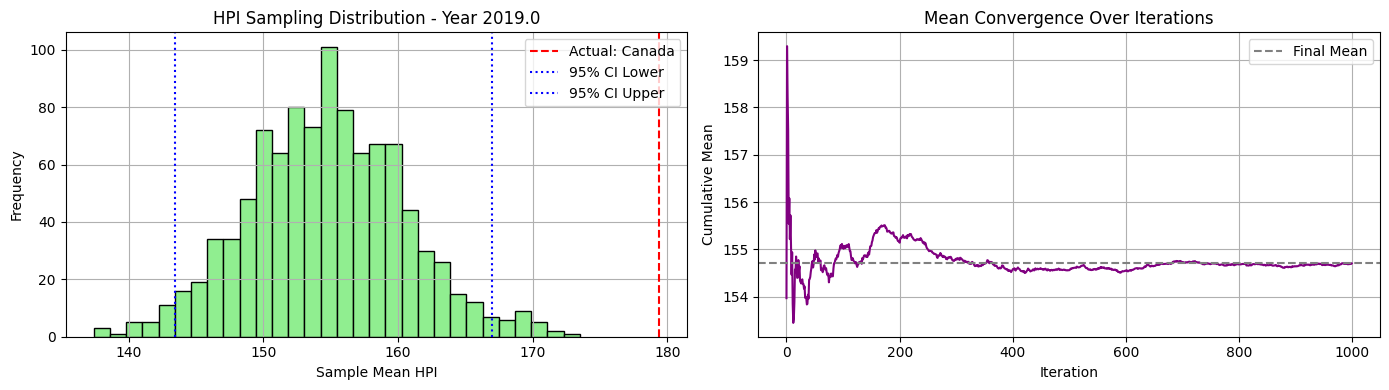


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 213.74 203.12 161.56 136.24 116.89 162.48 190.63 213.74
 213.74 113.93 187.18 159.24 213.74 128.18 106.71 149.28 156.31 126.56
 165.09 160.6  213.74 139.24 163.52]


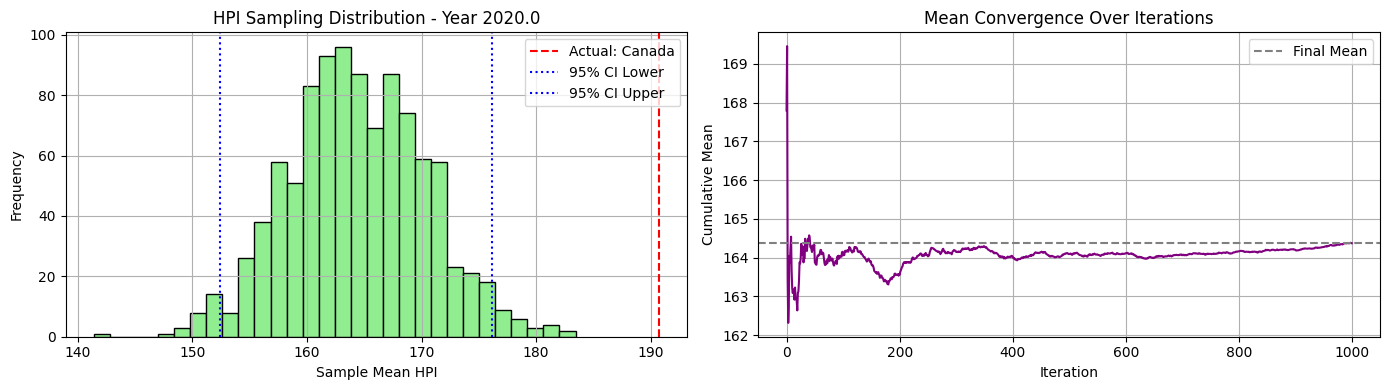


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 248.26 214.9  193.46 152.2  124.38 181.28 222.1  248.26
 248.26 120.7  201.94 175.91 211.74 139.92 121.41 166.04 166.82 143.73
 181.79 164.23 248.26 150.58 188.56]


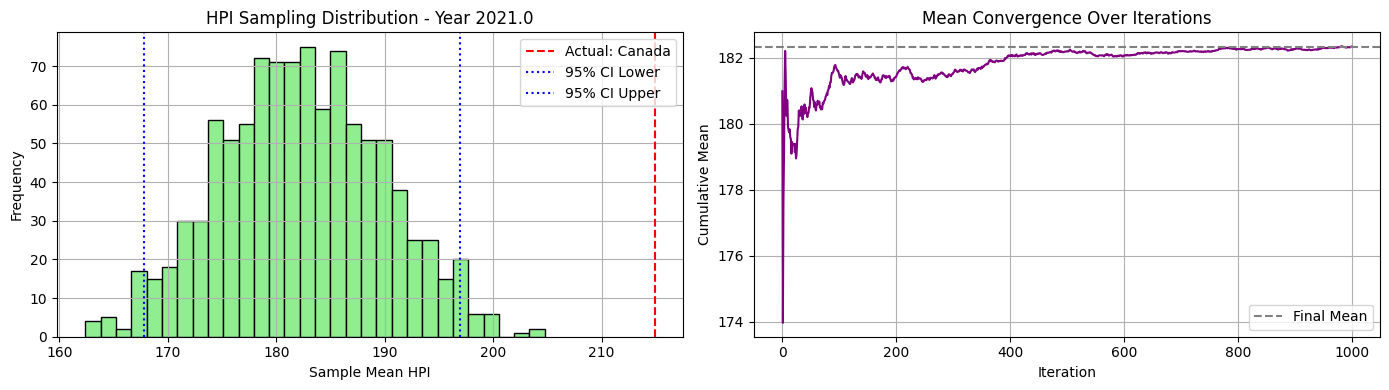


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 292.18 230.   226.15 151.49 132.1  190.42 271.5  292.18
 292.18 130.84 219.93 185.13 223.73 156.43 155.16 191.49 174.03 153.22
 188.27 169.16 292.18 164.55 213.  ]


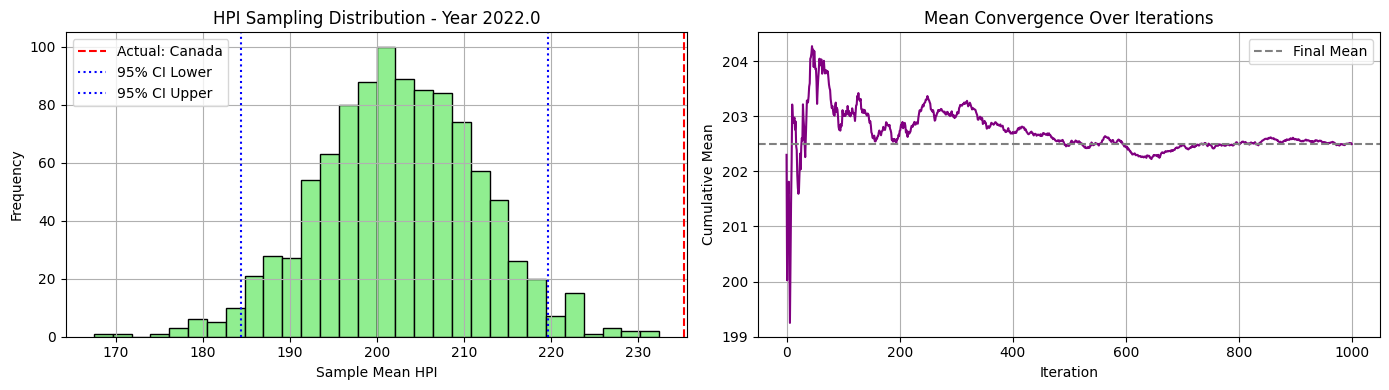


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 309.37 245.75 222.4  151.24 131.52 174.25 290.98 309.37
 309.37 134.8  243.89 184.12 248.04 170.23 157.88 209.99 176.62 143.99
 178.36 174.79 309.37 165.   221.72]


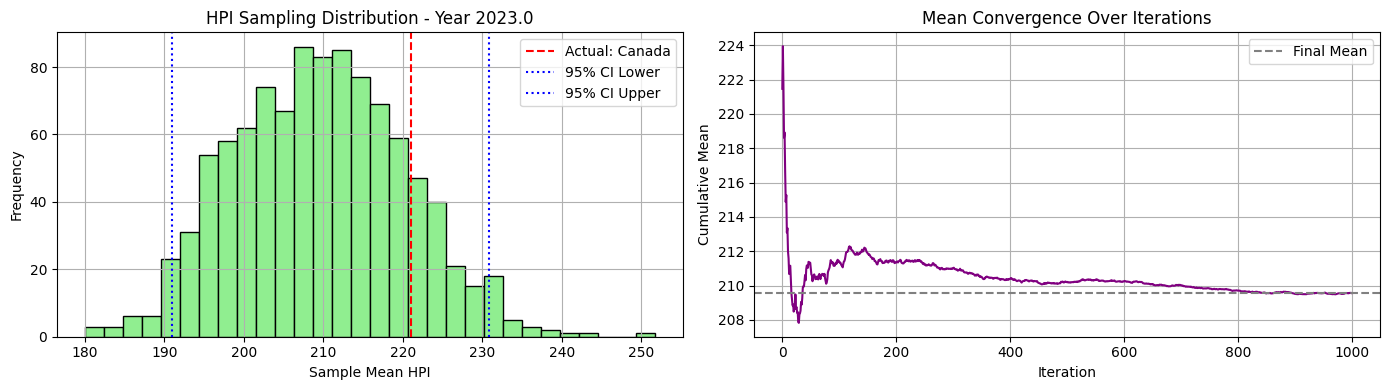


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 328.24 269.02 233.42 156.73 126.68 171.5  328.1  328.24
 328.24 138.61 266.38 189.05 256.03 195.72 186.66 220.7  178.1  142.46
 178.49 178.06 328.24 166.38 231.23]


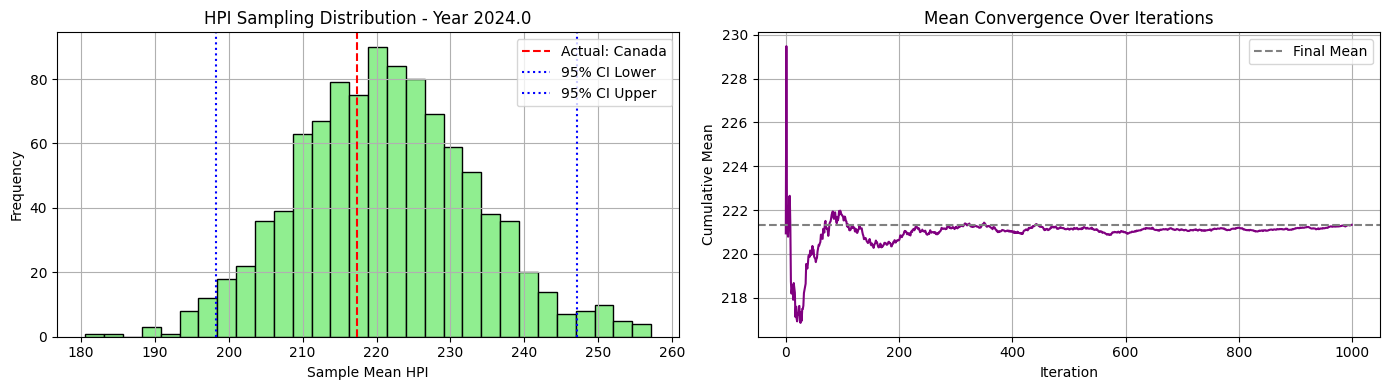

In [11]:
synthetic_c2_ni20_maxi500_h2_32_00, excluded_c2_ni20_maxi500_h2_32_00, actual_c2_ni20_maxi500_h2_32_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=0, seed=32)

🔍 Cluster 1 selected. Excluding country: Bulgaria
📊 Sampling from countries: ['Austria', 'Belgium', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Israel', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New Zealand', 'Peru', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'Spain', 'Switzerland']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


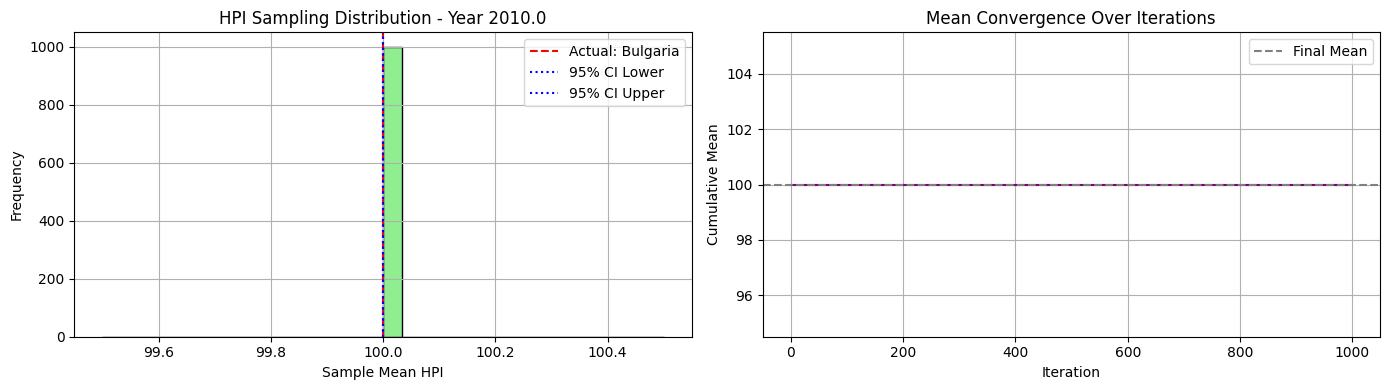


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58 100.16  96.68 108.47 103.17  94.53  94.49 110.52 101.36
 110.42 106.6  103.68 109.83  98.63  98.02 100.75 110.52  95.1   94.49
 109.46  98.46 102.72  94.49 107.51]


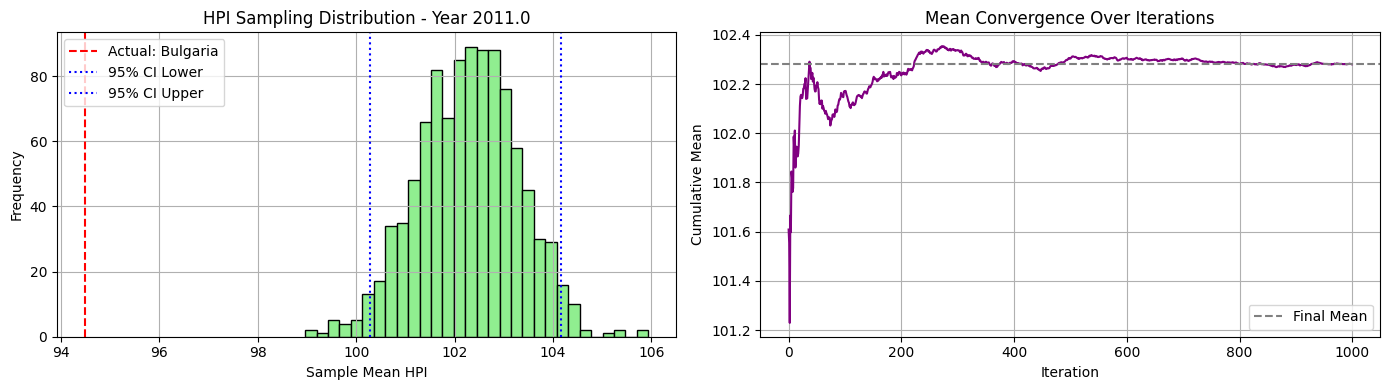


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  98.62  91.54 116.34 105.64  88.37  88.37 114.1   98.77
 113.71 106.36 108.03 124.02 101.62  91.44 105.25 124.02  88.37  88.37
 112.02  95.73  95.63  88.37 113.72]


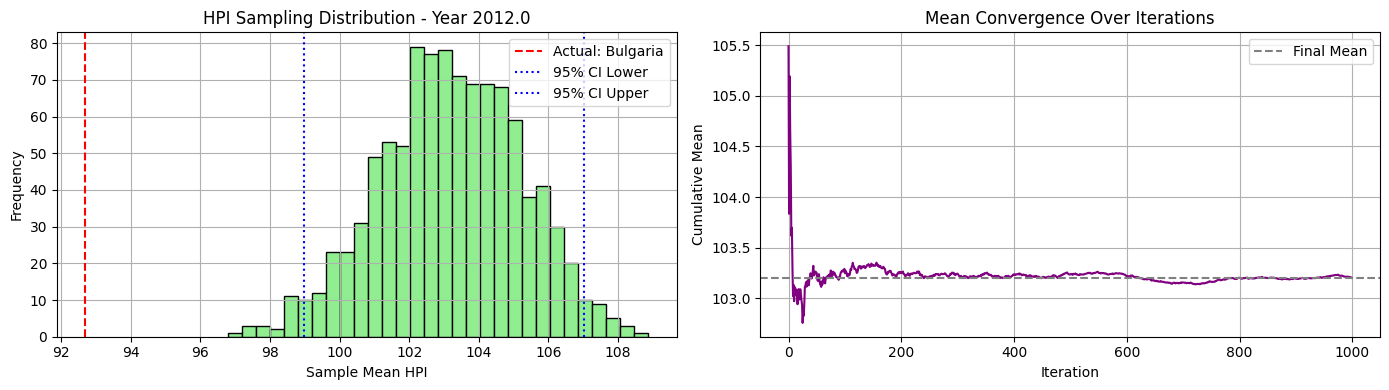


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  94.7   85.58 128.77 106.87  85.58  85.58 124.45  92.38
 121.5  107.65 113.42 136.52 101.21  85.95 114.59 136.52  86.7   85.58
 115.56  96.53  90.62  85.58 118.3 ]


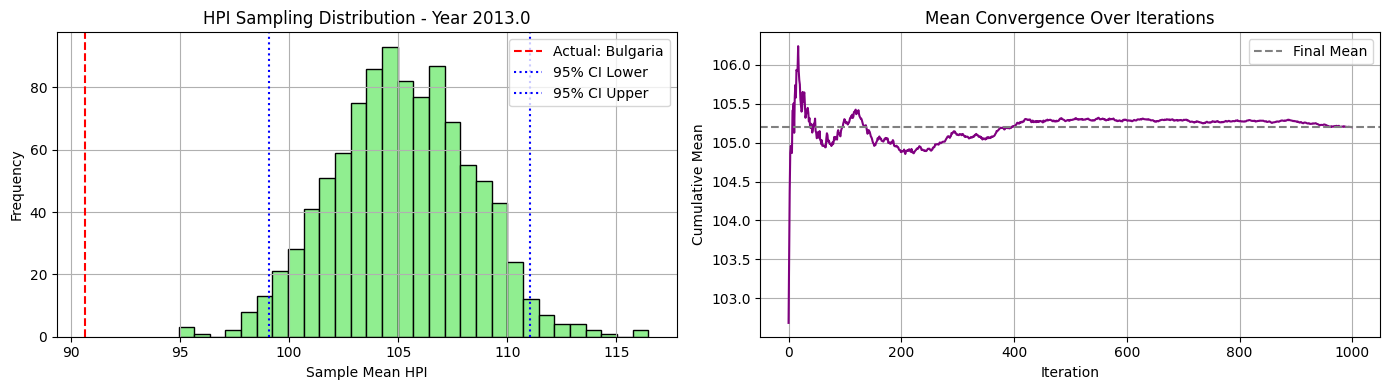


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  93.19  84.64 146.41 106.5   84.64  84.66 132.36  88.02
 128.78 114.57 118.39 151.67 103.79  86.66 122.03 151.67  90.38  84.64
 112.25  97.8   84.64  84.64 121.46]


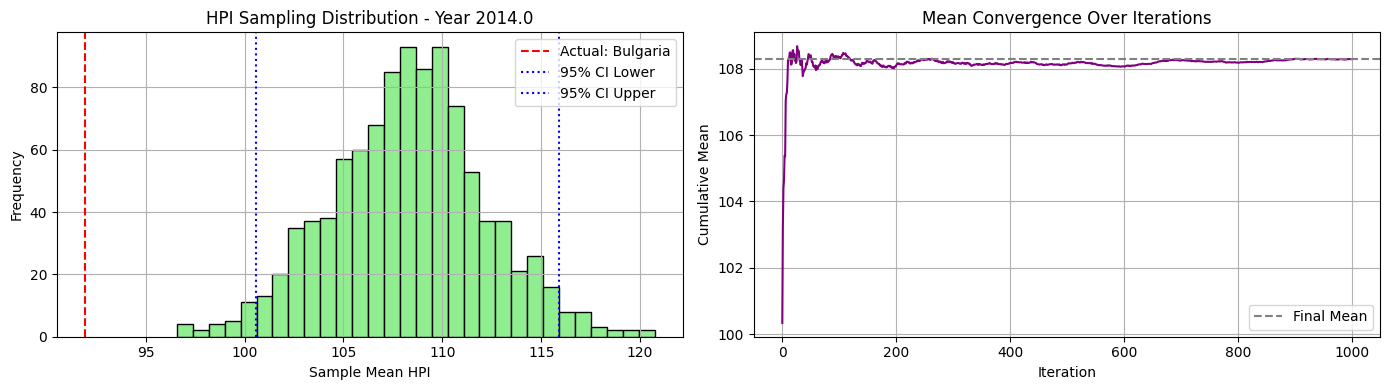


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  90.54  84.67 156.46 106.5   84.67  94.36 140.12  84.67
 124.46 118.76 124.78 162.89 109.83  89.69 137.18 162.89  93.15  84.67
 107.92 103.    85.32  84.67 124.08]


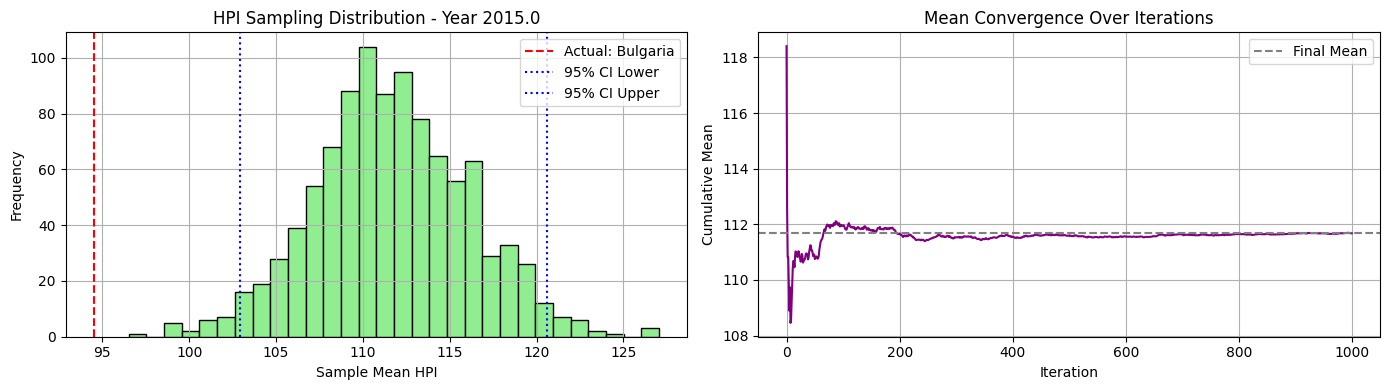


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72  91.33  88.1  163.86 107.86  88.1  101.42 150.56  88.1
 135.02 125.16 132.28 172.75 115.82  94.43 156.62 164.18  99.78  88.91
 104.55 109.87  88.1   88.1  124.32]


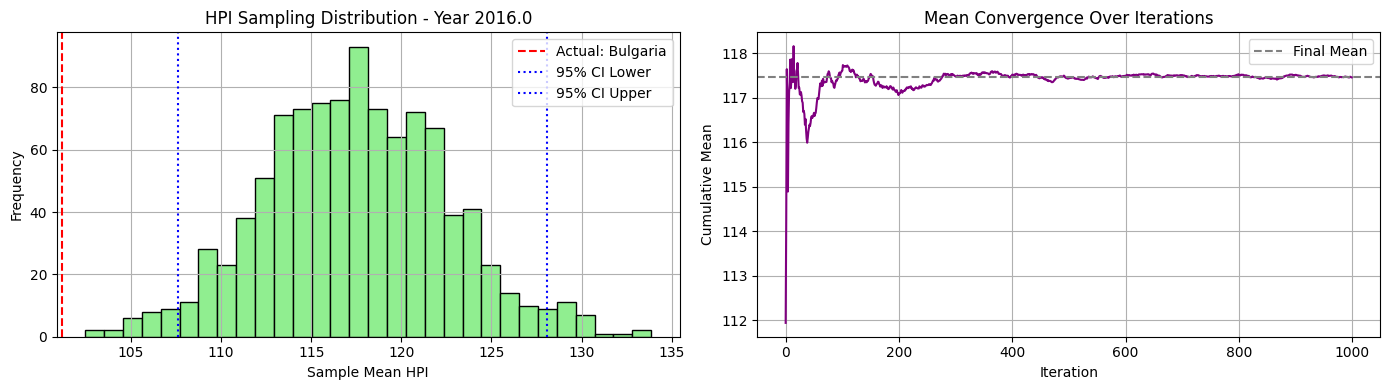


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66  94.84  88.54 172.91 109.02  88.54 112.44 156.44  88.54
 146.87 136.34 139.69 183.99 121.94 102.06 166.8  168.   108.99  93.93
 103.4  116.3   95.38  88.54 125.42]


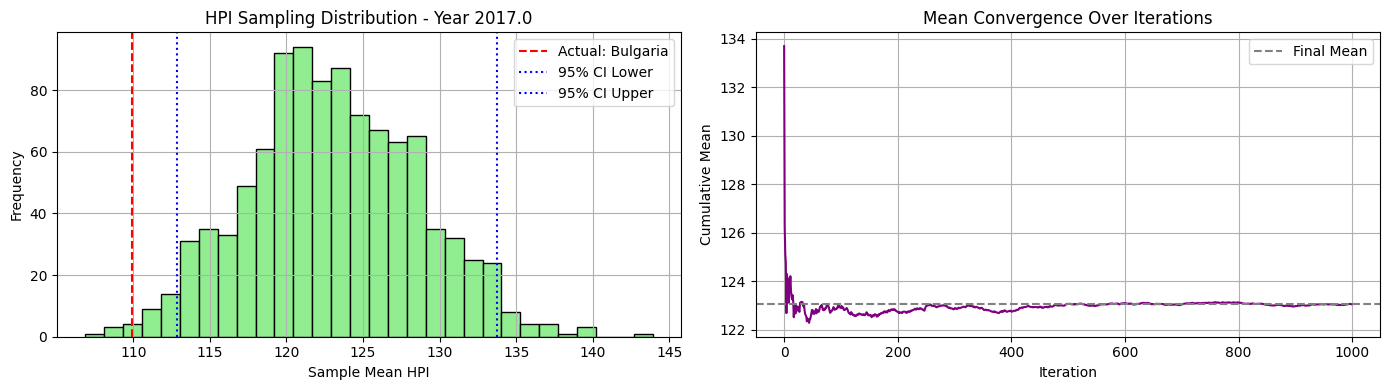


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 100.59  90.72 183.13 110.06  90.72 123.96 155.14  90.72
 160.92 146.29 149.55 191.85 129.02 111.57 172.8  168.42 120.19  99.37
 111.46 124.97 103.7   90.72 129.16]


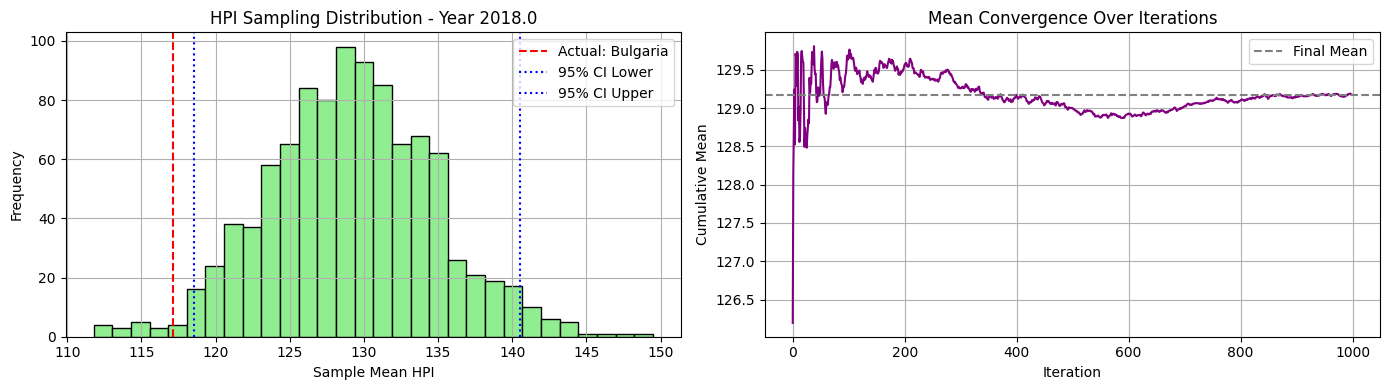


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 109.64  97.25 195.98 110.52  97.25 126.85 158.06  97.25
 175.33 156.3  164.68 196.06 136.9  119.62 178.19 172.03 132.16 102.72
 113.98 136.39 110.65  97.25 133.99]


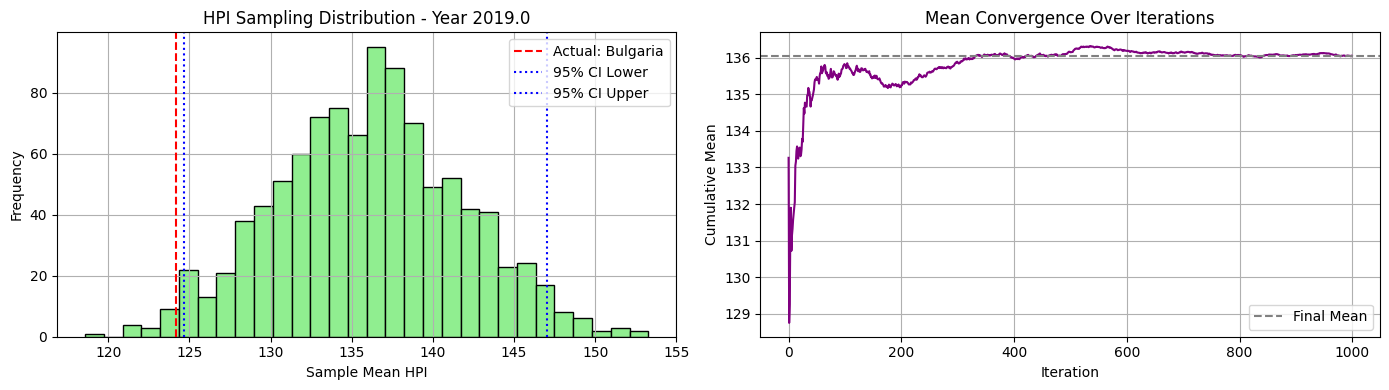


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 118.06 106.71 207.78 112.49 106.71 127.24 162.9  106.71
 181.42 167.66 188.57 198.37 141.54 129.21 196.31 173.67 143.75 107.53
 115.8  149.36 115.74 106.71 137.31]


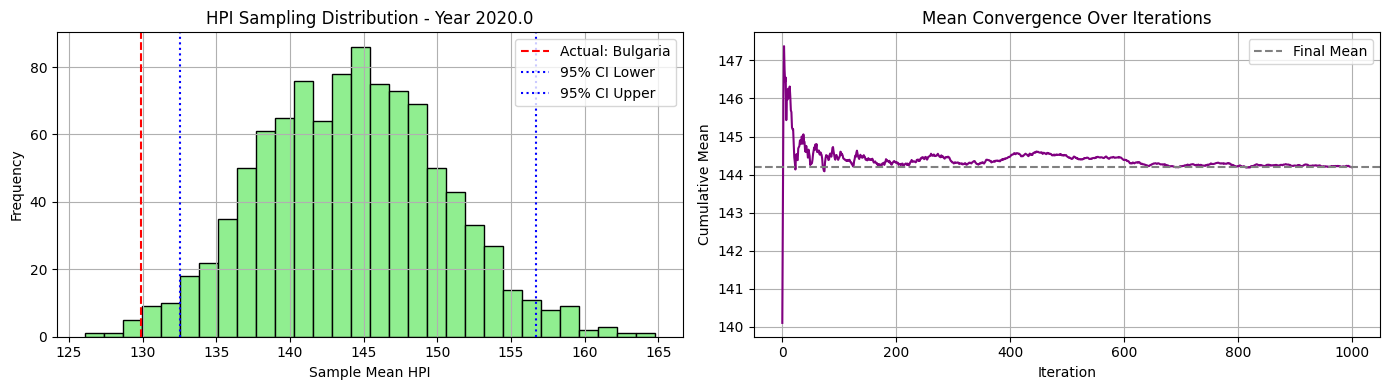


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 126.64 112.34 239.04 117.62 112.34 137.77 176.65 112.34
 201.18 194.58 214.81 200.69 148.74 147.93 248.26 173.6  157.27 112.34
 125.04 158.94 129.1  112.34 145.16]


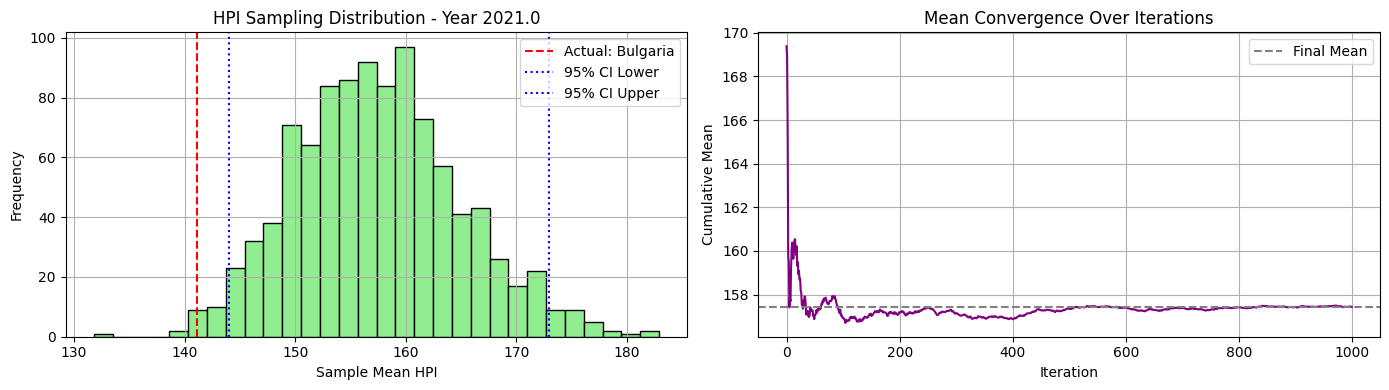


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 145.44 118.98 292.18 118.98 118.98 154.73 207.16 118.98
 229.01 231.64 235.34 207.75 158.62 167.57 249.69 172.65 177.14 120.29
 137.74 180.7  148.16 118.98 154.42]


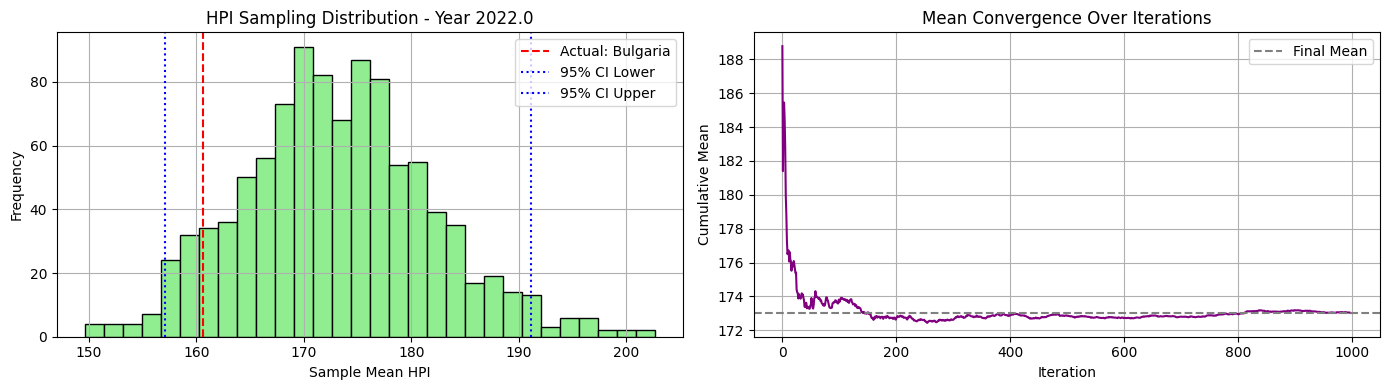


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 162.82 112.27 309.37 112.27 112.27 159.48 214.23 112.27
 237.56 254.38 214.   216.19 168.5  164.36 233.54 175.16 191.66 124.06
 148.01 180.36 158.88 112.27 157.81]


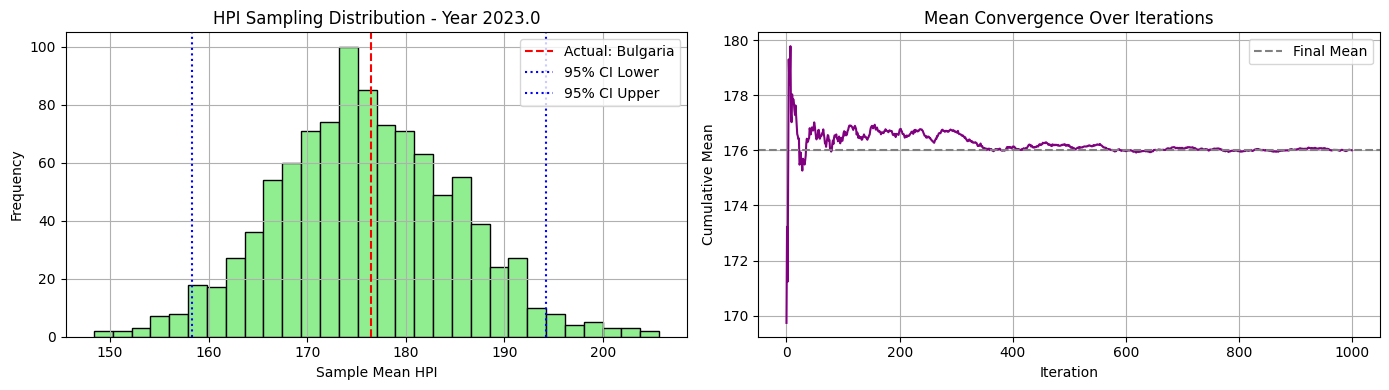


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 179.7  119.1  328.24 119.1  119.1  173.07 224.54 119.1
 247.54 279.12 202.74 225.06 179.35 177.7  233.68 175.38 209.06 130.34
 155.12 187.15 170.56 119.1  160.56]


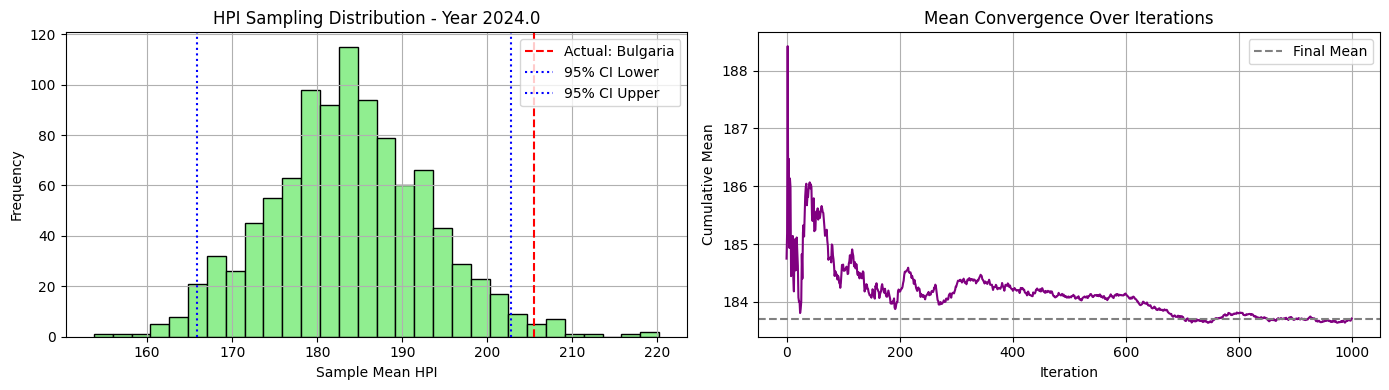

In [12]:
synthetic_c2_ni20_maxi500_h2_32_01, excluded_c2_ni20_maxi500_h2_32_01, actual_c2_ni20_maxi500_h2_32_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=1, seed=32)

### Sampling experiment with seed 46

🔍 Cluster 0 selected. Excluding country: Canada
📊 Sampling from countries: ['Australia', 'Brazil', 'Chile', 'Colombia', 'Czech Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Iceland', 'India', 'Japan', 'Mexico', 'Norway', 'Philippines', 'Poland', 'Russia', 'Serbia', 'South Africa', 'South Korea', 'Sweden', 'Thailand', 'Turkey', 'United Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


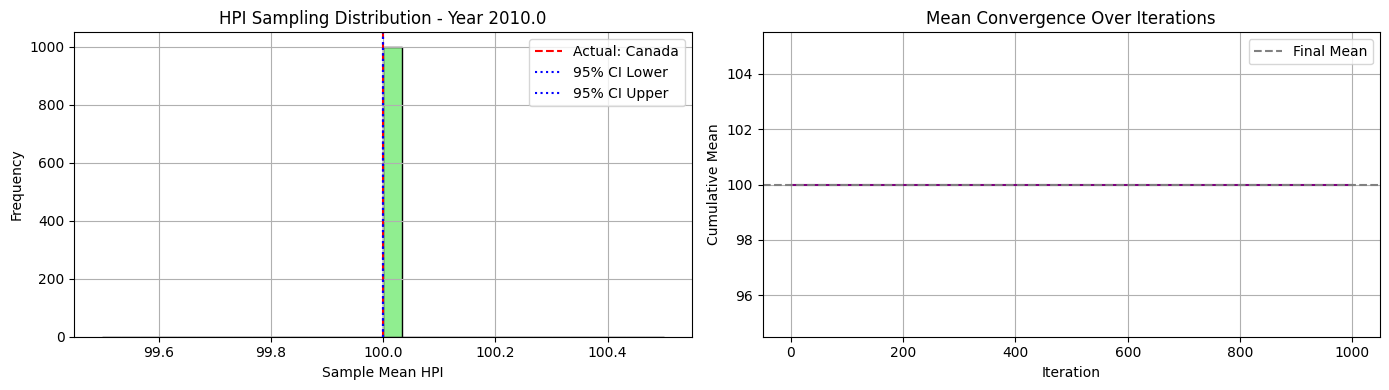


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 110.52 107.89 100.02  98.29 105.69 102.42  96.56 105.5
 110.52 100.07 105.8  108.01 105.57 100.08  94.49  97.62 103.59 105.23
 102.58 104.26 108.8   98.54  97.24]


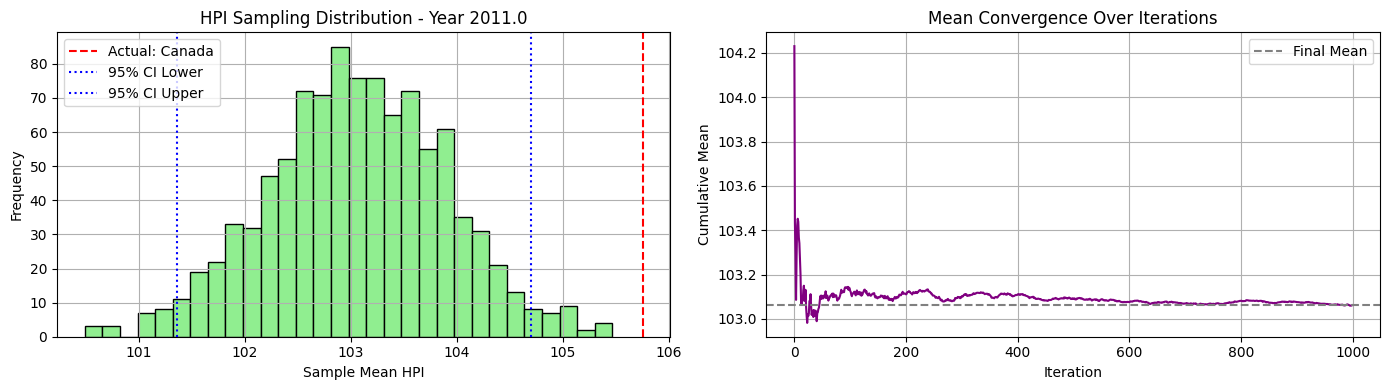


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 124.02 118.79  98.56  95.67 105.11 105.48  92.98 112.38
 124.02  99.19 109.17 115.34 114.94  96.58  91.1   95.68 108.41 108.25
 103.86 107.63 120.68  98.92 101.82]


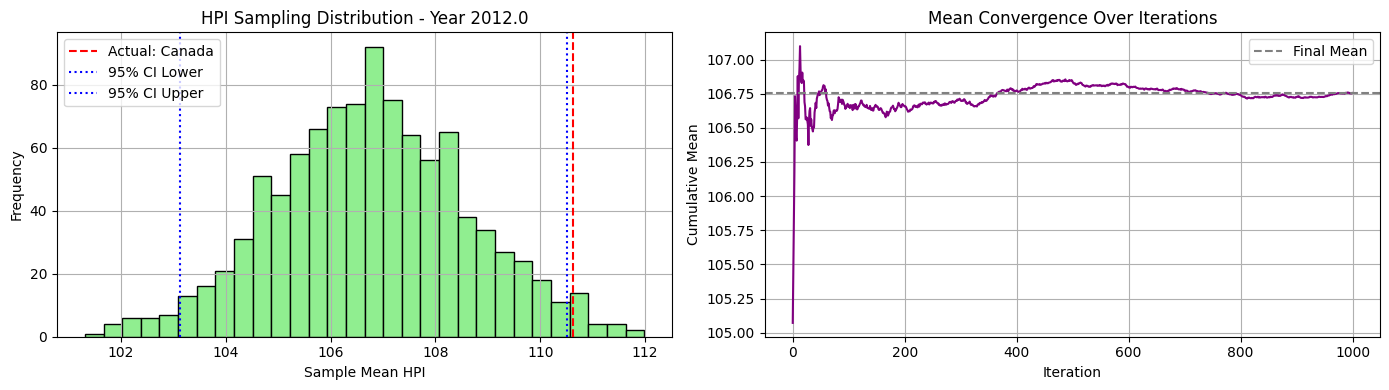


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 136.52 130.06  98.58  99.37 103.13 108.68  90.58 119.18
 136.52 100.81 114.75 119.98 127.86  92.35  94.32  90.62 115.41 107.8
 109.22 115.99 134.46 101.46 111.83]


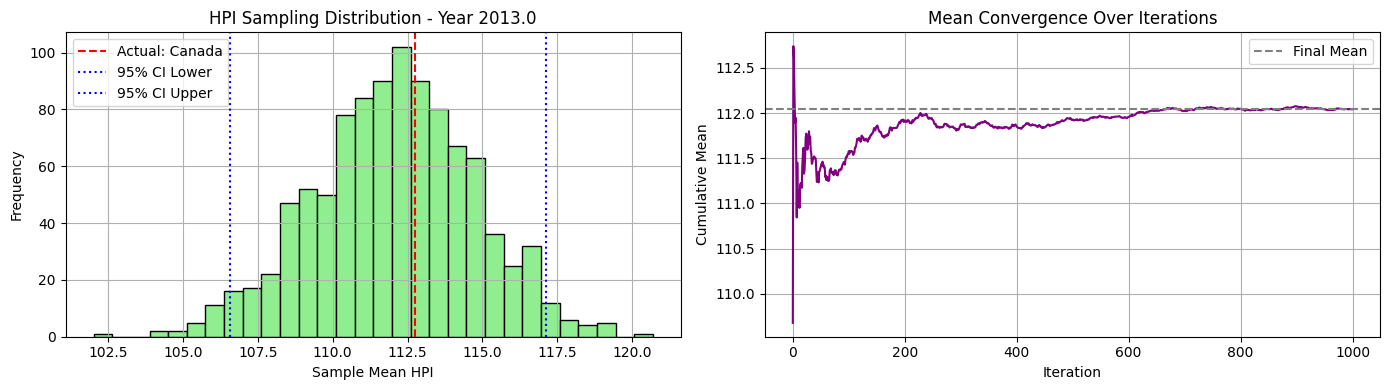


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 151.67 140.75 101.   103.12 101.58 111.85  94.37 128.94
 151.67 102.38 119.64 123.24 142.76  93.27  95.84  95.77 123.99 109.43
 119.52 127.07 151.25 109.6  118.88]


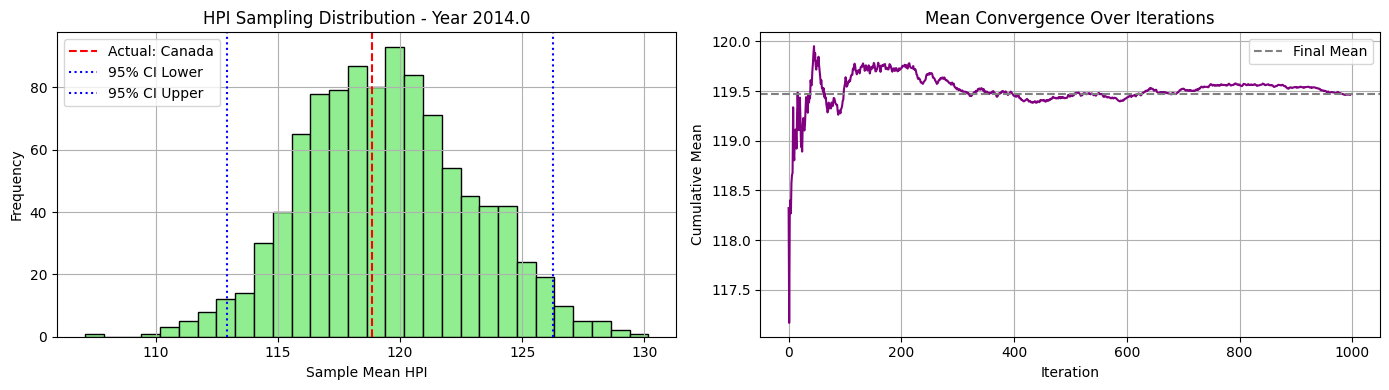


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 162.89 152.93 105.01 110.29 100.22 117.12 106.75 139.74
 162.89 104.86 129.39 130.76 157.04  94.69  97.    99.5  131.8  113.08
 135.2  136.   162.89 116.12 125.18]


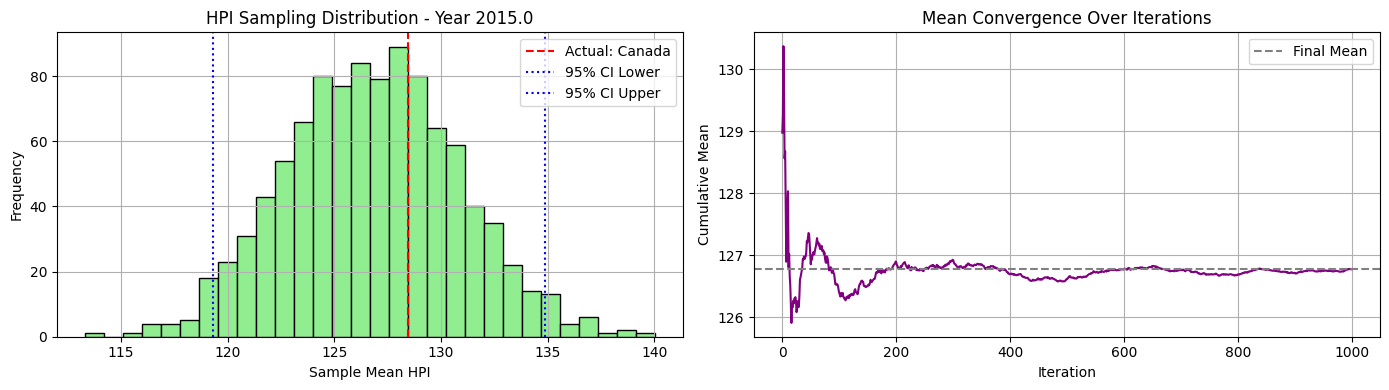


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 172.75 167.48 112.52 115.5  101.25 125.93 121.03 154.59
 172.75 107.18 138.82 139.95 172.75  96.44  91.86 110.62 138.22 116.09
 146.34 142.4  172.75 124.27 131.88]


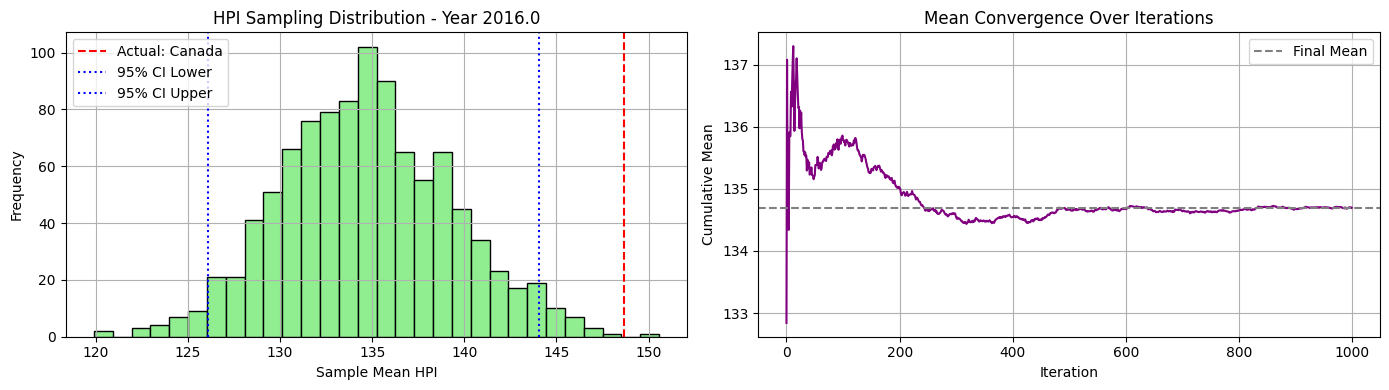


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 183.99 178.56 125.7  120.63 104.46 133.62 135.84 183.99
 183.99 109.91 149.69 146.91 178.82 100.16  88.54 115.3  143.94 117.6
 156.06 146.48 183.99 129.93 139.61]


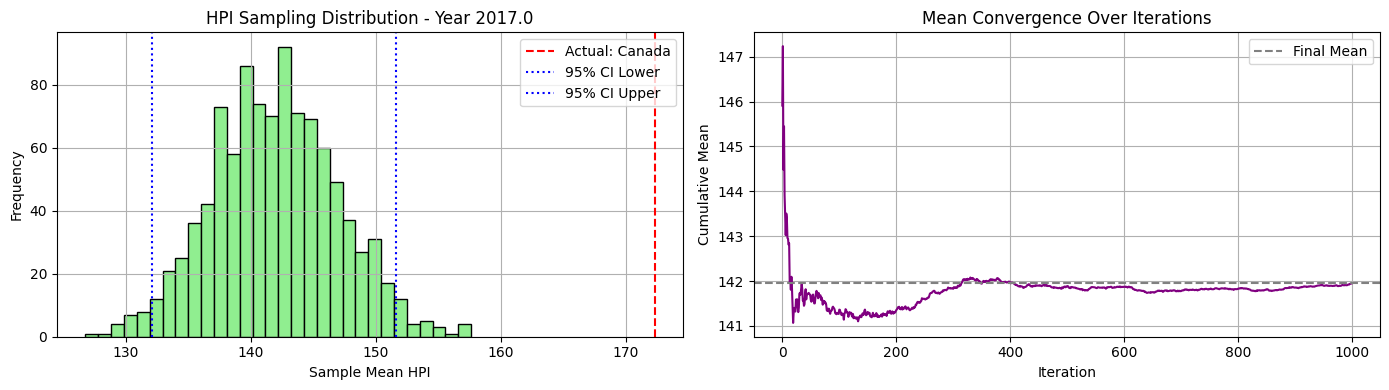


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 191.85 188.24 136.52 126.31 107.52 142.52 155.3  191.85
 191.85 112.04 162.97 149.04 183.82 106.75  90.72 123.06 148.96 120.22
 154.6  153.9  191.85 134.04 147.35]


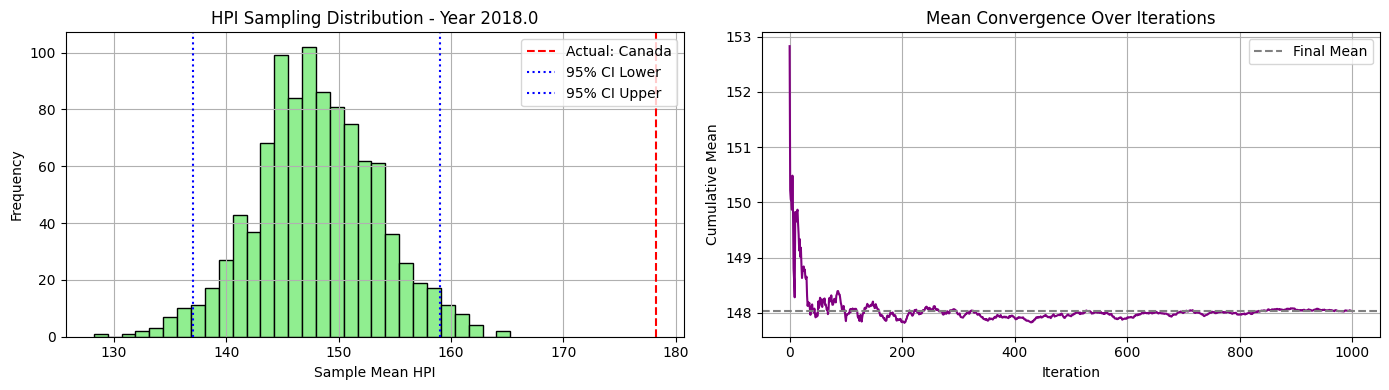


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 198.37 198.37 149.02 129.62 111.1  150.75 181.64 198.37
 198.37 113.84 176.92 152.73 195.26 116.01  97.25 135.77 152.69 121.93
 158.44 155.1  198.37 135.37 153.14]


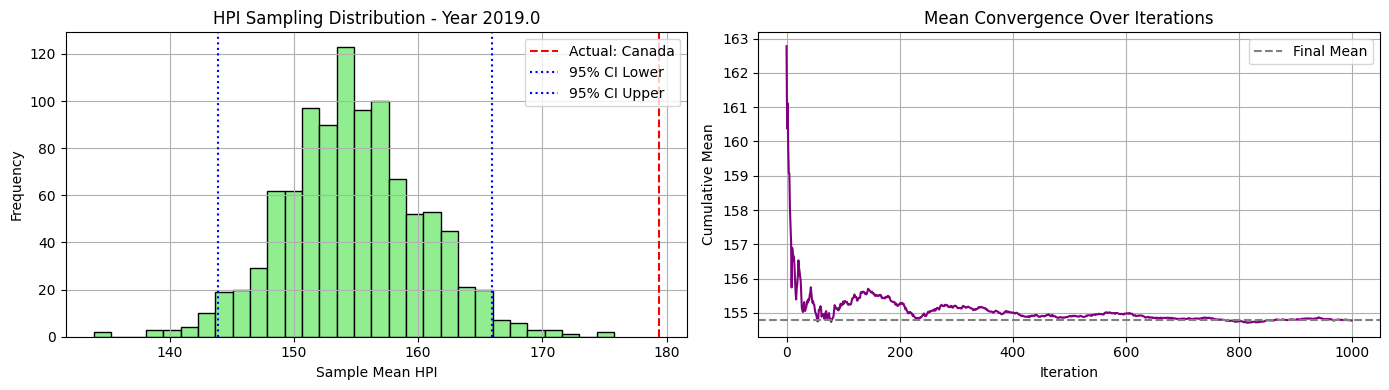


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 213.74 203.12 161.56 136.24 116.89 162.48 190.63 213.74
 213.74 113.93 187.18 159.24 213.74 128.18 106.71 149.28 156.31 126.56
 165.09 160.6  213.74 139.24 163.52]


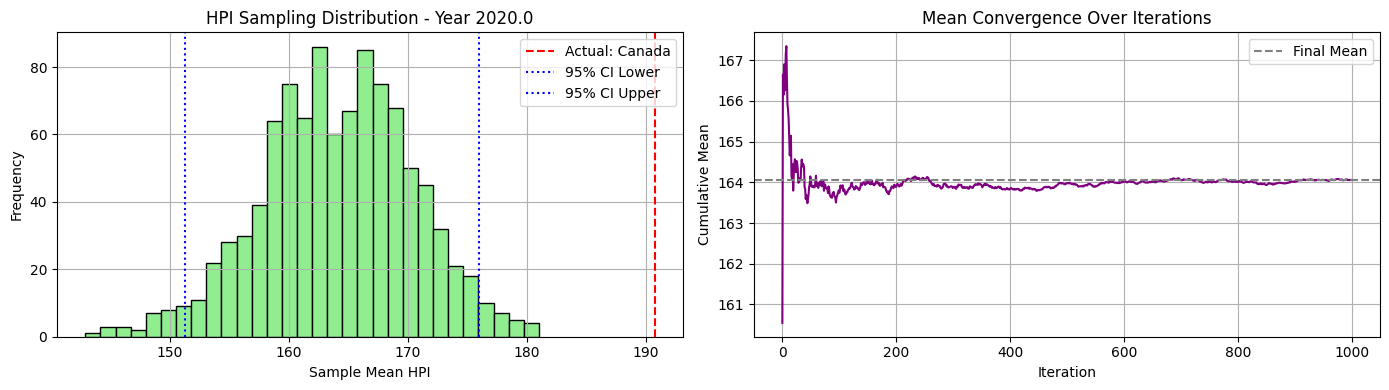


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 248.26 214.9  193.46 152.2  124.38 181.28 222.1  248.26
 248.26 120.7  201.94 175.91 211.74 139.92 121.41 166.04 166.82 143.73
 181.79 164.23 248.26 150.58 188.56]


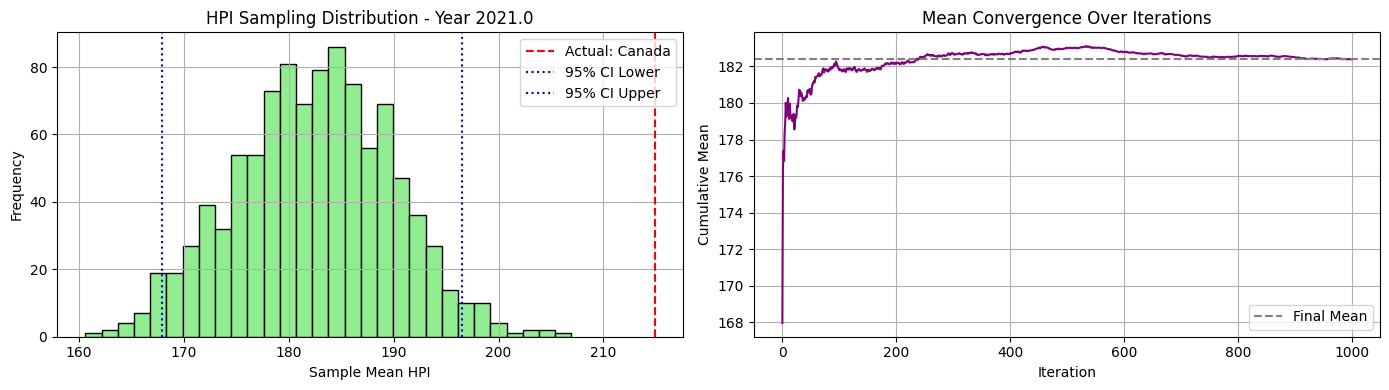


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 292.18 230.   226.15 151.49 132.1  190.42 271.5  292.18
 292.18 130.84 219.93 185.13 223.73 156.43 155.16 191.49 174.03 153.22
 188.27 169.16 292.18 164.55 213.  ]


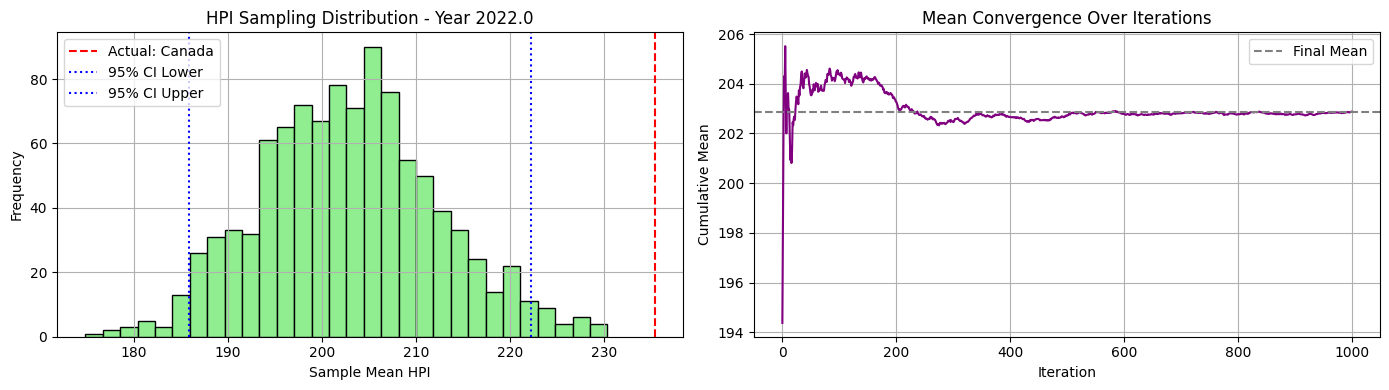


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 309.37 245.75 222.4  151.24 131.52 174.25 290.98 309.37
 309.37 134.8  243.89 184.12 248.04 170.23 157.88 209.99 176.62 143.99
 178.36 174.79 309.37 165.   221.72]


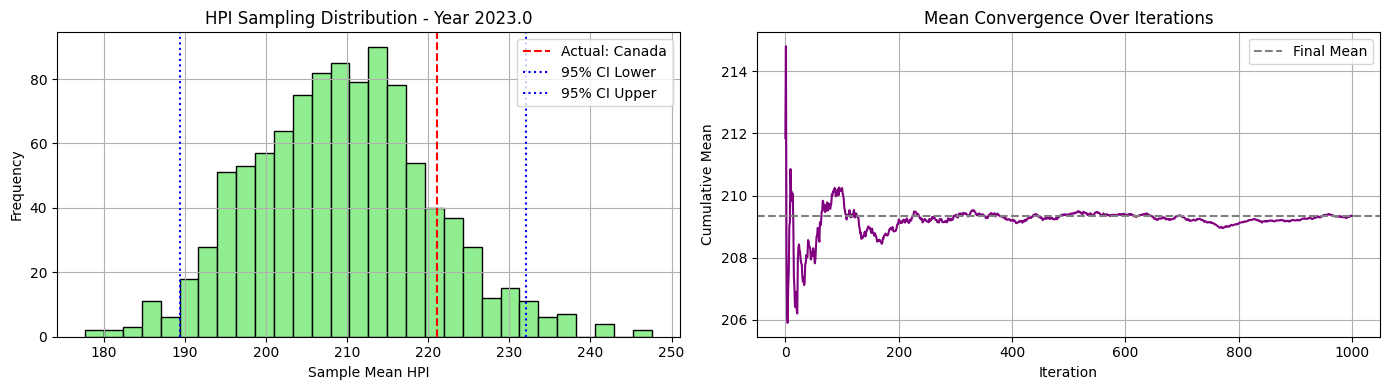


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 328.24 269.02 233.42 156.73 126.68 171.5  328.1  328.24
 328.24 138.61 266.38 189.05 256.03 195.72 186.66 220.7  178.1  142.46
 178.49 178.06 328.24 166.38 231.23]


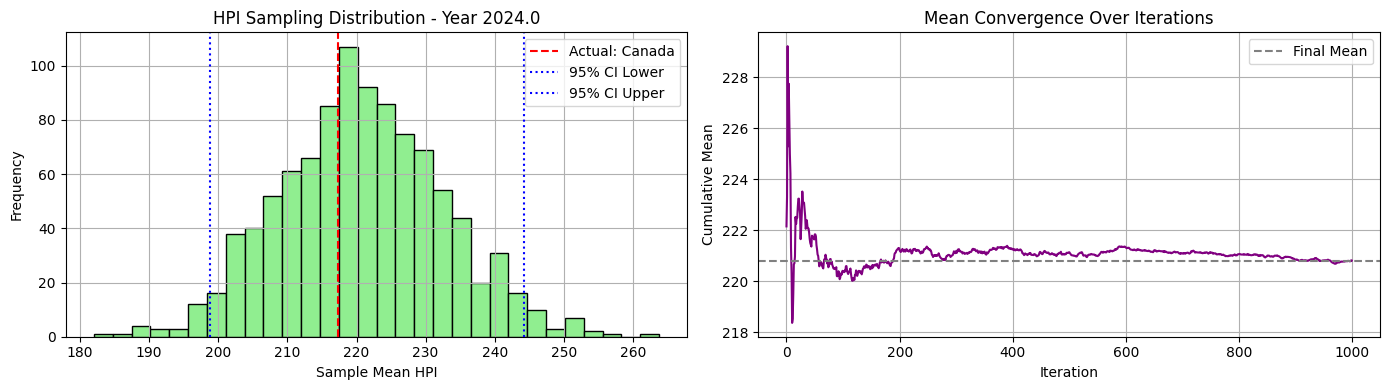

In [13]:
synthetic_c2_ni20_maxi500_h2_46_00, excluded_c2_ni20_maxi500_h2_46_00, actual_c2_ni20_maxi500_h2_46_00 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=0, seed=46)

🔍 Cluster 1 selected. Excluding country: Bulgaria
📊 Sampling from countries: ['Austria', 'Belgium', 'Croatia', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Israel', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Netherlands', 'New Zealand', 'Peru', 'Portugal', 'Romania', 'Singapore', 'Slovakia', 'Slovenia', 'Spain', 'Switzerland']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


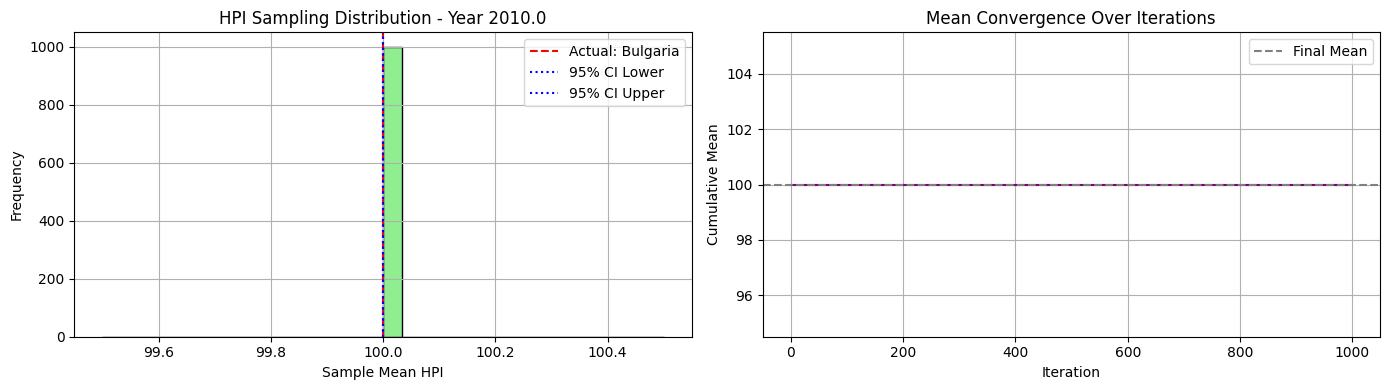


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58 100.16  96.68 108.47 103.17  94.53  94.49 110.52 101.36
 110.42 106.6  103.68 109.83  98.63  98.02 100.75 110.52  95.1   94.49
 109.46  98.46 102.72  94.49 107.51]


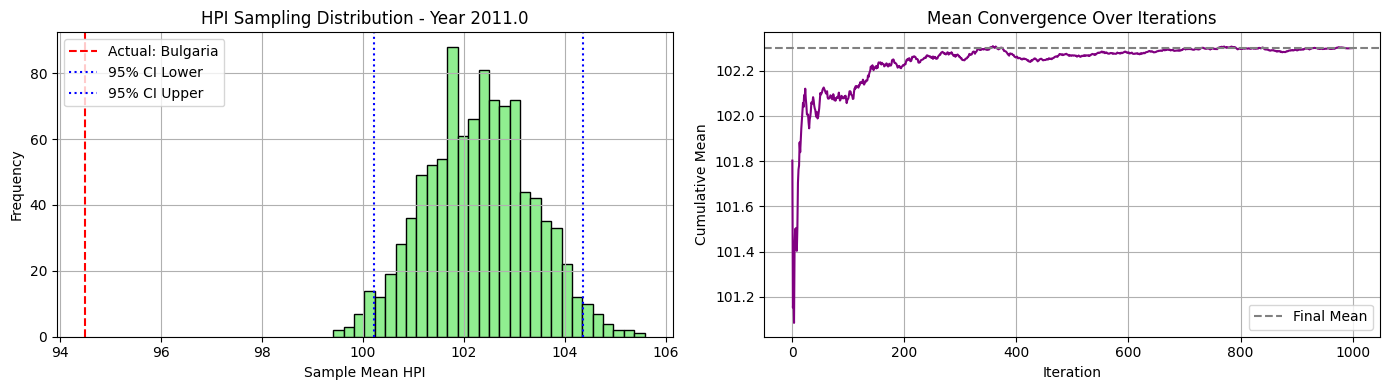


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  98.62  91.54 116.34 105.64  88.37  88.37 114.1   98.77
 113.71 106.36 108.03 124.02 101.62  91.44 105.25 124.02  88.37  88.37
 112.02  95.73  95.63  88.37 113.72]


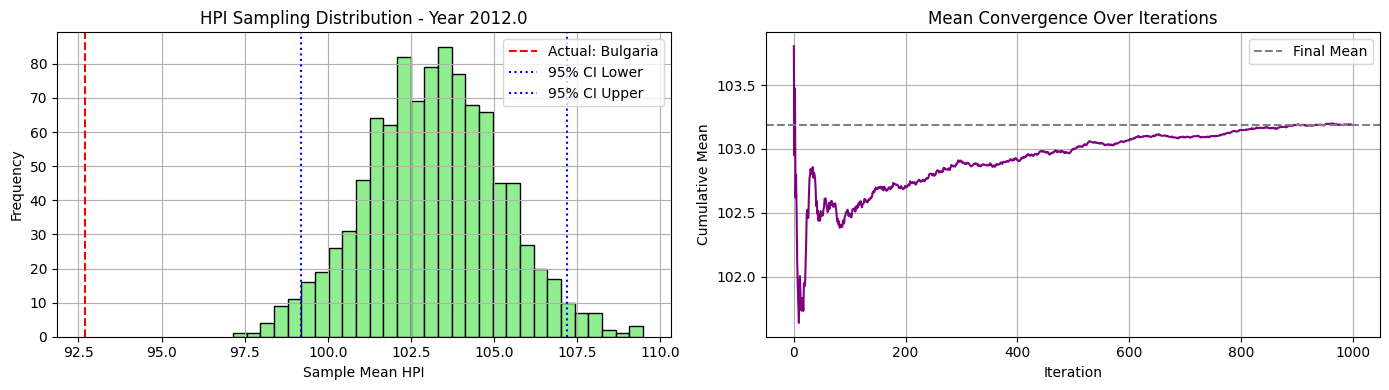


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  94.7   85.58 128.77 106.87  85.58  85.58 124.45  92.38
 121.5  107.65 113.42 136.52 101.21  85.95 114.59 136.52  86.7   85.58
 115.56  96.53  90.62  85.58 118.3 ]


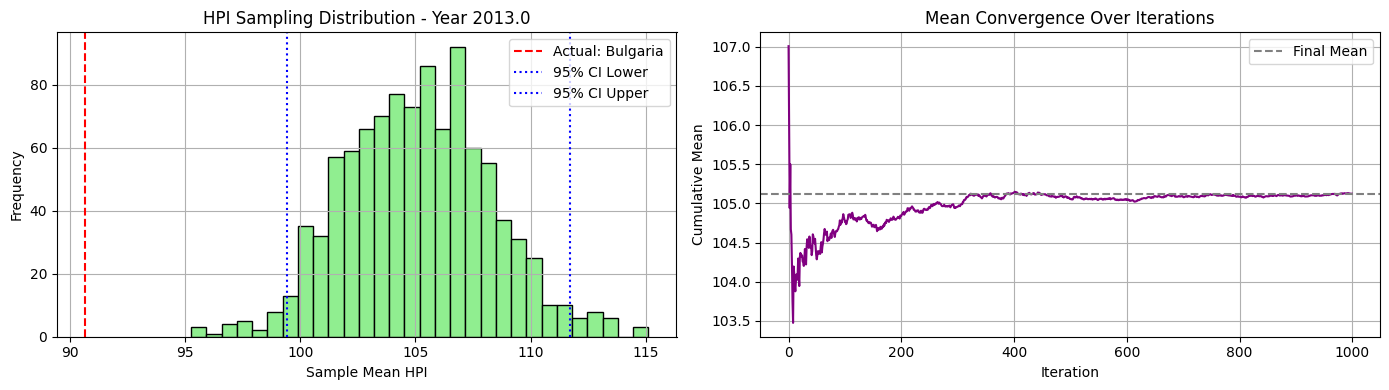


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  93.19  84.64 146.41 106.5   84.64  84.66 132.36  88.02
 128.78 114.57 118.39 151.67 103.79  86.66 122.03 151.67  90.38  84.64
 112.25  97.8   84.64  84.64 121.46]


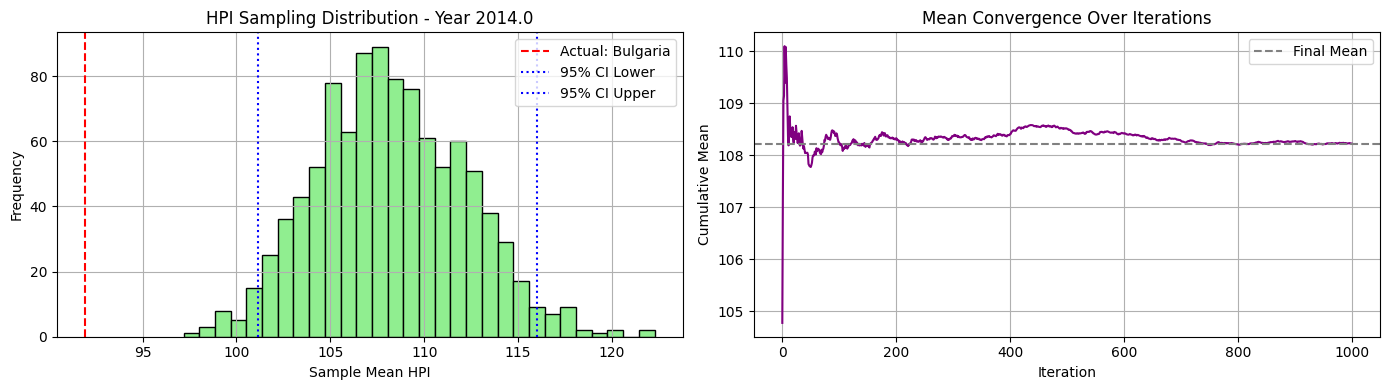


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  90.54  84.67 156.46 106.5   84.67  94.36 140.12  84.67
 124.46 118.76 124.78 162.89 109.83  89.69 137.18 162.89  93.15  84.67
 107.92 103.    85.32  84.67 124.08]


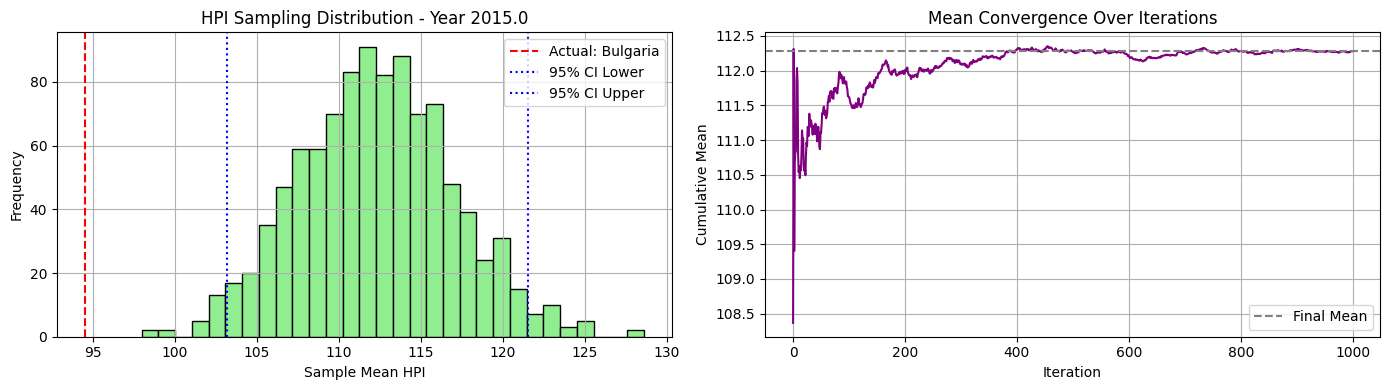


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72  91.33  88.1  163.86 107.86  88.1  101.42 150.56  88.1
 135.02 125.16 132.28 172.75 115.82  94.43 156.62 164.18  99.78  88.91
 104.55 109.87  88.1   88.1  124.32]


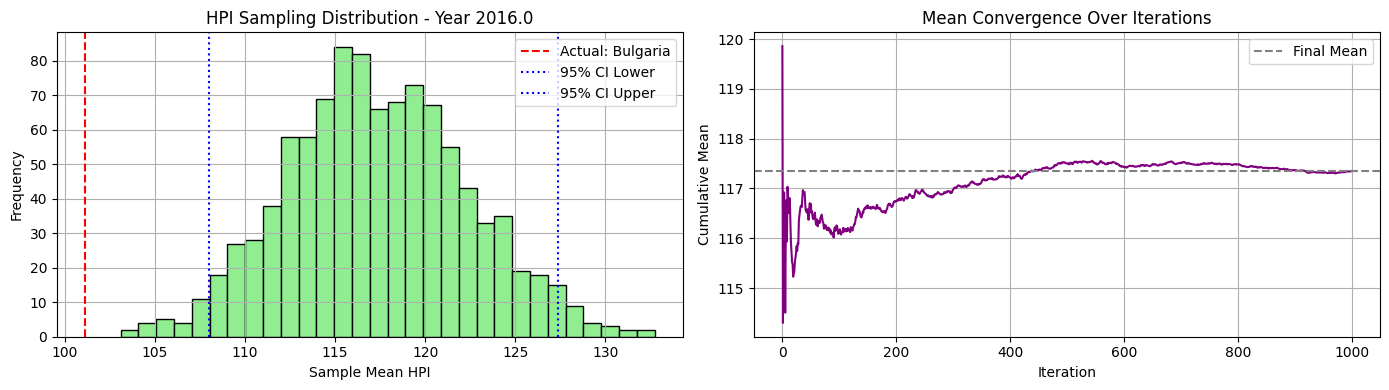


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66  94.84  88.54 172.91 109.02  88.54 112.44 156.44  88.54
 146.87 136.34 139.69 183.99 121.94 102.06 166.8  168.   108.99  93.93
 103.4  116.3   95.38  88.54 125.42]


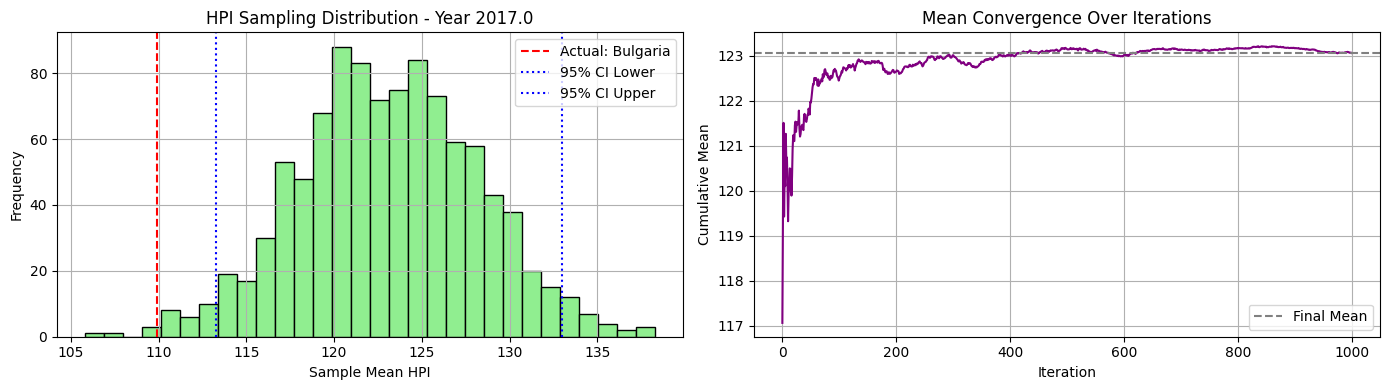


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 100.59  90.72 183.13 110.06  90.72 123.96 155.14  90.72
 160.92 146.29 149.55 191.85 129.02 111.57 172.8  168.42 120.19  99.37
 111.46 124.97 103.7   90.72 129.16]


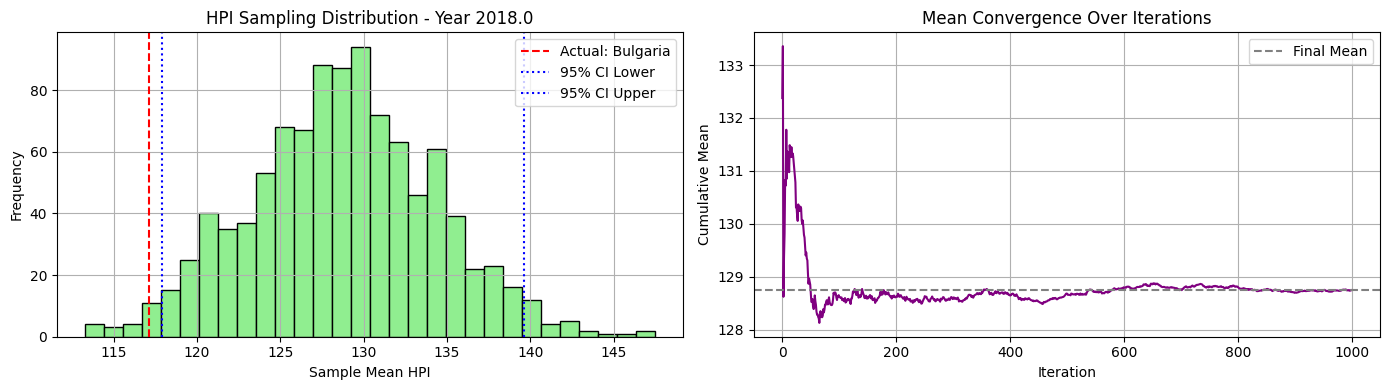


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 109.64  97.25 195.98 110.52  97.25 126.85 158.06  97.25
 175.33 156.3  164.68 196.06 136.9  119.62 178.19 172.03 132.16 102.72
 113.98 136.39 110.65  97.25 133.99]


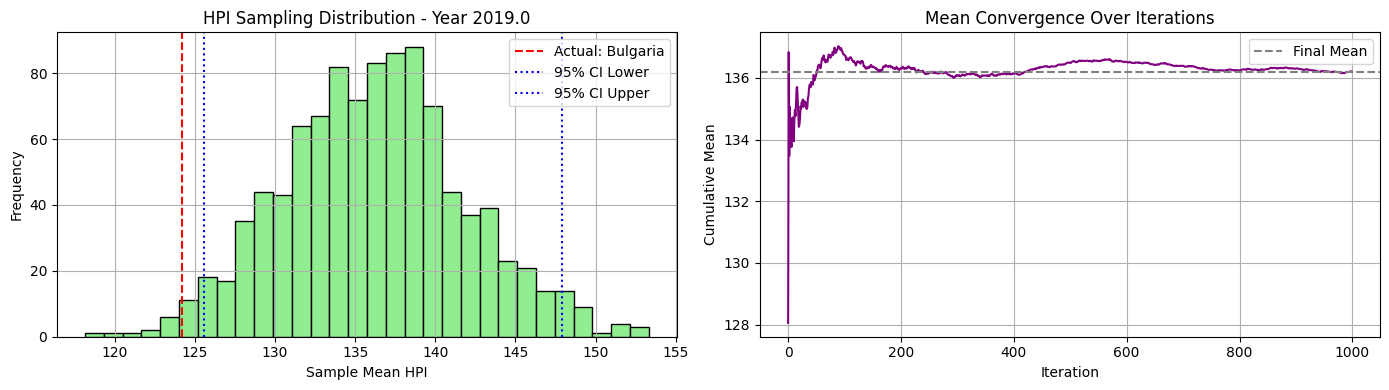


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 118.06 106.71 207.78 112.49 106.71 127.24 162.9  106.71
 181.42 167.66 188.57 198.37 141.54 129.21 196.31 173.67 143.75 107.53
 115.8  149.36 115.74 106.71 137.31]


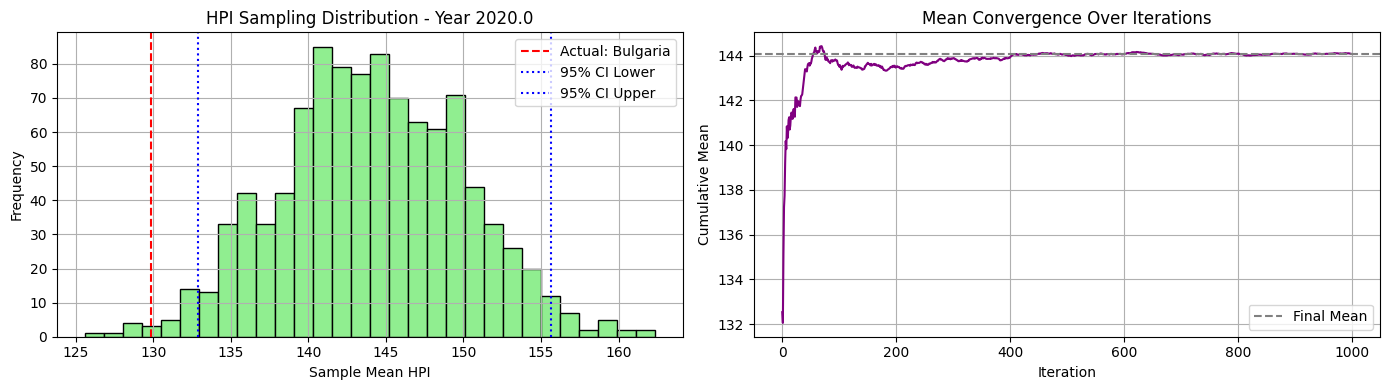


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 126.64 112.34 239.04 117.62 112.34 137.77 176.65 112.34
 201.18 194.58 214.81 200.69 148.74 147.93 248.26 173.6  157.27 112.34
 125.04 158.94 129.1  112.34 145.16]


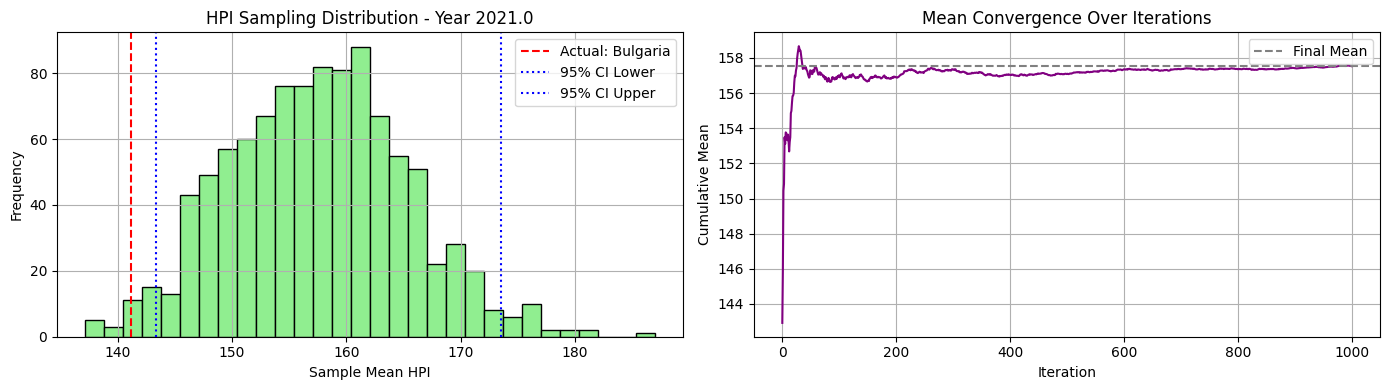


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 145.44 118.98 292.18 118.98 118.98 154.73 207.16 118.98
 229.01 231.64 235.34 207.75 158.62 167.57 249.69 172.65 177.14 120.29
 137.74 180.7  148.16 118.98 154.42]


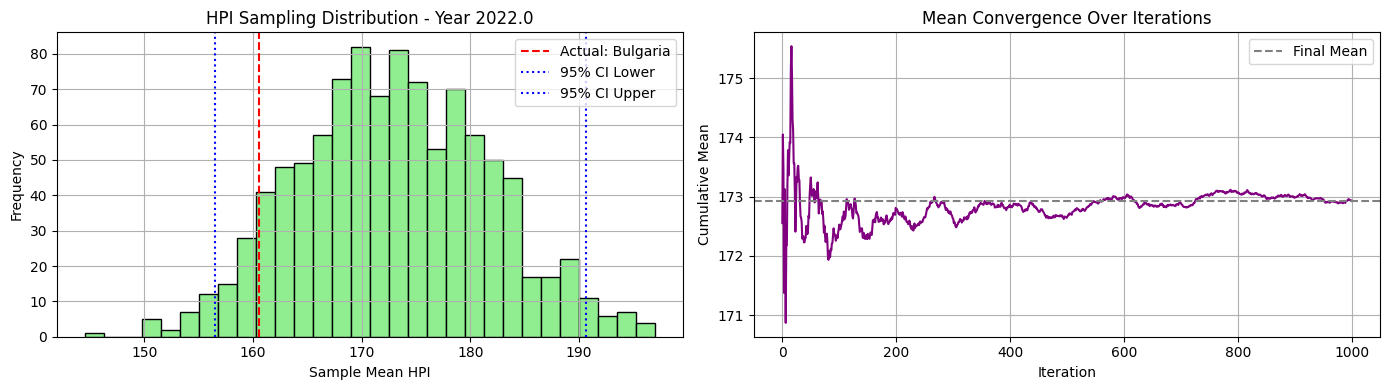


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 162.82 112.27 309.37 112.27 112.27 159.48 214.23 112.27
 237.56 254.38 214.   216.19 168.5  164.36 233.54 175.16 191.66 124.06
 148.01 180.36 158.88 112.27 157.81]


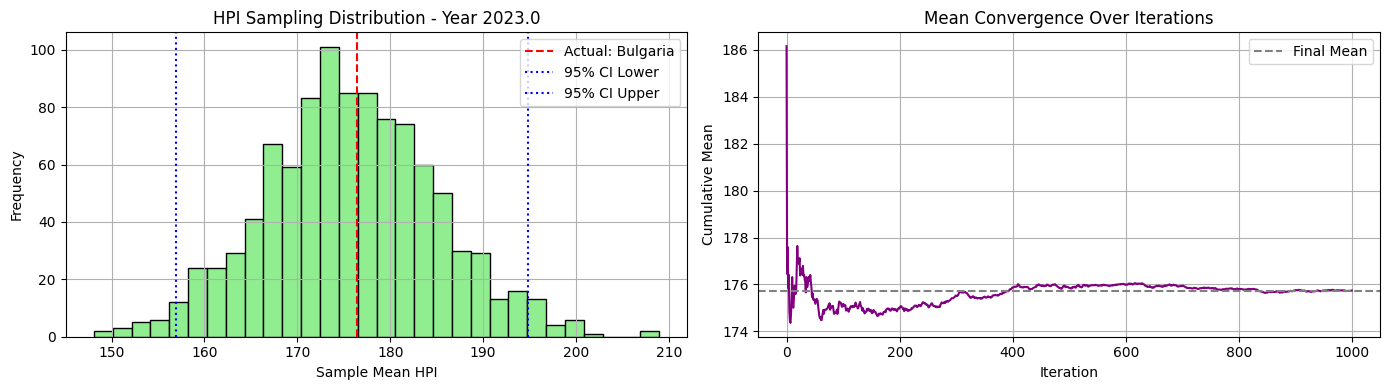


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 179.7  119.1  328.24 119.1  119.1  173.07 224.54 119.1
 247.54 279.12 202.74 225.06 179.35 177.7  233.68 175.38 209.06 130.34
 155.12 187.15 170.56 119.1  160.56]


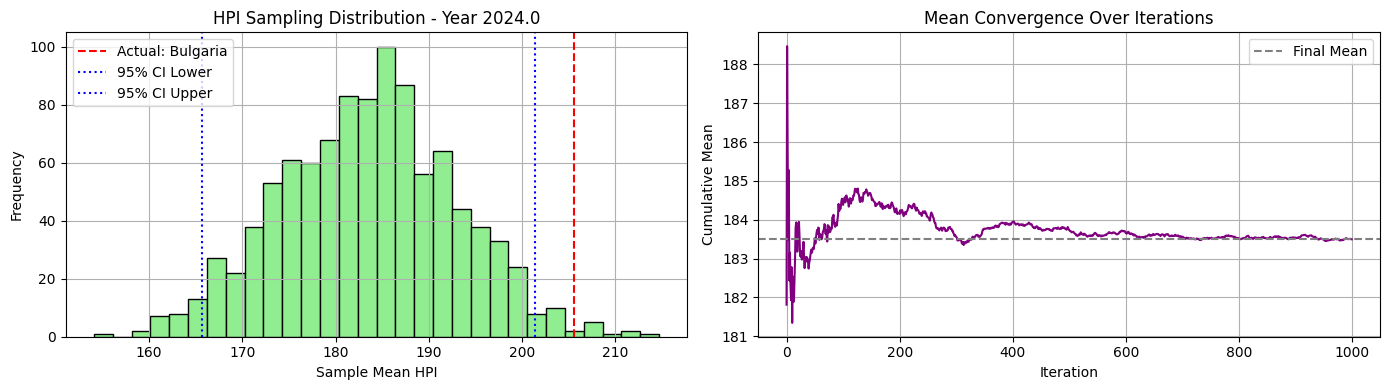

In [14]:
synthetic_c2_ni20_maxi500_h2_46_01, excluded_c2_ni20_maxi500_h2_46_01, actual_c2_ni20_maxi500_h2_46_01 = estimate_hpi_by_cluster_sampling(df_hpi_winsorized, clusters_c2_ni20_maxi500_h2, cluster_id=1, seed=46)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [15]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [16]:
def compute_global_mse_mae(synthetic_dicts, actual_dicts):
    """
    Computes global MSE and MAE across multiple synthetic vs. actual HPI dictionaries.

    Parameters:
    - synthetic_dicts: list of dicts with synthetic HPI values per year
    - actual_dicts: list of dicts with actual HPI values per year

    Returns:
    - mse: Mean Squared Error
    - mae: Mean Absolute Error
    """

    y_true = []
    y_pred = []

    for synth, actual in zip(synthetic_dicts, actual_dicts):
        common_years = set(synth.keys()) & set(actual.keys())
        for year in common_years:
            s_val = synth[year]
            a_val = actual[year]
            if not (np.isnan(s_val) or np.isnan(a_val)):
                y_pred.append(s_val)
                y_true.append(a_val)

    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    return mse, mae

In [17]:
import re

def evaluate_all_seeds(synthetic_groups, actual_groups):
    """
    Evaluates multiple sets of synthetic vs. actual HPI dictionaries,
    and stores error metrics in a dictionary keyed by seed number.

    Parameters:
    - synthetic_groups: dict with keys like 'synthetic_42' and values as lists of synthetic dicts
    - actual_groups: dict with keys like 'actual_42' and values as lists of actual dicts

    Returns:
    - metrics_by_seed: dict with seed as key and {'mse': ..., 'mae': ...} as value
    """
    metrics_by_seed = {}

    for synthetic_key in synthetic_groups:
        # Extract seed number from the synthetic key
        match = re.search(r'_(\d+)$', synthetic_key)
        if not match:
            raise ValueError(f"Could not extract seed from key: {synthetic_key}")
        
        seed = int(match.group(1))
        actual_key = f'actual_{seed}'  # construct matching key for actual_groups

        if actual_key not in actual_groups:
            raise KeyError(f"Missing key in actual_groups: {actual_key}")

        synthetic_dicts = synthetic_groups[synthetic_key]
        actual_dicts = actual_groups[actual_key]

        mse, mae = compute_global_mse_mae(synthetic_dicts, actual_dicts)
        metrics_by_seed[seed] = {'mse': mse, 'mae': mae}

    return metrics_by_seed

In [18]:
def summarize_error_metrics(metrics_by_seed):
    """
    Computes the mean and median of MSE and MAE values across multiple seeds.

    Parameters:
    - metrics_by_seed: dictionary with seed as key and {'mse': ..., 'mae': ...} as value

    Returns:
    - summary: dictionary with keys 'mse_mean', 'mse_median', 'mae_mean', 'mae_median'
    """
    mse_values = [metrics['mse'] for metrics in metrics_by_seed.values()]
    mae_values = [metrics['mae'] for metrics in metrics_by_seed.values()]

    summary = {
        'mse_mean': np.mean(mse_values),
        'mse_median': np.median(mse_values),
        'mae_mean': np.mean(mae_values),
        'mae_median': np.median(mae_values)
    }

    return summary

In [19]:
a = [synthetic_c2_ni20_maxi500_h2_23_00, synthetic_c2_ni20_maxi500_h2_23_01]
b = [actual_c2_ni20_maxi500_h2_23_00, actual_c2_ni20_maxi500_h2_23_01]

c = [synthetic_c2_ni20_maxi500_h2_32_00, synthetic_c2_ni20_maxi500_h2_32_01]
d = [actual_c2_ni20_maxi500_h2_32_00, actual_c2_ni20_maxi500_h2_32_01]

e = [synthetic_c2_ni20_maxi500_h2_46_00, synthetic_c2_ni20_maxi500_h2_46_01]
f = [actual_c2_ni20_maxi500_h2_46_00, actual_c2_ni20_maxi500_h2_46_01]

In [20]:
synth_c2_ni20_maxi500_h2 = {
    'synthetic_32': a,
    'synthetic_43': c,
    'synthetic_52': e
}

actual_c2_ni20_maxi500_h2 = {
    'actual_32': b,
    'actual_43': d,
    'actual_52': f
}

In [21]:
results_c2_ni20_maxi500_h2 = evaluate_all_seeds(synth_c2_ni20_maxi500_h2, actual_c2_ni20_maxi500_h2)

In [100]:
for seed, metrics in results_c2_ni20_maxi500_h2.items():
    print(f"🔢 Seed {seed} → MSE: {metrics['mse']:.4f}, MAE: {metrics['mae']:.4f}")

🔢 Seed 32 → MSE: 1111.5981, MAE: 27.5034
🔢 Seed 43 → MSE: 280.1628, MAE: 13.3638
🔢 Seed 52 → MSE: 280.4425, MAE: 13.3631


In [22]:
for seed, metrics in results_c2_ni20_maxi500_h2.items():
    print(f"🔢 Seed {seed} → MSE: {metrics['mse']:.4f}, MAE: {metrics['mae']:.4f}")

🔢 Seed 32 → MSE: 1111.5981, MAE: 27.5034
🔢 Seed 43 → MSE: 280.1628, MAE: 13.3638
🔢 Seed 52 → MSE: 280.4425, MAE: 13.3631


In [23]:
summary_c2_ni20_maxi500_h2 = summarize_error_metrics(results_c2_ni20_maxi500_h2)

In [24]:
print("📈 Error Summary Across Seeds:")
print(f"Mean MSE: {summary_c2_ni20_maxi500_h2['mse_mean']:.4f}")
print(f"Median MSE: {summary_c2_ni20_maxi500_h2['mse_median']:.4f}")
print(f"Mean MAE: {summary_c2_ni20_maxi500_h2['mae_mean']:.4f}")
print(f"Median MAE: {summary_c2_ni20_maxi500_h2['mae_median']:.4f}")

📈 Error Summary Across Seeds:
Mean MSE: 557.4012
Median MSE: 280.4425
Mean MAE: 18.0768
Median MAE: 13.3638


### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [1]:
import pandas as pd

In [25]:
from datetime import datetime

In [2]:
log_df = pd.read_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')

In [46]:
pd.set_option('display.max_columns', None)

In [3]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,...,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook
25,kmeans_plusplus_c2_ni20_maxi500_h2_3_countries...,2025-09-16 18:52,None,52,KMeans,2,k-means++,20.0,500.0,42,...,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,557.401153,18.076755,None
26,kmeans_plusplus_c2_ni20_maxi500_h2_same_seeds_...,2025-09-16 18:52,None,52,KMeans,2,k-means++,20.0,500.0,42,...,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,276.897625,12.785992,hypothesis_test_19.ipynb
27,kmeans_plusplus_c2_ni20_maxi500_diff_and_3dele...,2025-09-16 21:11,None,50,KMeans,2,k-means++,20.0,500.0,42,...,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,1518.505534,32.821709,hypothesis_test_22.ipynb
28,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-16 21:39,None,50,KMeans,2,k-means++,20.0,500.0,42,...,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352,hypothesis_test_23.ipynb
29,kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_c...,2025-09-17 15:31,None,48,KMeans,2,k-means++,20.0,500.0,42,...,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,266.390743,12.178599,hypothesis_test_24.ipynb


In [48]:
new_entry_c2_ni20_maxi500_h2 = {
    'experiment_name': 'kmeans_plusplus_c2_ni20_maxi500_h2_3_countries_exclude',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': 0.448165,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': 'Winsorization',
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'bootstrap',
    'mse_score': summary_c2_ni20_maxi500_h2['mse_mean'],
    'mae_score': summary_c2_ni20_maxi500_h2['mae_mean'],
    'sampling_seed': (23,32,46),
    'excluded_countries_count': 3,
    'used_all_variables_for_clustering': h2,
    'used_pca_for_clustering': False,
    "premacroecon_conversion_transform": None,
    "countries_used_for_clustering": 53
}

In [49]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry_c2_ni20_maxi500_h2])], ignore_index=True)

In [4]:
log_df.loc[25, "source_notebook"] = "hypothesis_test_18.ipynb"

In [5]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,...,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook
25,kmeans_plusplus_c2_ni20_maxi500_h2_3_countries...,2025-09-16 18:52,None,52,KMeans,2,k-means++,20.0,500.0,42,...,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,557.401153,18.076755,hypothesis_test_18.ipynb
26,kmeans_plusplus_c2_ni20_maxi500_h2_same_seeds_...,2025-09-16 18:52,None,52,KMeans,2,k-means++,20.0,500.0,42,...,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,276.897625,12.785992,hypothesis_test_19.ipynb
27,kmeans_plusplus_c2_ni20_maxi500_diff_and_3dele...,2025-09-16 21:11,None,50,KMeans,2,k-means++,20.0,500.0,42,...,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[23, 32, 46]",3.0,1518.505534,32.821709,hypothesis_test_22.ipynb
28,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-16 21:39,None,50,KMeans,2,k-means++,20.0,500.0,42,...,True,False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352,hypothesis_test_23.ipynb
29,kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_c...,2025-09-17 15:31,None,48,KMeans,2,k-means++,20.0,500.0,42,...,"['gdp', 'inflation_df', 'agr_land', 'livestock...",False,"Winsorization, rounding",Winsorization,bootstrap,"[32, 43, 52]",3.0,266.390743,12.178599,hypothesis_test_24.ipynb


In [6]:
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)


In [7]:
log_df.to_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')